<div style="background:#FFFFFF;border:1px solid #D9EEF2;border-top:5px solid #0095B7;border-radius:16px;padding:22px 26px 18px">
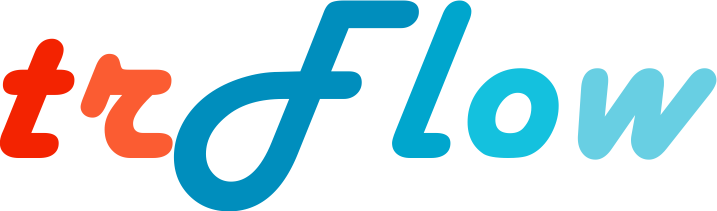
<p><font color="#163E4A" size="5"><b>Explore protein conformations.</b></font></p>
<p style="color:#52717B;margin:0 0 18px">From one A3M alignment to a structural ensemble.</p>
<table width="100%" cellspacing="0" cellpadding="10" style="border:0;table-layout:fixed">
<tr>
<td bgcolor="#087F9C" height="62" align="center" valign="middle" style="border:0"><font color="#FFFFFF" size="3"><b>A3M → ensemble</b></font><br><font color="#DDF7FC" size="2">Optional starting PDB</font></td>
<td bgcolor="#10AFC5" height="62" align="center" valign="middle" style="border:0"><font color="#FFFFFF" size="3"><b>Interactive 3D</b></font><br><font color="#E5FCFF" size="2">Play · align · overlay</font></td>
<td bgcolor="#F4693E" height="62" align="center" valign="middle" style="border:0"><font color="#FFFFFF" size="3"><b>Ready to export</b></font><br><font color="#FFF1E9" size="2">All PDBs + PyMOL</font></td>
</tr>
</table>
<p style="color:#52717B;margin:16px 0 0"><b>Step 1</b> Set up &nbsp; → &nbsp; <b>Step 2</b> Upload &nbsp; → &nbsp; <b>Step 3</b> Generate &nbsp; → &nbsp; <b>Step 4</b> Explore &nbsp; → &nbsp; <b>Step 5</b> Download</p>
</div>

**Before you start:** select a **GPU** runtime, then run the cells in order with ▶. Default: **100 conformations**. Save your ZIP before disconnecting.


## <font color="#078DAF">Step 1</font> · Set up
Run **1a**, then **1b**, once per runtime. The first model download is about **1.6 GB**.


In [ ]:
# @title Step 1a · Prepare GPU runtime { display-mode: "form" }
# @markdown <div style="background:#F0FAFC;border-left:3px solid #099ABC;border-radius:7px;padding:9px 13px;color:#385C68;font-size:13px">Prepare the environment. Continue to <b>1b</b> when ready.</div>
from pathlib import Path
import sys,os,time,importlib.util
ROOT = Path('/content/trflow_colab')
ROOT.mkdir(parents=True,exist_ok=True)
STATUS_SOURCE = r'''"""Small, non-widget notebook status panels and append-only diagnostic logs.

Only the Python standard library is imported at module import time. IPython is
loaded lazily when a Status is created inside a live notebook. ``feed`` records
meaningful upstream events; callers should retain raw model output separately.
"""

from datetime import datetime, timezone
from html import escape
import math
import os
from pathlib import Path
import re
import shlex
import subprocess
import time
import traceback
import uuid


_STAGES = {
    1: "Initial structure and representations",
    2: "Geometric exploration",
    3: "Conformation generation",
}
_STAGE_LINE = re.compile(r"^\[([123])/3\]\s+(.+?)\s+::\s+(.+?)\s*$")
_CLI_TIME = re.compile(
    r"^(?:Prediction finished in (?P<plain>[0-9]+(?:\.[0-9]+)?)s|"
    r"SUCCESS[ \t]+Prediction finished in (?P<success>[0-9]+(?:\.[0-9]+)?)s"
    r"\. Results: (?P<results>.+))$"
)
_WARNING = re.compile(r"\b(?:WARNING|UserWarning)\b")
_ANSI = re.compile(r"\x1b(?:\[[0-?]*[ -/]*[@-~]|\][^\x07]*(?:\x07|\x1b\\))")
# Deliberately narrow: merely mentioning OpenFold is not a progress event.
_OPENFOLD = re.compile(
    r"^(?:Running OpenFold(?:\.\.\.)?|Starting OpenFold(?:\.\.\.)?|"
    r"OpenFold (?:started|running|finished|completed)(?: in [0-9]+(?:\.[0-9]+)?s)?\.?|"
    r"> Running OpenFold \(model_[1-5](?:_ptm)?\) on (?:cpu|cuda(?::[0-9]+)?))$",
    re.IGNORECASE,
)


def _text(value):
    return value.decode("utf-8", errors="backslashreplace") if isinstance(value, bytes) else str(value)


def _short(value, limit=220):
    text = " ".join(_ANSI.sub("", _text(value)).split())
    text = "".join(character for character in text if character.isprintable())
    return text if len(text) <= limit else text[: limit - 1] + "…"


def format_duration(seconds):
    """Format measured elapsed seconds, without implying an ETA."""
    seconds = float(seconds)
    if not math.isfinite(seconds) or seconds < 0:
        raise ValueError("Duration must be finite and non-negative")
    rounded = int(seconds + 0.5)
    hours, remainder = divmod(rounded, 3600)
    minutes, secs = divmod(remainder, 60)
    if hours:
        return f"{hours}h {minutes:02d}m {secs:02d}s"
    if minutes:
        return f"{minutes}m {secs:02d}s"
    return f"{secs}s"


def _append(log_path, text):
    path = Path(log_path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("a", encoding="utf-8", errors="backslashreplace") as stream:
        stream.write(_text(text))
        if not _text(text).endswith("\n"):
            stream.write("\n")
        stream.flush()


def _notebook_display():
    """Return optional display functions only for an active notebook kernel."""
    try:
        from IPython import get_ipython

        shell = get_ipython()
        if shell is None or not hasattr(shell, "kernel"):
            return None
        from IPython.display import HTML, display, update_display

        return HTML, display, update_display
    except ImportError:
        return None


class Status:
    """One bounded rich panel, with concise plain-text output outside notebooks.

    ``fields`` are merged across updates and replaced by the final ``done``
    summary. All original messages/field values are
    logged; only their on-screen representations are bounded and HTML-escaped.
    ``warnings`` retains each warning event, including repeats. Only ``done``
    marks completion: CLI completion messages still require output verification.
    """

    def __init__(self, title, log_path):
        self.title = _text(title)
        self.log_path = Path(log_path)
        self.message = "Starting"
        self.state = "running"
        self.fields = {}
        self.stage = None
        self.stage_number = None
        self.target = None
        self.cli_seconds = None
        self.warnings = []
        self._started = time.monotonic()
        self._finished = None
        self._display = _notebook_display()
        self._display_id = "trflow-status-" + uuid.uuid4().hex
        self._display_created = False
        self._last_signature = None
        self._last_render = float("-inf")
        self.note("START: " + self.title)
        self._render()

    @property
    def elapsed_seconds(self):
        end = self._finished if self._finished is not None else time.monotonic()
        return max(0.0, end - self._started)

    @property
    def warning_summary(self):
        count = len(self.warnings)
        if not count:
            return "No warnings recorded"
        noun = "warning" if count == 1 else "warnings"
        return f"{count} {noun}; latest: {_short(self.warnings[-1], 180)}"

    def note(self, text):
        """Append a complete event immediately, without adding notebook output."""
        stamp = datetime.now(timezone.utc).isoformat(timespec="seconds")
        _append(self.log_path, f"[{stamp}] {_text(text)}")

    def update(self, message, fields=None):
        self.message = _text(message)
        if fields is not None:
            self.fields.update(fields)
        self.note("UPDATE: " + self.message + ("\nFIELDS: " + repr(fields) if fields is not None else ""))
        self._render()

    def feed(self, line):
        """Consume a real upstream event; ignore noisy/tqdm lines entirely.

        Returns True for recognized events, False otherwise. Raw subprocess
        output belongs in a separate inference log maintained by the caller.
        """
        original = _text(line)
        clean = _ANSI.sub("", original).strip()
        warning = _WARNING.search(clean)
        if warning:
            self.warnings.append(clean)
            self.note("WARNING EVENT: " + original)
            # Bound redraws during warning storms; terminal/stage updates always
            # include the current total. Nothing is dropped from the log/list.
            self._render(min_interval=0.5 if len(self.warnings) > 1 else 0)
            return True
        match = _STAGE_LINE.fullmatch(clean)
        if match and _STAGES[int(match.group(1))] == match.group(3):
            self.note("UPSTREAM: " + original)
            if self.state == "running":
                self.stage_number = int(match.group(1))
                self.target = match.group(2)
                self.stage = match.group(3)
                self.message = self.stage
                self._render()
            return True
        match = _CLI_TIME.fullmatch(clean)
        if match:
            seconds = float(match.group("plain") or match.group("success"))
            if not math.isfinite(seconds):
                return False
            self.note("UPSTREAM: " + original)
            self.cli_seconds = seconds
            if self.state == "running":
                self.message = "Prediction finished; checking outputs"
                self._render()
            return True
        if _OPENFOLD.fullmatch(clean):
            self.note("UPSTREAM: " + original)
            if self.state == "running":
                self.message = clean
                self._render()
            return True
        return False

    def done(self, message, fields=None):
        self.state = "done"
        self._finished = time.monotonic()
        self.message = _text(message)
        self.fields = dict(fields) if fields is not None else {}
        self.note("DONE: " + self.message + ("\nFIELDS: " + repr(fields) if fields is not None else ""))
        self._render()

    def fail(self, error, hint=""):
        """Log the full chained traceback and return a short RuntimeError text.

        The caller remains responsible for raising, usually with
        ``raise RuntimeError(status.fail(error, hint)) from None``. This method
        does not swallow, raise, replace or mutate the original exception.
        """
        if not isinstance(error, BaseException):
            raise TypeError("fail expects an exception instance")
        self.state = "error"
        self._finished = time.monotonic()
        detail = _short(f"{type(error).__name__}: {error}", 240)
        self.message = detail + (" · " + _short(hint, 220) if hint else "")
        self.note("FAILED: " + self.title)
        self.note("".join(traceback.format_exception(type(error), error, error.__traceback__)))
        if hint:
            self.note("HINT: " + _text(hint))
        self._render()
        separator = " " if self.message.endswith((".", "!", "?")) else ". "
        return f"{_short(self.title, 90)}: {self.message}{separator}Full log: {self.log_path}"

    def _signature(self):
        return (
            self.state, self.message, tuple((_text(k), _text(v)) for k, v in self.fields.items()),
            self.stage_number, self.target, self.cli_seconds, len(self.warnings),
        )

    def _html(self):
        safe = lambda value, limit=220: escape(_short(value, limit), quote=True)
        labels = {"running": "Running", "done": "Complete", "error": "Needs attention"}
        colors = {"running": "#475569", "done": "#166534", "error": "#9a3412"}
        compact_summary = self.state == "done" and any(
            _text(key).strip().casefold() == "model time" for key in self.fields
        )
        rows = []
        if self.stage_number is not None and not compact_summary:
            rows.append(("Stage", f"{self.stage_number} of 3 · {self.stage}"))
        if self.target is not None and not compact_summary:
            rows.append(("Target", self.target))
        rows.extend(list(self.fields.items())[:8])
        if not compact_summary:
            rows.append(("Elapsed", format_duration(self.elapsed_seconds)))
        if self.cli_seconds is not None and not compact_summary:
            rows.append(("Model time", format_duration(self.cli_seconds)))
        detail = "".join(
            '<div style="color:#64748b">' + safe(key, 60) + '</div><div style="overflow-wrap:anywhere">'
            + safe(value, 180) + "</div>" for key, value in rows
        )
        warning_html = (
            '<div style="margin-top:10px;color:#92400e;font-size:12px">'
            + (f"{len(self.warnings)} warning{'s' if len(self.warnings) != 1 else ''} recorded"
               if self.state == "done" else safe(self.warning_summary, 240))
            + ". Full warning text is in the log.</div>"
            if self.warnings else ""
        )
        return (
            '<div role="status" aria-live="polite" style="font-family:system-ui,sans-serif;'
            'font-size:14px;line-height:1.5;max-width:860px;padding:16px 18px;margin:8px 0;'
            'border:1px solid #dbe1e8;border-radius:12px;background:#fff;color:#17212f">'
            '<div style="display:flex;gap:16px;justify-content:space-between;align-items:baseline">'
            '<strong style="overflow-wrap:anywhere">' + safe(self.title, 100) + '</strong>'
            '<span style="font-size:12px;font-weight:600;white-space:nowrap;color:' + colors[self.state]
            + '">' + labels[self.state] + '</span></div><div style="margin-top:6px;overflow-wrap:anywhere">'
            + safe(self.message, 460) + '</div><div style="display:grid;grid-template-columns:100px minmax(0,1fr);'
            'column-gap:12px;row-gap:3px;margin-top:12px;font-size:12px">' + detail + '</div>'
            + warning_html + '<details style="margin-top:12px;border-top:1px solid #eef0f3;padding-top:8px;'
            'font-size:11px;color:#64748b"><summary style="cursor:pointer">Full log</summary>'
            '<div style="margin-top:5px;overflow-wrap:anywhere">'
            + escape(_text(self.log_path), quote=True) + '</div></details></div>'
        )

    def _render(self, min_interval=0):
        signature = self._signature()
        now = time.monotonic()
        if signature == self._last_signature or now - self._last_render < min_interval:
            return
        if self._display is not None:
            html, display, update_display = self._display
            try:
                payload = html(self._html())
                if self._display_created:
                    update_display(payload, display_id=self._display_id)
                else:
                    display(payload, display_id=self._display_id)
                    self._display_created = True
            except Exception as error:
                # A rendering-only failure must not replace an operational error.
                self.note("Display fallback: " + repr(error))
                self._display = None
        if self._display is None:
            label = {"running": "Running", "done": "Complete", "error": "Needs attention"}[self.state]
            suffix = f" · {len(self.warnings)} warning(s)" if self.warnings else ""
            print(f"{_short(self.title, 80)} · {label} · {_short(self.message, 240)}"
                  f" · {format_duration(self.elapsed_seconds)}{suffix}", flush=True)
            if self.state in {"done", "error"}:
                print("Full log: " + _short(self.log_path, 240), flush=True)
        self._last_signature = signature
        self._last_render = now


def _command_text(args, options):
    if isinstance(args, (str, bytes, os.PathLike)):
        command = os.fsdecode(args)
        if options.get("shell"):
            return shlex.join([os.fsdecode(options.get("executable") or "/bin/sh"), "-c", command])
        return shlex.quote(command)
    return shlex.join(os.fsdecode(argument) for argument in args)


def logged_command(args, log_path, **kwargs):
    """Run a command quietly and append its complete output and exit status.

    By default stdout/stderr are sent directly to the append-only log file, so
    output is available while the child runs (subject to its own buffering).
    The returned CompletedProcess then has stdout/stderr=None. Explicit PIPE or
    capture_output=True keeps subprocess.run capture semantics: captured streams
    are appended when run returns or raises. cwd, env, check, timeout, input,
    encoding, text and other run arguments are forwarded unchanged; check=True
    is the default. External output destinations/DEVNULL are rejected so output
    cannot silently escape the complete log or flood the notebook.
    """
    options = dict(kwargs)
    check = options.pop("check", True)
    capture = options.pop("capture_output", False)
    if capture and ("stdout" in options or "stderr" in options):
        raise ValueError("stdout and stderr arguments may not be used with capture_output")
    for name in ("stdout", "stderr"):
        allowed = (None, subprocess.PIPE) + ((subprocess.STDOUT,) if name == "stderr" else ())
        if name in options and options[name] not in allowed:
            raise ValueError("logged_command owns output destinations; use capture_output=True instead")
    path = Path(log_path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("ab", buffering=0) as stream:
        def write(value):
            data = value if isinstance(value, bytes) else _text(value).encode("utf-8", errors="backslashreplace")
            stream.write(data)
            if not data.endswith(b"\n"):
                stream.write(b"\n")
            stream.flush()

        def captured(result):
            for name in ("stdout", "stderr"):
                value = getattr(result, name, None)
                if value is not None:
                    write("--- " + name + " ---")
                    write(value)

        write("\n$ " + _command_text(args, options))
        if options.get("cwd") is not None:
            write("Working directory: " + os.fsdecode(options["cwd"]))
        if capture:
            options["stdout"] = subprocess.PIPE
            options["stderr"] = subprocess.PIPE
        else:
            if options.get("stdout") is None:
                options["stdout"] = stream
            if options.get("stderr") is None:
                options["stderr"] = stream
        try:
            result = subprocess.run(args, check=check, **options)
        except subprocess.CalledProcessError as error:
            captured(error)
            write(f"--- Command failed: exit {error.returncode} ---")
            raise
        except subprocess.TimeoutExpired as error:
            captured(error)
            write(f"--- Command timed out after {error.timeout}s ---")
            raise
        except BaseException as error:
            write("".join(traceback.format_exception(type(error), error, error.__traceback__)))
            raise
        captured(result)
        write(f"--- Exit {result.returncode} ---")
        return result
'''
(ROOT/'trflow_notebook_status.py').write_text(STATUS_SOURCE)
spec=importlib.util.spec_from_file_location('trflow_notebook_status',ROOT/'trflow_notebook_status.py')
ns=importlib.util.module_from_spec(spec);sys.modules[spec.name]=ns;spec.loader.exec_module(ns)
if 'ns' not in globals(): raise RuntimeError('Run Step 1a · Prepare GPU runtime first.')
_cell_status=ns.Status('Step 1a · Prepare GPU runtime',ROOT/'diagnostics'/'setup.log')
_cell_started_at=time.monotonic()
try:
    _cell_status.update('Checking GPU and workspace')
    from pathlib import Path
    import os, sys, subprocess, json, hashlib, shutil, datetime, importlib.util
    ROOT = Path('/content/trflow_colab')
    ROOT.mkdir(parents=True, exist_ok=True)
    REPO = ROOT / 'repo'
    REPO_URL = 'https://github.com/YangLab-SDU/trFlow.git'
    REPO_SHA = '405a143284d9dfc68f786170c7fff94860330fde'
    def run(args, **kwargs):
        return ns.logged_command(args,log_path=_cell_status.log_path,**kwargs)
    _cell_status.note('Host Python: '+sys.version)
    run(['nvidia-smi', '--query-gpu=name,memory.total,driver_version', '--format=csv'])
    _cell_status.note('Free disk GiB: '+str(round(shutil.disk_usage(ROOT).free/2**30,1)))
    if not REPO.exists():
        run(['git','clone', REPO_URL, REPO])
    # Never follow an unpinned branch on reruns.
    if subprocess.check_output(['git','-C',str(REPO),'status','--porcelain']).strip():
        raise RuntimeError('Repository has local edits; keep a separate copy rather than overwrite them')
    origin = subprocess.check_output(['git','-C',str(REPO),'remote','get-url','origin']).decode().strip()
    if origin != REPO_URL:
        raise RuntimeError('Unexpected repository origin; keep the existing checkout unchanged')
    if subprocess.run(['git','-C',str(REPO),'cat-file','-e',REPO_SHA+'^{commit}'],stdout=subprocess.PIPE,stderr=subprocess.PIPE).returncode:
        run(['git','-C',REPO,'fetch','--no-tags','origin',REPO_SHA])
    run(['git','-C',REPO,'checkout','--detach',REPO_SHA])
    assert subprocess.check_output(['git','-C',str(REPO),'rev-parse','HEAD']).decode().strip()==REPO_SHA

    _cell_status.update('Installing the isolated model environment')
    BOOTSTRAP=ROOT/'bootstrap'
    run([sys.executable,'-m','pip','install','--target',BOOTSTRAP,'uv==0.8.22'])
    UV_ENV=dict(os.environ, PYTHONPATH=str(BOOTSTRAP), UV_CACHE_DIR=str(ROOT/'uv_cache'),
                UV_PYTHON_INSTALL_DIR=str(ROOT/'python'))
    UV=[sys.executable,'-m','uv']
    ENV=ROOT/'venv'; PY=ENV/'bin/python'
    if not PY.exists(): run(UV+['venv','--python','3.11',str(ENV)],env=UV_ENV)
    run(UV+['pip','install','--python',str(PY),'torch==2.6.0+cu118',
            '--index-url','https://download.pytorch.org/whl/cu118'],env=UV_ENV)
    PINNED_REQUIREMENTS = 'numpy==1.26.4\nscipy==1.13.1\nbiopython==1.80\neinops==0.8.1\nml-collections==1.0.0\nabsl-py==2.2.2\npytorch-lightning==2.5.1\ntorchmetrics==1.7.1\ntqdm==4.67.1\ndm-tree==0.1.9\n'
    (ROOT/'requirements-colab.txt').write_text(PINNED_REQUIREMENTS)
    run(UV+['pip','install','--python',str(PY),'--only-binary=dm-tree','-r',str(ROOT/'requirements-colab.txt')],env=UV_ENV)
    MODEL_ENV={key:value for key,value in os.environ.items() if key not in ('PYTHONPATH','PYTHONHOME')}
    # Source-tree invocation avoids modifying the repository and its package metadata.
    run([PY,'-c',"import torch, numpy, Bio, pytorch_lightning; import trflow.core; print(torch.__version__,numpy.__version__); assert torch.cuda.is_available(), 'No CUDA GPU'; print(torch.cuda.get_device_name(0))"],cwd=REPO,env=MODEL_ENV)
    run([PY,'run_trflow.py','predict','--help'],cwd=REPO,env=MODEL_ENV)
    run([PY,'openfold/run_pretrained_openfold_multi.py','--help'],cwd=REPO,env=MODEL_ENV)
    run([PY,'-m','unittest','discover','-s','tests','-v'],cwd=REPO,env=MODEL_ENV)
    (ROOT/'pip-freeze.txt').write_text(subprocess.check_output([str(PY),'-m','pip','freeze']).decode() if subprocess.run([str(PY),'-m','pip','--version'],capture_output=True).returncode==0 else subprocess.check_output(UV+['pip','freeze','--python',str(PY)],env=UV_ENV).decode())
    HELPER_SOURCE = (
    r'''"""Small standard-library-only preflight/cache helpers; no model changes."""
from pathlib import Path
import hashlib, json, math, re, tarfile, shutil, tempfile

REPO_SHA = '405a143284d9dfc68f786170c7fff94860330fde'
WEIGHTS = ('trflow_xray.pth', 'trflow_nmr.pth', 'esm_msa1_t12_100M_UR50S.pt', 'openfold_params_model_5_ptm.npz')
AA = set('ACDEFGHIKLMNPQRSTVWYX')
THREE = dict(zip('ALA CYS ASP GLU PHE GLY HIS ILE LYS LEU MET ASN PRO GLN ARG SER THR VAL TRP TYR UNK'.split(), 'ACDEFGHIKLMNPQRSTVWYX'))

def sha256(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(8*1024*1024), b''): h.update(block)
    return h.hexdigest()

def validate_a3m(path):
    records=[]; header=None; parts=[]
    for line in Path(path).read_text().splitlines():
        line=line.strip()
        if not line: continue
        if line.startswith('>'):
            if header is not None: records.append((header,''.join(parts)))
            header=line[1:].strip(); parts=[]
            if not header: raise ValueError('Empty A3M header')
        else:
            if header is None: raise ValueError('A3M must begin with >query')
            parts.append(line)
    if header is not None: records.append((header,''.join(parts)))
    if not records or not records[0][1]: raise ValueError('Empty A3M')
    query=records[0][1]
    if set(query)-AA: raise ValueError('First A3M sequence must be uppercase, ungapped protein sequence (20 standard amino acids or X)')
    for i,(_,seq) in enumerate(records,1):
        if set(seq)-(AA|set('abcdefghijklmnopqrstuvwxyz')|{'-'}): raise ValueError(f'A3M record {i}: non-ASCII/unsupported residue')
        aligned=''.join(c for c in seq if c not in 'abcdefghijklmnopqrstuvwxyz')
        if len(aligned)!=len(query) or set(aligned)-(AA|{'-'}):
            raise ValueError(f'A3M record {i}: aligned columns/alphabet invalid; lowercase insertions are ignored, dots/colon/multimer headers are unsupported')
    return {'query':query,'length':len(query),'records':len(records),'sha256':sha256(path)}

def normalize_pdb(source, destination, query, chain=None):
    """Explicit single-chain full-length mapping; preserve source; renumber output 1..L."""
    if Path(source).resolve()==Path(destination).resolve(): raise ValueError('Normalized destination must differ from original input')
    lines=Path(source).read_text().splitlines()
    if sum(x.startswith('MODEL ') for x in lines)>1: raise ValueError('Provide a single-model PDB (extract the desired model first)')
    atoms=[x for x in lines if x.startswith('ATOM  ')]
    chains=sorted({x[21:22] for x in atoms})
    if chain is None:
        if len(chains)!=1: raise ValueError(f'Select one PDB chain explicitly; found {chains}')
        chain=chains[0]
    if chain not in chains: raise ValueError(f'PDB chain {chain!r} not found: {chains}')
    residues={}
    for x in atoms:
        if x[21:22]!=chain or x[16:17] not in (' ', 'A'): continue
        key=(x[22:26],x[26:27]); name=x[17:20].strip()
        if name not in THREE: raise ValueError(f'Unsupported residue {name}; map modified residues explicitly before upload')
        for offset in (30,38,46):
            if not math.isfinite(float(x[offset:offset+8])): raise ValueError('Non-finite PDB coordinate')
        record=residues.setdefault(key, {'name':name,'atoms':{}})
        if record['name']!=name: raise ValueError('Ambiguous residue identity')
        atom=x[12:16].strip()
        if atom in record['atoms']: raise ValueError('Duplicate/ambiguous alternate atom; provide a single conformer')
        record['atoms'][atom]=x
    sequence=''.join(THREE[r['name']] for r in residues.values())
    if sequence!=query: raise ValueError(f'PDB sequence must match the A3M target; PDB length {len(sequence)}, target length {len(query)}. Upload a complete matching chain.')
    output=[]; mapping=[]
    for idx,(key,r) in enumerate(residues.items(),1):
        needed={'CA'} if r['name']=='GLY' else {'CA','CB'}
        if needed-set(r['atoms']): raise ValueError(f'Residue {idx} lacks required CA/CB pseudo-beta atom')
        mapping.append({'query_position':idx,'source_chain':chain,'source_resseq':key[0].strip(),'source_icode':key[1].strip()})
        for x in r['atoms'].values():
            serial=len(output)+1
            if serial>99999 or idx>9999: raise ValueError('PDB fixed-width limits exceeded')
            output.append(f'{x[:6]}{serial:5d}{x[11:16]} {x[17:21]}A{idx:4d} {x[27:]}')
    Path(destination).write_text('\n'.join(output)+ '\nTER\nEND\n')
    Path(str(destination)+'.mapping.json').write_text(json.dumps(mapping,indent=2))
    return {'chain':chain,'length':len(sequence),'source_sha256':sha256(source),'normalized_sha256':sha256(destination)}

def extract_weights(archive, directory, max_expanded_bytes=12*1024**3):
    """Allowlisted atomic extraction; reject links, traversal and archive bombs."""
    directory=Path(directory); directory.mkdir(parents=True,exist_ok=True)
    found={}; total=0
    with tempfile.TemporaryDirectory(prefix='weight_staging_',dir=directory) as temp:
        staging=Path(temp)
        with tarfile.open(archive,'r:bz2') as tar:
            for member in tar:
                path=Path(member.name)
                if path.is_absolute() or '..' in path.parts or member.issym() or member.islnk():
                    raise ValueError('Unsafe archive member')
                if member.isdir(): continue
                if not member.isfile(): raise ValueError('Nonregular archive member')
                name=path.name
                if name not in WEIGHTS: raise ValueError(f'Unexpected archive file: {name}')
                if name in found: raise ValueError('Duplicate checkpoint')
                total+=member.size
                if member.size<=0 or total>max_expanded_bytes: raise ValueError('Archive exceeds configured size limit or has empty checkpoint')
                if shutil.disk_usage(directory).free < member.size+256*1024**2: raise ValueError('Insufficient extraction disk space')
                dest=staging/name
                with tar.extractfile(member) as src, open(dest,'wb') as out: shutil.copyfileobj(src,out,8*1024*1024)
                found[name]={'bytes':dest.stat().st_size,'sha256':sha256(dest)}
        if set(found)!=set(WEIGHTS): raise ValueError(f'Missing checkpoints: {set(WEIGHTS)-set(found)}')
        for name in WEIGHTS: (staging/name).replace(directory/name)
    (directory/'manifest.json').write_text(json.dumps(found,indent=2))
    return found

# Public author-hosted archive. Redirects must retain verified HTTPS on this host.
OFFICIAL_WEIGHTS_URL = 'https://yanglab.qd.sdu.edu.cn/trFlow/pretrained_models.tar.bz2'
# Independently recorded from the complete HTTPS archive on 2026-10-05.
# These pins identify reviewed bytes; they are not author-published signatures.
OFFICIAL_ARCHIVE_BYTES = 1627013849
OFFICIAL_ARCHIVE_SHA256 = 'f0301f15271a5fdad0a84ee046907ef64ce8a69e72953b38af9e9b7b6ea329e6'
OFFICIAL_WEIGHT_MANIFEST = {
    'esm_msa1_t12_100M_UR50S.pt': {'bytes': 1378199982, 'sha256': 'cd932794cc2f23e179c7335a6f95a45199ba38a5f4b664976e77c8f71b2e6878'},
    'openfold_params_model_5_ptm.npz': {'bytes': 371746284, 'sha256': '2f8d0bd193e7d6e837958ba92acdc3f02b23b61bf841fa043fc076ee0e1996a5'},
    'trflow_nmr.pth': {'bytes': 119749792, 'sha256': '5774ec7bd4e5297a593c49f35e9af8947329897b925c96c183b4f4d23aa7f189'},
    'trflow_xray.pth': {'bytes': 119752653, 'sha256': 'ef48e7b60d7621eb62ceded9d762528ab5a9b384e4963c72f71afa120442ff53'},
}
OFFICIAL_WEIGHT_ALIASES = {'trx2flow_nmr.pth': 'trflow_nmr.pth', 'trx2flow_xray.pth': 'trflow_xray.pth'}
MAX_OFFICIAL_ARCHIVE_BYTES = 2 * 1024**3
MAX_OFFICIAL_EXPANDED_BYTES = 4 * 1024**3
WEIGHT_DISK_RESERVE = 512 * 1024**2


def _official_url(url):
    from urllib.parse import urlsplit
    parts = urlsplit(url)
    if (parts.scheme != 'https' or parts.hostname != 'yanglab.qd.sdu.edu.cn'
            or parts.port not in (None, 443) or parts.username or parts.password
            or parts.path != '/trFlow/pretrained_models.tar.bz2' or parts.query or parts.fragment):
        raise ValueError('The model download must use the verified official HTTPS address.')
    return url


def _official_opener():
    import ssl
    from urllib.request import build_opener, HTTPRedirectHandler, HTTPSHandler
    class OfficialRedirect(HTTPRedirectHandler):
        def redirect_request(self, req, fp, code, msg, headers, newurl):
            _official_url(newurl)
            return super().redirect_request(req, fp, code, msg, headers, newurl)
    return build_opener(HTTPSHandler(context=ssl.create_default_context()), OfficialRedirect())


def _unlinked_directory(path):
    path = Path(path).expanduser().absolute()
    for component in (path, *path.parents):
        if component.is_symlink():
            raise ValueError('Choose a runtime model-cache folder without linked directories.')
    path.mkdir(parents=True, exist_ok=True)
    if not path.is_dir():
        raise ValueError('The model-cache path is not a folder.')
    return path


def _read_official_cache(directory):
    receipt = directory / 'current.json'
    if receipt.is_symlink():
        raise ValueError('The model-cache record must not be a link.')
    if not receipt.exists():
        return None
    try:
        if not receipt.is_file() or receipt.stat().st_size > 64 * 1024:
            return None
        record = json.loads(receipt.read_text())
        if record.get('schema_version') != 1 or record.get('source_url') != OFFICIAL_WEIGHTS_URL:
            return None
        name = record.get('directory', '')
        archive_hash = record.get('archive_sha256', '')
        archive_bytes = record.get('archive_bytes')
        if isinstance(archive_bytes, bool) or not isinstance(archive_bytes, int) or not 0 < archive_bytes <= MAX_OFFICIAL_ARCHIVE_BYTES:
            return None
        if OFFICIAL_ARCHIVE_SHA256 and archive_hash != OFFICIAL_ARCHIVE_SHA256:
            return None
        if OFFICIAL_ARCHIVE_BYTES and archive_bytes != OFFICIAL_ARCHIVE_BYTES:
            return None
        if not re.fullmatch(r'[0-9a-f]{64}', archive_hash):
            return None
        if not re.fullmatch(r'official-' + archive_hash + r'-[0-9a-f]{32}', name):
            return None
        root = directory / name
        if root.is_symlink() or not root.is_dir() or set(p.name for p in root.iterdir()) != set(WEIGHTS):
            return None
        files = record['files']
        if set(files) != set(WEIGHTS):
            return None
        total = 0
        for filename in WEIGHTS:
            path = root / filename
            row = files[filename]
            size = row['bytes']
            digest = row['sha256']
            if isinstance(size, bool) or not isinstance(size, int) or not 0 < size <= MAX_OFFICIAL_ARCHIVE_BYTES:
                return None
            if OFFICIAL_WEIGHT_MANIFEST and (size != OFFICIAL_WEIGHT_MANIFEST[filename]['bytes'] or digest != OFFICIAL_WEIGHT_MANIFEST[filename]['sha256']):
                return None
            total += size
            if total > MAX_OFFICIAL_EXPANDED_BYTES or not isinstance(digest, str) or not re.fullmatch(r'[0-9a-f]{64}', digest):
                return None
            if path.is_symlink() or not path.is_file() or path.stat().st_size != size or sha256(path) != digest:
                return None
        return root
    except (OSError, ValueError, TypeError, KeyError, AttributeError):
        return None


def _download_official_archive(destination, progress=None):
    """Stream public bytes to a staging file; never deserialize checkpoints."""
    import os, time
    from urllib.request import Request
    url = _official_url(OFFICIAL_WEIGHTS_URL)
    request = Request(url, headers={'User-Agent': 'trFlow-Colab/1.0', 'Accept-Encoding': 'identity'})
    total = 0
    started = time.monotonic()
    digest = hashlib.sha256()
    with _official_opener().open(request, timeout=60) as response:
        _official_url(response.geturl())
        if response.status != 200:
            raise ValueError('The official download did not return a complete file. Retry Prepare model files.')
        if response.headers.get('Content-Encoding', 'identity').lower() not in ('', 'identity'):
            raise ValueError('The model server returned an unsupported transfer encoding.')
        length = response.headers.get('Content-Length')
        expected = None
        if length is not None:
            if not re.fullmatch(r'[0-9]+', length.strip()):
                raise ValueError('The model server returned an invalid file size.')
            expected = int(length)
            if not 0 < expected <= MAX_OFFICIAL_ARCHIVE_BYTES:
                raise ValueError('The official archive exceeds the supported download size.')
            if OFFICIAL_ARCHIVE_BYTES and expected != OFFICIAL_ARCHIVE_BYTES:
                raise ValueError('The official model archive size has changed. Use the current notebook release or choose My Drive.')
        required = (expected or MAX_OFFICIAL_ARCHIVE_BYTES) + MAX_OFFICIAL_EXPANDED_BYTES + WEIGHT_DISK_RESERVE
        if shutil.disk_usage(destination.parent).free < required:
            raise ValueError(f'Not enough runtime storage for model files. Free at least {required / 1024**3:.1f} GiB and retry.')
        last_report = -1
        with open(destination, 'xb') as output:
            while True:
                block = response.read(8 * 1024**2)
                if not block:
                    break
                if time.monotonic() - started > 1800:
                    raise TimeoutError('The model download took longer than 30 minutes. Retry Prepare model files.')
                total += len(block)
                if total > MAX_OFFICIAL_ARCHIVE_BYTES or (expected is not None and total > expected):
                    raise ValueError('The download is larger than the announced file size.')
                if shutil.disk_usage(destination.parent).free < len(block) + WEIGHT_DISK_RESERVE:
                    raise ValueError('Runtime storage ran low during the model download. Free space and retry.')
                output.write(block); digest.update(block)
                bucket = int(100 * total / expected) // 5 if expected else total // (128 * 1024**2)
                if progress is not None and bucket != last_report:
                    progress(f'Downloading model files · {100 * total / expected:.0f}%' if expected else f'Downloading model files · {total / 1024**2:.0f} MiB')
                    last_report = bucket
            output.flush(); os.fsync(output.fileno())
    if not total or (expected is not None and total != expected):
        raise ValueError('The model download is incomplete. Retry Prepare model files.')
    if OFFICIAL_ARCHIVE_BYTES and total != OFFICIAL_ARCHIVE_BYTES:
        raise ValueError('The official model download has the wrong size. Retry Prepare model files.')
    if OFFICIAL_ARCHIVE_SHA256 and digest.hexdigest() != OFFICIAL_ARCHIVE_SHA256:
        raise ValueError('The official model archive checksum differs from the reviewed version. Retry or check for a notebook update.')
    with open(destination, 'rb') as stream:
        if stream.read(3) != b'BZh':
            raise ValueError('The download is not the expected model archive. Retry later or choose My Drive.')
    return {'bytes': total, 'sha256': digest.hexdigest()}


def _extract_official_archive(archive, destination):
    """Read all bzip2 bytes and allow only the four expected regular files."""
    import bz2, os
    from pathlib import PurePosixPath
    destination.mkdir()
    files = {}; total = 0; members = 0
    with bz2.BZ2File(archive, 'rb') as compressed:
        class LimitedReader:
            count = 0
            def read(self, size=-1):
                data = compressed.read(size)
                self.count += len(data)
                if self.count > MAX_OFFICIAL_EXPANDED_BYTES + 1024**2:
                    raise ValueError('The expanded model archive exceeds the supported size.')
                return data
        reader = LimitedReader()
        with tarfile.open(fileobj=reader, mode='r|') as tar:
            for member in tar:
                members += 1
                path = PurePosixPath(member.name)
                if (members > 64 or ':' in member.name or '\\' in member.name or '\x00' in member.name or path.is_absolute()
                        or '..' in path.parts or member.issym() or member.islnk() or member.issparse()):
                    raise ValueError('The model archive contains an unsafe entry.')
                if member.isdir():
                    continue
                if not member.isfile():
                    raise ValueError('The model archive contains an unsupported entry.')
                name = OFFICIAL_WEIGHT_ALIASES.get(path.name, path.name)
                if name not in WEIGHTS or name in files:
                    raise ValueError('The model archive has an unexpected or duplicate file: '+repr(member.name))
                total += member.size
                if not 0 < member.size <= MAX_OFFICIAL_ARCHIVE_BYTES or total > MAX_OFFICIAL_EXPANDED_BYTES:
                    raise ValueError('The extracted model files exceed the supported size.')
                if shutil.disk_usage(destination).free < member.size + WEIGHT_DISK_RESERVE:
                    raise ValueError('Not enough runtime storage to unpack the model files.')
                count = 0; digest = hashlib.sha256()
                with tar.extractfile(member) as source, open(destination / name, 'xb') as target:
                    while True:
                        chunk = source.read(8 * 1024**2)
                        if not chunk:
                            break
                        count += len(chunk)
                        if count > member.size:
                            raise ValueError('A model file is larger than its archive entry.')
                        target.write(chunk); digest.update(chunk)
                    target.flush(); os.fsync(target.fileno())
                if count != member.size:
                    raise ValueError('A model file is incomplete in the archive.')
                if OFFICIAL_WEIGHT_MANIFEST and (count != OFFICIAL_WEIGHT_MANIFEST[name]['bytes'] or digest.hexdigest() != OFFICIAL_WEIGHT_MANIFEST[name]['sha256']):
                    raise ValueError('A model file checksum differs from the reviewed version: '+name)
                files[name] = {'bytes': count, 'sha256': digest.hexdigest(), 'archive_name': member.name}
        # tar iteration can stop at its end marker before bzip2's checksum/end.
        # Consume the remainder so a truncated compressed stream is rejected.
        while reader.read(8 * 1024**2):
            pass
    if set(files) != set(WEIGHTS):
        raise ValueError('The model archive is missing required files.')
    return files


def ensure_official_weights(cache_dir, progress=None):
    """Return complete author-download weights with a verified runtime cache.

    HTTPS authenticates transport. Local hashes record the bytes received and
    detect cache corruption; they are not an author-published checksum. No model
    file is loaded/deserialized and existing cache generations are left intact.
    """
    import os, uuid
    directory = _unlinked_directory(cache_dir)
    if progress is not None:
        progress('Checking saved model files')
    cached = _read_official_cache(directory)
    if cached is not None:
        if progress is not None:
            progress('Using saved model files')
        return cached
    with tempfile.TemporaryDirectory(prefix='.prepare-', dir=directory) as temp:
        staging = Path(temp)
        archive = staging / 'official.tar.bz2'
        if progress is not None:
            progress('Downloading model files')
        downloaded = _download_official_archive(archive, progress)
        if progress is not None:
            progress('Unpacking and checking model files')
        extracted = staging / 'models'
        files = _extract_official_archive(archive, extracted)
        name = 'official-' + downloaded['sha256'] + '-' + uuid.uuid4().hex
        record = {'schema_version': 1, 'source_url': OFFICIAL_WEIGHTS_URL,
                  'archive_bytes': downloaded['bytes'], 'archive_sha256': downloaded['sha256'],
                  'directory': name, 'files': files}
        receipt = staging / 'current.json'
        with open(receipt, 'x') as output:
            json.dump(record, output, indent=2); output.write('\n'); output.flush(); os.fsync(output.fileno())
        target = directory / name
        if target.exists() or target.is_symlink() or (directory / 'current.json').is_symlink():
            raise ValueError('The model cache changed while preparing files. Retry with a new runtime cache.')
        os.replace(extracted, target)
        os.replace(receipt, directory / 'current.json')
    if progress is not None:
        progress('Model files ready')
    return target

def fingerprint(config):
    return hashlib.sha256(json.dumps(config,sort_keys=True).encode()).hexdigest()[:16]

def verify_completed(sample_dir, expected_count, expected_sequence=None):
    directory=Path(sample_dir)
    info=json.loads((directory/'info.json').read_text())
    predictions=info['predictions']
    if len(predictions)!=expected_count: raise ValueError('Incomplete prediction count')
    names=set()
    for item in predictions:
        name=item['file']
        if Path(name).name!=name or name in names: raise ValueError('Unsafe or duplicate prediction filename')
        names.add(name)
        path=directory/'predictions'/name
        if not path.is_file(): raise ValueError(f'Missing predicted structure: {name}')
        atoms=[x for x in path.read_text().splitlines() if x.startswith('ATOM  ')]
        if not atoms: raise ValueError(f'Empty predicted structure: {name}')
        for x in atoms:
            if len(x)<54 or any(not math.isfinite(float(x[i:i+8])) for i in (30,38,46)):
                raise ValueError(f'Malformed/non-finite coordinates: {name}')
        if expected_sequence is not None:
            with tempfile.TemporaryDirectory() as temp:
                normalize_pdb(path,Path(temp)/'check.pdb',expected_sequence)
    return info

def prepare_weight_directory(source, cache=None, expected_sizes=None, expected_manifest=None):
    """Read only source; optionally atomically copy exact weights into runtime cache.

    Never deserialize weights. Fingerprints are identity, not authenticity. Source
    is deliberately not modified, including when it is a mounted private Drive.
    """
    source=Path(source).expanduser().resolve()
    if not source.is_dir(): raise FileNotFoundError('Weight source directory does not exist')
    if list(source.glob('*-contact-regression.pt')):
        raise ValueError('Unexpected contact-regression checkpoint would be loaded implicitly')
    if expected_manifest is not None:
        if not isinstance(expected_manifest, dict) or set(expected_manifest) != set(WEIGHTS):
            raise ValueError('The pinned model manifest is incomplete. Rerun Step 1b · Prepare model files.')
        for row in expected_manifest.values():
            if (not isinstance(row, dict) or isinstance(row.get('bytes'), bool) or not isinstance(row.get('bytes'), int)
                    or row['bytes'] <= 0 or not isinstance(row.get('sha256'), str) or not re.fullmatch(r'[0-9a-f]{64}', row['sha256'])):
                raise ValueError('The pinned model manifest is invalid. Rerun Step 1b · Prepare model files.')
    manifest={}
    for name in WEIGHTS:
        p=source/name
        if not p.is_file() or p.is_symlink() or p.stat().st_size<=0:
            raise ValueError(f'Missing, empty or linked checkpoint: {name}')
        size=p.stat().st_size
        if expected_sizes and name in expected_sizes and size != expected_sizes[name]:
            raise ValueError(f'Checkpoint size differs from supplied manifest: {name}')
        manifest[name]={'bytes':size,'sha256':sha256(p)}
        if expected_manifest is not None and manifest[name] != expected_manifest[name]:
            raise ValueError('Prepared official model file differs from the pinned version: '+name+'. Rerun Step 1b · Prepare model files before Generate.')
    if cache is None: return source,manifest
    cache=Path(cache).expanduser().resolve()
    if cache==source: return source,manifest
    cache.mkdir(parents=True,exist_ok=True)
    if list(cache.glob('*-contact-regression.pt')):
        raise ValueError('Unexpected contact-regression checkpoint in cache')
    missing=[]
    for name in WEIGHTS:
        p=cache/name
        if p.is_symlink(): raise ValueError('Linked checkpoint in cache')
        if not (p.is_file() and p.stat().st_size==manifest[name]['bytes'] and sha256(p)==manifest[name]['sha256']):
            missing.append(name)
    if shutil.disk_usage(cache).free < sum(manifest[n]['bytes'] for n in missing)+256*1024**2:
        raise ValueError('Insufficient runtime disk space to copy checkpoints')
    with tempfile.TemporaryDirectory(prefix='copy_staging_',dir=cache) as temp:
        for name in missing:
            dest=Path(temp)/name
            shutil.copyfile(source/name,dest)
            if dest.stat().st_size!=manifest[name]['bytes'] or sha256(dest)!=manifest[name]['sha256']:
                raise ValueError(f'Checkpoint changed during copy: {name}')
        for name in missing: (Path(temp)/name).replace(cache/name)
    return cache,manifest

def export_results(destination, run_root, extras, *, structures=None):
    """Fresh atomic ZIP every time, no stale reuse; refuses symlinks and itself."""
    if structures is not None:
        return _export_readable_results(destination, run_root, extras, structures)
    import zipfile
    destination=Path(destination).resolve(); run_root=Path(run_root).resolve()
    paths=[]
    for p in sorted(run_root.rglob('*')):
        if p.is_symlink(): raise ValueError('Linked files are not exported')
        if p.is_file(): paths.append((p,'run/'+p.relative_to(run_root).as_posix()))
    paths.extend((Path(p),name) for p,name in extras)
    names=set()
    for p,name in paths:
        if p.is_symlink() or p.resolve()==destination: raise ValueError('Unsafe export source')
        if Path(name).is_absolute() or '..' in Path(name).parts or name in names: raise ValueError('Unsafe/duplicate archive name')
        names.add(name)
    destination.parent.mkdir(parents=True,exist_ok=True)
    fd,temp=tempfile.mkstemp(prefix='export_',suffix='.zip',dir=destination.parent)
    import os
    os.close(fd)
    try:
        with zipfile.ZipFile(temp,'w',zipfile.ZIP_DEFLATED) as z:
            for p,name in paths: z.write(p,name)
        Path(temp).replace(destination)
    finally:
        Path(temp).unlink(missing_ok=True)
    return destination


def _portable_member(name):
    """Validate ZIP names on every OS; no absolute local paths in manifests."""
    from pathlib import PurePosixPath
    name = str(name)
    if (not name or name.startswith('/') or '\\' in name
            or any(ord(c) < 32 for c in name) or any(c in name for c in ':*?"<>|')
            or any(p in ('', '.', '..') for p in name.split('/'))):
        raise ValueError('Unsafe archive member name: ' + repr(name))
    for part in PurePosixPath(name).parts:
        if part.endswith(('.', ' ')) or re.fullmatch(r'(?i)(CON|PRN|AUX|NUL|COM[1-9]|LPT[1-9])(?:\..*)?', part):
            raise ValueError('Archive member is not portable: ' + repr(name))
    return name


def numbered_structures(run_root, models):
    """Map verified current-attempt predictions to deterministic flat filenames.

    Ordering preserves the previous viewer's case-sensitive source-path ordering.
    Numbers identify files only; they are not rankings or chronological frames.
    Call before write_pymol_exports, then pass the same result as structures= to
    export_results. No source file is copied, renamed, aligned or overwritten.
    """
    root = Path(run_root).resolve()
    rows = []; seen = set()
    for model in models:
        source = Path(model['path'])
        if source.is_symlink() or not source.is_file():
            raise ValueError('Missing or linked predicted structure')
        resolved = source.resolve()
        try:
            relative = resolved.relative_to(root).as_posix()
        except ValueError as exc:
            raise ValueError('Predicted structure is outside the run directory') from exc
        original = _portable_member('run/' + relative)
        if resolved in seen or source.suffix.lower() != '.pdb':
            raise ValueError('Duplicate source or non-PDB predicted structure')
        seen.add(resolved)
        rows.append(dict(model, path=source, source_archive_name=original))
    rows.sort(key=lambda r: r['source_archive_name'])
    width = max(3, len(str(len(rows))))
    for i, row in enumerate(rows, 1):
        row['archive_name'] = 'structures/conformer_%0*d.pdb' % (width, i)
    return rows


def _export_readable_results(destination, run_root, extras, structures):
    """Archive each original source once, with a complete source-to-ZIP map."""
    import os, zipfile
    destination = Path(destination).resolve()
    root = Path(run_root)
    if root.is_symlink() or not root.is_dir():
        raise ValueError('Run directory is missing or linked')
    root = root.resolve()
    structures = list(structures)
    expected = numbered_structures(root, structures)
    expected_by_path = {Path(r['path']).resolve(): r for r in expected}
    for row in structures:
        correct = expected_by_path[Path(row['path']).resolve()]
        if (row.get('archive_name') != correct['archive_name']
                or row.get('source_archive_name') != correct['source_archive_name']):
            raise ValueError('Structure mapping changed; regenerate the PyMOL files before exporting')
    sources = []
    for path in sorted(root.rglob('*')):
        if path.is_symlink():
            raise ValueError('Linked files or directories are not exported')
        if path.is_file():
            sources.append((path, 'run/' + path.relative_to(root).as_posix(), 'run'))
        elif not path.is_dir():
            raise ValueError('Unsupported special file in run directory')
    sources.extend((Path(p), str(name), 'extra') for p, name in extras)
    seen_original = set(); names = {'readme.txt', 'structures/index.txt', 'details/archive_manifest.json'}
    paths = []; records = []; by_source = {}
    # Run sources go first, so an extra alias of a prediction uses structures/.
    for path, original, kind in sources:
        original = _portable_member(original)
        if original.casefold() in seen_original:
            raise ValueError('Duplicate or case-colliding original archive name')
        seen_original.add(original.casefold())
        if path.is_symlink() or not path.is_file() or path.resolve() == destination:
            raise ValueError('Unsafe or missing export source')
        resolved = path.resolve()
        if resolved in expected_by_path:
            name = expected_by_path[resolved]['archive_name']
        elif kind == 'extra' and original == 'view_ensemble.pml':
            name = original
        elif kind == 'extra' and original.startswith('details/'):
            name = original
        else:
            name = 'details/' + original
        name = _portable_member(name)
        if resolved in by_source:
            name, size, digest = by_source[resolved]
        else:
            if name.casefold() in names:
                raise ValueError('Duplicate or case-colliding destination archive name')
            names.add(name.casefold())
            size = path.stat().st_size; digest = sha256(path)
            by_source[resolved] = (name, size, digest)
            paths.append((path, name, size, digest))
        record = {'source_archive_name': original, 'archive_name': name,
                  'bytes': size, 'sha256': digest}
        if resolved in expected_by_path:
            record['role'] = 'verified_prediction'
            record['branch'] = str(expected_by_path[resolved].get('branch') or 'unspecified')
        else:
            record['role'] = 'preserved_run_file' if kind == 'run' else 'input_or_support_file'
        records.append(record)
    if not set(expected_by_path).issubset(by_source):
        raise ValueError('A predicted structure was missing from the run inventory')
    if 'view_ensemble.pml' not in names:
        raise ValueError('Missing top-level PyMOL script')
    manifest = {'format_version': 1, 'layout': 'trflow-readable-results-v1',
        'structure_count': len(structures), 'source_file_count': len(records),
        'stored_source_file_count': len(paths),
        'model_order': 'Case-sensitive lexicographic original run-relative path; numbering is identity only',
        'integrity': 'Every inventoried run/input/support file is stored byte-for-byte. Multiple references to one source file share one ZIP member. Original paths are archive-relative, never private absolute paths.',
        'generated_files': ['README.txt', 'structures/INDEX.txt', 'details/archive_manifest.json'],
        'files': sorted(records, key=lambda r: r['source_archive_name'])}
    readme = _results_readme(len(structures))
    destination.parent.mkdir(parents=True, exist_ok=True)
    fd, temporary = tempfile.mkstemp(prefix='export_', suffix='.zip', dir=destination.parent)
    os.close(fd)
    try:
        with zipfile.ZipFile(temporary, 'w', zipfile.ZIP_DEFLATED) as archive:
            archive.writestr('README.txt', readme)
            archive.writestr('structures/', b'')
            archive.writestr('structures/INDEX.txt', _structure_index(expected))
            for path, name, size, digest in sorted(paths, key=lambda p: p[1]):
                archive.write(path, name)
                # Fail atomically if a source changes during this export.
                if path.stat().st_size != size or sha256(path) != digest:
                    raise ValueError('Export source changed while archiving: ' + name)
            archive.writestr('details/archive_manifest.json', json.dumps(manifest, ensure_ascii=False, indent=2) + '\n')
        with zipfile.ZipFile(temporary) as archive:
            for _, name, size, digest in paths:
                h = hashlib.sha256()
                with archive.open(name) as stream:
                    for block in iter(lambda: stream.read(8*1024*1024), b''):
                        h.update(block)
                if archive.getinfo(name).file_size != size or h.hexdigest() != digest:
                    raise ValueError('ZIP integrity verification failed: ' + name)
        Path(temporary).replace(destination)
    finally:
        Path(temporary).unlink(missing_ok=True)
    return destination


def _structure_index(structures):
    """Plain-text, deterministic index; quoted fields escape control characters."""
    from pathlib import PurePosixPath
    lines = [
        'trFlow structure index (%d conformers)' % len(structures),
        'Numbered file | Original filename | Generation branch | Original source path',
        'File numbers follow the order in this index.',
        '',
    ]
    for row in structures:
        fields = (PurePosixPath(row['source_archive_name']).name,
                  str(row.get('branch') or 'unspecified'), row['source_archive_name'])
        lines.append(PurePosixPath(row['archive_name']).name + ' | ' +
                     ' | '.join(json.dumps(value, ensure_ascii=True).replace('|', '\\u007c') for value in fields))
    if not structures:
        lines.append('No complete ensemble was found. See details/ for the available run logs.')
    return '\n'.join(lines) + '\n'


def _results_readme(count):
    state = ('structures/ contains all %d conformers as numbered PDB files.' % count
             if count else 'DIAGNOSTIC EXPORT: no complete ensemble was found.\nPartial results and run logs are available under details/run/.')
    return ''' "'''"
    r'''trFlow results / 下载结果

%s
全部构象位于 structures/ 文件夹。

Open a structure: extract the ZIP, then open any structures/conformer_*.pdb.
Filename and generation-branch index: structures/INDEX.txt
原始文件名与生成分支对照：structures/INDEX.txt
PyMOL: extract the ENTIRE ZIP. In PyMOL, cd to this folder and run:
  @view_ensemble.pml
  trflow_next       next conformer
  trflow_overlay    compare the aligned overlay
请完整解压；在 PyMOL 中 cd 到本文件夹，再运行 @view_ensemble.pml。
Full PyMOL instructions: details/PYMOL_README.txt

More details
- Inputs, logs and run settings: details/
- Original filenames and file fingerprints: details/archive_manifest.json
- PyMOL conformer and branch mapping: details/pymol_manifest.json
- Alignment and interpretation notes: details/PYMOL_README.txt

The ZIP includes your input sequences and structures. Share it only with the
people who should have access to them.
''' "'''"
    r''' % state
'''
    )
    (ROOT/'trflow_colab_helper.py').write_text(HELPER_SOURCE)
    spec=importlib.util.spec_from_file_location('trflow_colab_helper', ROOT/'trflow_colab_helper.py')
    h=importlib.util.module_from_spec(spec); sys.modules[spec.name]=h; spec.loader.exec_module(h)

    _cell_status.update('Preparing notebook controls')
    from IPython.display import display
    USER_UI_SOURCE = r'''"""User-facing notebook controls; model implementation stays upstream."""
from pathlib import Path
import re


def sampling_options(count=100, advanced=None):
    if isinstance(count, bool) or not isinstance(count, int) or count < 1:
        raise ValueError('Number of conformations must be a positive whole number.')
    options=dict(sample_num=count, models=['Xray','NMR'], geometric_exploration=True,
                 single_step=False, steps=7, random_step=True, random_step_size=True,
                 parallel=False, save_repr_npz=False, seed=42)
    if advanced and advanced.get('enabled', False):
        selected=advanced.get('models', 'Xray,NMR')
        if selected not in ('Xray','NMR','Xray,NMR'):
            raise ValueError('Choose Xray, NMR, or both models.')
        steps=advanced.get('steps',7);seed=advanced.get('seed',42)
        if isinstance(steps,bool) or not isinstance(steps,int) or steps<1:
            raise ValueError('Advanced steps must be a positive whole number.')
        if isinstance(seed,bool) or not isinstance(seed,int) or not 0<=seed<=2**32-1:
            raise ValueError('Seed must be a whole number from 0 to 4294967295.')
        options.update(models=selected.split(','), steps=steps, seed=seed)
        for key in ('geometric_exploration','single_step','random_step','random_step_size'):
            value=advanced.get(key,options[key])
            if not isinstance(value,bool): raise ValueError(f'{key} must be true or false.')
            options[key]=value
    if options['single_step']:
        options.update(steps=1, random_step=False)
    return options


def identify_uploads(names):
    paths=[Path(n) for n in names]
    msa=[p for p in paths if p.suffix.lower()=='.a3m']
    pdb=[p for p in paths if p.suffix.lower()=='.pdb']
    if len(msa)!=1 or len(pdb)>1 or len(msa)+len(pdb)!=len(paths):
        raise ValueError('Upload exactly one .a3m and, optionally, one matching .pdb.')
    return str(msa[0]),str(pdb[0]) if pdb else ''


def validate_target(name):
    if not re.fullmatch(r'[A-Za-z0-9][A-Za-z0-9_.-]{0,79}',name):
        raise ValueError('Job name: use 1–80 letters, numbers, dots, underscores or hyphens; begin with a letter or number.')
    return name


def input_controls(msa_path='',pdb_path=''):
    import ipywidgets as w
    common={'style':{'description_width':'160px'},'layout':w.Layout(width='95%')}
    count=w.IntText(value=100,description='Conformations',**common)
    enabled=w.Checkbox(value=False,description='Use expert sampling settings',indent=False)
    advanced={
        'models':w.Dropdown(options=[('Both models','Xray,NMR'),('Xray','Xray'),('NMR','NMR')],value='Xray,NMR',description='Models',**common),
        'geometric_exploration':w.Checkbox(value=True,description='Geometric exploration',indent=False),
        'single_step':w.Checkbox(value=False,description='Single model forward',indent=False),
        'steps':w.IntText(value=7,description='Model forwards',**common),
        'random_step':w.Checkbox(value=True,description='Mixed step counts',indent=False),
        'random_step_size':w.Checkbox(value=True,description='Random step sizes',indent=False),
        'seed':w.IntText(value=42,description='Random seed',**common),
    }
    for control in advanced.values(): control.disabled=True
    def toggle(change):
        for control in advanced.values():control.disabled=not change['new']
    enabled.observe(toggle,names='value')
    inputs={
        'msa':w.Text(value=msa_path,description='Existing A3M path',**common),
        'pdb':w.Text(value=pdb_path,description='Optional PDB path',**common),
        'chain':w.Text(value='',description='Prior PDB chain',**common),
        'target':w.Text(value='target',description='Job name',**common),
    }
    section=w.Accordion(children=[w.VBox([
        w.HTML('<b>Files and job details</b><p>Leave the PDB path blank to use OpenFold. For a multichain PDB, select a chain.</p>'),
        *inputs.values(),w.HTML('<hr><b>Sampling settings</b><p>Standard sampling uses both models, geometric exploration and mixed steps. Single-step uses one model forward.</p>'),
        enabled,*advanced.values()])],selected_index=None)
    section.set_title(0,'Advanced · optional')
    status=w.HTML()
    def update_count(change=None):
        try:
            sampling_options(count.value)
            status.value=f'<p><b>{count.value} conformations</b> across the selected models.</p>'
        except ValueError:
            status.value='<p style="color:#b45309">Enter a positive whole number of conformations.</p>'
    count.observe(update_count,names='value');update_count()
    ui=w.VBox([count,status,section])
    def values():
        config={key:control.value for key,control in advanced.items()};config['enabled']=enabled.value
        return {key:control.value.strip() for key,control in inputs.items()},sampling_options(count.value,config)
    return ui,values


def weight_controls(default_folder):
    import ipywidgets as w
    common={'style':{'description_width':'160px'},'layout':w.Layout(width='95%')}
    folder=w.Text(value=str(default_folder),description='Model folder',**common)
    archive=w.Text(value='',description='Local archive',**common)
    cache=w.Checkbox(value=True,description='Keep a runtime copy for faster loading',indent=False)
    mount=w.Button(description='Connect private Drive',icon='folder-open',layout=w.Layout(width='220px'))
    output=w.Output()
    def connect(_):
        with output:
            print('Follow Google’s permission prompt to connect Drive.',flush=True)
            from google.colab import drive
            drive.mount('/content/drive')
    mount.on_click(connect)
    panel=w.Accordion(children=[w.VBox([
        w.HTML('<p>Choose a folder containing the four trusted author model files. Connect Drive if the folder is stored there.</p>'),folder,mount,
        w.HTML('<hr><b>Other model sources</b>'),archive,cache,
        w.HTML('<details><summary>Model-file safety</summary><p>Use trusted author checkpoints because model loaders can execute code.</p></details>'),output])],selected_index=None)
    panel.set_title(0,'First-time model files · expand to choose your folder')
    return panel,lambda:dict(directory=folder.value.strip(),archive=archive.value.strip(),cache=cache.value,http=False)


def model_folder_status(directory):
    """Quick path/name check only; checkpoint hashes are verified before launch."""
    from trflow_colab_helper import WEIGHTS
    if not str(directory).strip():
        return False,'Choose the folder containing the four trusted author model files.'
    folder=Path(directory).expanduser()
    if str(folder).startswith('/content/drive/') and not Path('/content/drive/MyDrive').is_dir():
        return False,'Drive is not mounted. Rerun Step 1b · Prepare model files and complete Google’s permission prompt.'
    if not folder.is_dir():
        return False,f'Model folder does not exist: {folder}. Rerun Step 1b · Prepare model files.'
    missing=[name for name in WEIGHTS if not (folder/name).is_file() or (folder/name).is_symlink() or (folder/name).stat().st_size==0]
    if missing:
        return False,'Model files are missing, empty or linked: '+', '.join(missing)
    if list(folder.glob('*-contact-regression.pt')):
        return False,'Remove the unexpected contact-regression checkpoint from the selected model folder; it would be loaded implicitly.'
    return True,'All four model files are present.'
'''
    (ROOT/'trflow_user_interface.py').write_text(USER_UI_SOURCE)
    spec=importlib.util.spec_from_file_location('trflow_user_interface', ROOT/'trflow_user_interface.py')
    ui=importlib.util.module_from_spec(spec); sys.modules[spec.name]=ui; spec.loader.exec_module(ui)
    INPUTS=ROOT/'inputs'; INPUTS.mkdir(exist_ok=True)
    if 'input_state' not in globals(): input_state={'msa':'','pdb':'','errors':{}}
    if 'ADVANCED_SETTINGS' not in globals(): ADVANCED_SETTINGS={'enabled':False}
    if 'JOB_NAME' not in globals(): JOB_NAME='target'
    if 'PDB_CHAIN' not in globals(): PDB_CHAIN=''
    if 'CONFORMATIONS' not in globals(): CONFORMATIONS=100
    _cell_status.done('GPU runtime ready',fields={'Next':'Prepare model files'})
except BaseException as error:
    _message=_cell_status.fail(error,hint='Check the GPU runtime and setup log, then rerun this cell.')
    if isinstance(error,KeyboardInterrupt): raise KeyboardInterrupt(_message) from None
    raise RuntimeError(_message) from None


In [ ]:
# @title Step 1b · Prepare model files { display-mode: "form" }
# @markdown <div style="background:#F0FAFC;border-left:3px solid #099ABC;border-radius:7px;padding:9px 13px;color:#385C68;font-size:13px"><b>Official download</b> is recommended. <b>My Drive</b> uses trusted checkpoints in <b>My Drive/trFlow</b> and requests Drive permission.</div>
MODEL_SOURCE = "Official download" # @param ["Official download", "My Drive"]
if 'ns' not in globals(): raise RuntimeError('Run Step 1a · Prepare GPU runtime first.')
_cell_status=ns.Status('Step 1b · Prepare model files',ROOT/'diagnostics'/'model_files.log')
_cell_started_at=time.monotonic()
try:
    # Invalidate readiness before a retry or source change; preserve existing files.
    MODEL_WEIGHT_SETTINGS=None
    MODEL_FOLDER=None
    def read_weight_settings():
        if MODEL_WEIGHT_SETTINGS is None:
            raise RuntimeError('Model preparation did not finish. Rerun Step 1b · Prepare model files before Generate.')
        return dict(MODEL_WEIGHT_SETTINGS)
    if MODEL_SOURCE == 'Official download':
        _cell_status.update('Preparing the official model files; the first download is about 1.6 GB')
        MODEL_FOLDER=h.ensure_official_weights(ROOT/'official_weights',progress=_cell_status.update)
        _model_receipt=ROOT/'official_weights'/'current.json'
        if _model_receipt.is_file(): _cell_status.note('Official model download: '+_model_receipt.read_text())
        _copy_model_files=False
    elif MODEL_SOURCE == 'My Drive':
        from google.colab import drive
        _cell_status.update('Connecting your Drive; follow Google’s permission prompt')
        drive.mount('/content/drive')
        MODEL_FOLDER=Path('/content/drive/MyDrive/trFlow')
        _copy_model_files=True
    else:
        raise ValueError('Choose Official download or My Drive, then rerun this cell.')
    _cell_status.note('Model source: '+MODEL_SOURCE+'; folder: '+str(MODEL_FOLDER))
    ready,message=ui.model_folder_status(MODEL_FOLDER)
    if not ready:
        _model_hint=' Put the four trusted author checkpoints in My Drive/trFlow, then rerun this cell.' if MODEL_SOURCE == 'My Drive' else ' Rerun this cell to prepare the official model files again.'
        raise ValueError(message+_model_hint)
    MODEL_WEIGHT_SETTINGS=dict(directory=str(MODEL_FOLDER),archive='',cache=_copy_model_files,http=False,prepared_source=MODEL_SOURCE)
    _cell_status.done('Model files ready',fields={'Files':'4 checkpoints','Source':MODEL_SOURCE,'Next':'Upload A3M'})
except BaseException as error:
    _message=_cell_status.fail(error,hint='Retry Official download, or select My Drive if you already have the four trusted checkpoints in My Drive/trFlow.')
    if isinstance(error,KeyboardInterrupt): raise KeyboardInterrupt(_message) from None
    raise RuntimeError(_message) from None


## <font color="#078DAF">Step 2</font> · Upload
Run **2a** with one single-chain **A3M**. Use **2b** only for a matching starting PDB.


In [ ]:
# @title Step 2a · Upload A3M { display-mode: "form" }
# @markdown <div style="background:#F0FAFC;border-left:3px solid #099ABC;border-radius:7px;padding:9px 13px;color:#385C68;font-size:13px">Choose one <b>.a3m</b>. A new alignment clears the previous starting PDB.</div>
if 'ns' not in globals(): raise RuntimeError('Run Step 1a · Prepare GPU runtime first.')
_cell_status=ns.Status('2a · Upload A3M',ROOT/'diagnostics'/'a3m.log')
_cell_started_at=time.monotonic()
try:
    def save_one_upload(extension):
        from google.colab import files
        import tempfile
        uploaded=files.upload()
        if not uploaded: return ''
        if len(uploaded)!=1 or Path(next(iter(uploaded))).suffix.lower()!=extension:
            raise ValueError('Select exactly one '+extension+' file. A3M and optional PDB have separate upload cells.')
        name,data=next(iter(uploaded.items()))
        if not data: raise ValueError('The uploaded '+extension+' file is empty.')
        folder=Path(tempfile.mkdtemp(prefix='upload_',dir=INPUTS))
        target=folder/Path(name).name;target.write_bytes(data)
        return str(target)
    def read_input_settings():
        if input_state.get('errors'): raise ValueError(' '.join(input_state['errors'].values()))
        return dict(msa=input_state['msa'],pdb=input_state['pdb'],chain=PDB_CHAIN,target=JOB_NAME),ui.sampling_options(CONFORMATIONS,ADVANCED_SETTINGS)
    input_state['errors']['msa']='A3M selection did not finish successfully. Rerun 2a before Generate.'
    previous_msa=input_state['msa']
    _prior_was_cleared=False
    try:
        selected=save_one_upload('.a3m')
        if selected: input_state['msa']=selected
        else: _cell_status.note('Upload canceled; current A3M is unchanged.')
        if not input_state['msa']: raise ValueError('No A3M selected. Run 2a and upload one .a3m file.')
        if input_state['msa'] != previous_msa:
            if input_state['pdb']:
                _prior_was_cleared=True
                _cell_status.note('A new A3M was selected; the previous PDB was cleared. Use 2b to upload a matching prior.')
            input_state['pdb']=''
        input_state['errors'].pop('msa',None)
    except Exception as error:
        input_state['errors']['msa']='A3M selection failed: '+str(error)+' Rerun 2a before Generate.'
        raise
    _cell_status.done('A3M selected; previous PDB was cleared' if _prior_was_cleared else ('A3M selected' if selected else 'Current A3M retained'),fields={'File':Path(input_state['msa']).name,'Starting structure':Path(input_state['pdb']).name if input_state['pdb'] else 'OpenFold'})
except BaseException as error:
    _message=_cell_status.fail(error,hint='Rerun 2a and choose one non-empty .a3m file.')
    if isinstance(error,KeyboardInterrupt): raise KeyboardInterrupt(_message) from None
    raise RuntimeError(_message) from None


In [ ]:
# @title Step 2b · Add a starting PDB (optional) { display-mode: "form" }
# @markdown <div style="background:#F0FAFC;border-left:3px solid #099ABC;border-radius:7px;padding:9px 13px;color:#385C68;font-size:13px">Check and run to upload a matching <b>.pdb</b>. Uncheck and rerun to remove it.</div>
UPLOAD_OPTIONAL_PDB = False # @param {type:"boolean"}
if 'ns' not in globals(): raise RuntimeError('Run Step 1a · Prepare GPU runtime first.')
_cell_status=ns.Status('2b · Optional PDB',ROOT/'diagnostics'/'prior.log')
_cell_started_at=time.monotonic()
try:
    if 'save_one_upload' not in globals(): raise RuntimeError('Run 2a before selecting an optional PDB.')
    input_state['errors']['pdb']='PDB selection did not finish successfully. Rerun 2b before Generate.'
    try:
        if UPLOAD_OPTIONAL_PDB:
            selected=save_one_upload('.pdb')
            if selected: input_state['pdb']=selected
            else: _cell_status.note('Upload canceled; current PDB is unchanged.')
        else:
            input_state['pdb']=''
        input_state['errors'].pop('pdb',None)
    except Exception as error:
        input_state['errors']['pdb']='PDB selection failed: '+str(error)+' Rerun 2b before Generate.'
        raise
    _cell_status.done('Starting structure selected',fields={'Source':Path(input_state['pdb']).name if input_state['pdb'] else 'OpenFold','Next':'Generate conformations'})
except BaseException as error:
    _message=_cell_status.fail(error,hint='Retry one matching .pdb, or uncheck the box and rerun to use OpenFold.')
    if isinstance(error,KeyboardInterrupt): raise KeyboardInterrupt(_message) from None
    raise RuntimeError(_message) from None


### Advanced settings · optional
Expand to change the job name, PDB chain or sampling. Run the settings cell after editing.


In [ ]:
# @title Advanced · Job and sampling settings { display-mode: "form" }
# @markdown <div style="background:#F0FAFC;border-left:3px solid #099ABC;border-radius:7px;padding:9px 13px;color:#385C68;font-size:13px">Enable <b>USE_EXPERT_SAMPLING</b> to apply the sampling controls. Leave <b>PDB_CHAIN</b> blank for a single-chain PDB.</div>
USE_EXPERT_SAMPLING = False # @param {type:"boolean"}
JOB_NAME = "target" # @param {type:"string"}
PDB_CHAIN = "" # @param {type:"string"}
MODELS = "Xray,NMR" # @param ["Xray,NMR", "Xray", "NMR"]
GEOMETRIC_EXPLORATION = True # @param {type:"boolean"}
SINGLE_STEP = False # @param {type:"boolean"}
STEPS = 7 # @param {type:"integer"}
MIXED_STEP_COUNTS = True # @param {type:"boolean"}
RANDOM_STEP_SIZES = True # @param {type:"boolean"}
RANDOM_SEED = 42 # @param {type:"integer"}
if 'ns' not in globals(): raise RuntimeError('Run Step 1a · Prepare GPU runtime first.')
_cell_status=ns.Status('Advanced · Optional job and sampling settings',ROOT/'diagnostics'/'advanced.log')
_cell_started_at=time.monotonic()
try:
    ui.validate_target(JOB_NAME)
    ADVANCED_SETTINGS=dict(source_revision='405a143284d9dfc68f786170c7fff94860330fde',enabled=USE_EXPERT_SAMPLING,models=MODELS,geometric_exploration=GEOMETRIC_EXPLORATION,
                           single_step=SINGLE_STEP,steps=STEPS,random_step=MIXED_STEP_COUNTS,
                           random_step_size=RANDOM_STEP_SIZES,seed=RANDOM_SEED)
    ui.sampling_options(100,ADVANCED_SETTINGS)
    _cell_status.done('Expert sampling enabled' if USE_EXPERT_SAMPLING else 'Standard sampling ready',fields={'Models':MODELS if USE_EXPERT_SAMPLING else 'Xray + NMR','Count':'Choose in Generate'})
except BaseException as error:
    _message=_cell_status.fail(error,hint='Correct the indicated value, or disable expert sampling.')
    if isinstance(error,KeyboardInterrupt): raise KeyboardInterrupt(_message) from None
    raise RuntimeError(_message) from None


## <font color="#078DAF">Step 3</font> · Generate
Choose the ensemble size, then run. Progress appears below.


In [ ]:
# @title Step 3 · Generate conformations { display-mode: "form" }
# @markdown <div style="background:#F0FAFC;border-left:3px solid #099ABC;border-radius:7px;padding:9px 13px;color:#385C68;font-size:13px"><b>100</b> conformations by default. Advanced settings are optional.</div>
CONFORMATIONS = 100 # @param {type:"integer"}
if 'ns' not in globals(): raise RuntimeError('Run Step 1a · Prepare GPU runtime first.')
_cell_status=ns.Status('Step 3 · Generate conformations',ROOT/'diagnostics'/'generation.log')
_cell_started_at=time.monotonic()
try:
    if 'read_input_settings' not in globals() or 'read_weight_settings' not in globals():
        raise RuntimeError('Run Step 1b · Prepare model files and 2a · Upload A3M first.')
    # An output-only hot update must not run new settings against old source.
    _EXPECTED_SOURCE = '405a143284d9dfc68f786170c7fff94860330fde'
    if globals().get('REPO_SHA') != _EXPECTED_SOURCE or subprocess.check_output(['git','-C',str(REPO),'rev-parse','HEAD']).decode().strip() != _EXPECTED_SOURCE:
        raise RuntimeError('Run Step 1 to update the model before generating new conformations. To browse existing results, go directly to View or Download.')
    if ADVANCED_SETTINGS.get('enabled') and ADVANCED_SETTINGS.get('source_revision') != _EXPECTED_SOURCE:
        raise RuntimeError('Review and rerun Advanced before generating: STEPS now counts model forwards directly. To keep the old fixed STEPS=2 budget, choose STEPS=1.')
    # Clear stale attempt handles before validating a newly edited request.
    for stale in ('ATTEMPT','RUN_ROOT','run_id','normalized','info'):
        globals().pop(stale,None)
    if input_state.get('errors'): raise ValueError(' '.join(input_state['errors'].values()))
    inputs,options=read_input_settings()
    MSA_PATH=inputs['msa']; INIT_PDB_PATH=inputs['pdb']; PDB_CHAIN=inputs['chain']
    TARGET_NAME=ui.validate_target(inputs['target'])
    settings=read_weight_settings()
    _prepared_source=settings.get('prepared_source')
    if _prepared_source not in ('Official download','My Drive'):
        raise RuntimeError('Model source needs to be prepared with this notebook version. Rerun Step 1b · Prepare model files before Generate.')
    EXPECTED_WEIGHT_MANIFEST=h.OFFICIAL_WEIGHT_MANIFEST if _prepared_source=='Official download' else None
    _cell_status.note('Prepared model source: '+_prepared_source)
    WEIGHTS_SOURCE_DIRECTORY=settings['directory']; COPY_WEIGHTS_TO_RUNTIME=settings['cache']
    LOCAL_ARCHIVE=settings['archive']
    _cell_status.update('Checking inputs')
    import re
    if not re.fullmatch(r'[A-Za-z0-9][A-Za-z0-9_.-]{0,79}',TARGET_NAME): raise ValueError('Use a short safe target name')
    if not MSA_PATH: raise ValueError('Upload one A3M in 2a before generating conformations.')
    MSA_PATH=str(Path(MSA_PATH).resolve())
    msa_info=h.validate_a3m(MSA_PATH)
    _cell_status.update('Inputs checked',fields={'Length':str(msa_info['length'])+' aa','Alignment':str(msa_info['records'])+' sequences','Requested':str(options['sample_num'])})
    normalized=None; pdb_info=None
    if INIT_PDB_PATH:
        normalized=INPUTS/(TARGET_NAME+'_normalized.pdb')
        pdb_info=h.normalize_pdb(INIT_PDB_PATH,normalized,msa_info['query'],PDB_CHAIN or None)
        _cell_status.note('Prior mapping: '+json.dumps(pdb_info,sort_keys=True))
    else: _cell_status.note('No prior supplied; OpenFold will create the starting structure.')

    _cell_status.update('Checking model files')
    if LOCAL_ARCHIVE:
        if not Path(LOCAL_ARCHIVE).expanduser().is_file(): raise ValueError('Model archive does not exist: '+LOCAL_ARCHIVE+'. Check the archive path and retry.')
        LOCAL_ARCHIVE=str(Path(LOCAL_ARCHIVE).expanduser())
        source=ROOT/'archive_models'
        h.extract_weights(LOCAL_ARCHIVE,source)
    else:
        source=Path(WEIGHTS_SOURCE_DIRECTORY).expanduser()
        model_ready,model_message=ui.model_folder_status(source)
        if not model_ready: raise ValueError(model_message+' Rerun Step 1b · Prepare model files, then retry Generate.')
    # Optional size checks belong to your own manifest. Empty by default: no claim
    # that supplied private-file metadata is an author-authenticated size manifest.
    EXPECTED_WEIGHT_SIZES = {}
    MODELS_DIR,manifest=h.prepare_weight_directory(source, ROOT/'model_cache' if COPY_WEIGHTS_TO_RUNTIME else None,
                                                    expected_sizes=EXPECTED_WEIGHT_SIZES, expected_manifest=EXPECTED_WEIGHT_MANIFEST)
    WEIGHT_MANIFEST=ROOT/'weight-manifest.json'
    WEIGHT_MANIFEST.write_text(json.dumps(manifest,indent=2))
    _cell_status.note('Validated weight source: '+str(MODELS_DIR))
    _cell_status.note('Weight fingerprints: '+json.dumps(manifest,sort_keys=True))
    identity=dict(repo_sha=REPO_SHA,msa_sha256=msa_info['sha256'],pdb=pdb_info,options=options,weights=manifest,target=TARGET_NAME)
    run_id=h.fingerprint(identity); RUN_ROOT=ROOT/'runs'/run_id; RUN_ROOT.mkdir(parents=True,exist_ok=True)
    (RUN_ROOT/'identity.json').write_text(json.dumps(identity,indent=2))
    ENV_CONFIG=dict(trflow_xray=str(MODELS_DIR/'trflow_xray.pth'),trflow_nmr=str(MODELS_DIR/'trflow_nmr.pth'),esm_weights=str(MODELS_DIR/'esm_msa1_t12_100M_UR50S.pt'),gpus=[0],
        openfold=dict(python=str(PY),runner=str(REPO/'openfold/run_pretrained_openfold_multi.py'),model_name='model_5_ptm',param_path=str(MODELS_DIR/'openfold_params_model_5_ptm.npz'),timeout_seconds=7200,cpus=2))
    (RUN_ROOT/'env.json').write_text(json.dumps(ENV_CONFIG,indent=2))
    _cell_status.note('Run identity: '+json.dumps(identity,sort_keys=True))

    _cell_status.update('Generating conformations; some stages may be quiet',fields={'Requested':str(options['sample_num'])})
    # Partial failures remain in separate attempt directories; trFlow has no mid-stage resume.
    _process_seconds=None
    completed=None
    for attempt in sorted(RUN_ROOT.glob('attempt_*')):
        try:
            info=h.verify_completed(attempt/TARGET_NAME,options['sample_num'],msa_info['query']); completed=attempt
        except (OSError,KeyError,ValueError): pass
    if completed is not None:
        ATTEMPT=completed; _cell_status.update('Loading saved results')
    else:
        ATTEMPT=RUN_ROOT/('attempt_'+datetime.datetime.now(datetime.timezone.utc).strftime('%Y%m%dT%H%M%S%fZ'))
        ATTEMPT.mkdir()
        config=dict(output_dir=str(ATTEMPT),samples=[dict(name=TARGET_NAME,msa_path=MSA_PATH,init_pdb=str(normalized) if normalized else None)],options=options)
        config_path=ATTEMPT/'run.json'; config_path.write_text(json.dumps(config,indent=2))
        command=[str(PY),'-u',str(REPO/'run_trflow.py'),'predict',str(config_path),'--env',str(RUN_ROOT/'env.json')]
        # Logs are preserved even if the process errors. Export cell can be run after failure.
        _process_started=time.monotonic()
        with open(ATTEMPT/'inference.log','w') as log:
            proc=subprocess.Popen(command,cwd=REPO,stdout=subprocess.PIPE,stderr=subprocess.STDOUT,text=True,bufsize=1,start_new_session=True,env=dict(MODEL_ENV,PYTHONUNBUFFERED='1'))
            try:
                for line in proc.stdout: log.write(line); log.flush(); _cell_status.feed(line)
                rc=proc.wait()
                _process_seconds=time.monotonic()-_process_started
            except BaseException:
                import signal
                try: os.killpg(proc.pid,signal.SIGTERM)
                except ProcessLookupError: pass
                try: proc.wait(timeout=10)
                except subprocess.TimeoutExpired:
                    try: os.killpg(proc.pid,signal.SIGKILL)
                    except ProcessLookupError: pass
                    proc.wait()
                raise
            finally:
                proc.stdout.close()
        if rc: raise RuntimeError(f'Inference failed ({rc}); inspect {ATTEMPT}/inference.log and OpenFold log; run export cell to retain diagnostics')
        info=h.verify_completed(ATTEMPT/TARGET_NAME,options['sample_num'],msa_info['query'])

    _summary=dict(status='complete',structures=len(info['predictions']),sequence_length=msa_info['length'],
                  alignment_records=msa_info['records'],initial_source=info['init']['source'],
                  cache_reused=completed is not None,model_process_seconds=_process_seconds,
                  cli_reported_seconds=_cell_status.cli_seconds,cell_elapsed_seconds=time.monotonic()-_cell_started_at)
    summary_path=ATTEMPT/'notebook_summary.json'
    if not summary_path.exists(): summary_path.write_text(json.dumps(_summary,indent=2))
    _model_seconds=_cell_status.cli_seconds if _cell_status.cli_seconds is not None else _process_seconds
    _cell_status.done('Results ready to view or download',fields={
        'Conformations':str(len(info['predictions'])),'Length':str(msa_info['length'])+' aa',
        'Model time':'Cached result' if completed is not None else ns.format_duration(_model_seconds),
        'Starting structure':'OpenFold' if info['init']['source']=='openfold' else 'Uploaded PDB'})
except BaseException as error:
    _message=_cell_status.fail(error,hint='Correct the indicated problem. Use Download to save the available run logs.')
    if isinstance(error,KeyboardInterrupt): raise KeyboardInterrupt(_message) from None
    raise RuntimeError(_message) from None


## <font color="#078DAF">Step 4</font> · Explore
Browse in 3D, press **Play**, or compare groups with **Overlay**. The preview limit does not affect your download.


In [ ]:
# @title Step 4 · Explore your ensemble { display-mode: "form" }
# @markdown <div style="background:#F0FAFC;border-left:3px solid #099ABC;border-radius:7px;padding:9px 13px;color:#385C68;font-size:13px">Load up to <b>DISPLAY_LIMIT</b> conformers. <b>Overlay</b> starts with groups of 10.</div>
DISPLAY_LIMIT = 200 # @param {type:"integer"}
from pathlib import Path
import sys,os,time,json,importlib.util
if 'ROOT' not in globals(): ROOT=Path('/content/trflow_colab')
ROOT.mkdir(parents=True,exist_ok=True)
STATUS_SOURCE = r'''"""Small, non-widget notebook status panels and append-only diagnostic logs.

Only the Python standard library is imported at module import time. IPython is
loaded lazily when a Status is created inside a live notebook. ``feed`` records
meaningful upstream events; callers should retain raw model output separately.
"""

from datetime import datetime, timezone
from html import escape
import math
import os
from pathlib import Path
import re
import shlex
import subprocess
import time
import traceback
import uuid


_STAGES = {
    1: "Initial structure and representations",
    2: "Geometric exploration",
    3: "Conformation generation",
}
_STAGE_LINE = re.compile(r"^\[([123])/3\]\s+(.+?)\s+::\s+(.+?)\s*$")
_CLI_TIME = re.compile(
    r"^(?:Prediction finished in (?P<plain>[0-9]+(?:\.[0-9]+)?)s|"
    r"SUCCESS[ \t]+Prediction finished in (?P<success>[0-9]+(?:\.[0-9]+)?)s"
    r"\. Results: (?P<results>.+))$"
)
_WARNING = re.compile(r"\b(?:WARNING|UserWarning)\b")
_ANSI = re.compile(r"\x1b(?:\[[0-?]*[ -/]*[@-~]|\][^\x07]*(?:\x07|\x1b\\))")
# Deliberately narrow: merely mentioning OpenFold is not a progress event.
_OPENFOLD = re.compile(
    r"^(?:Running OpenFold(?:\.\.\.)?|Starting OpenFold(?:\.\.\.)?|"
    r"OpenFold (?:started|running|finished|completed)(?: in [0-9]+(?:\.[0-9]+)?s)?\.?|"
    r"> Running OpenFold \(model_[1-5](?:_ptm)?\) on (?:cpu|cuda(?::[0-9]+)?))$",
    re.IGNORECASE,
)


def _text(value):
    return value.decode("utf-8", errors="backslashreplace") if isinstance(value, bytes) else str(value)


def _short(value, limit=220):
    text = " ".join(_ANSI.sub("", _text(value)).split())
    text = "".join(character for character in text if character.isprintable())
    return text if len(text) <= limit else text[: limit - 1] + "…"


def format_duration(seconds):
    """Format measured elapsed seconds, without implying an ETA."""
    seconds = float(seconds)
    if not math.isfinite(seconds) or seconds < 0:
        raise ValueError("Duration must be finite and non-negative")
    rounded = int(seconds + 0.5)
    hours, remainder = divmod(rounded, 3600)
    minutes, secs = divmod(remainder, 60)
    if hours:
        return f"{hours}h {minutes:02d}m {secs:02d}s"
    if minutes:
        return f"{minutes}m {secs:02d}s"
    return f"{secs}s"


def _append(log_path, text):
    path = Path(log_path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("a", encoding="utf-8", errors="backslashreplace") as stream:
        stream.write(_text(text))
        if not _text(text).endswith("\n"):
            stream.write("\n")
        stream.flush()


def _notebook_display():
    """Return optional display functions only for an active notebook kernel."""
    try:
        from IPython import get_ipython

        shell = get_ipython()
        if shell is None or not hasattr(shell, "kernel"):
            return None
        from IPython.display import HTML, display, update_display

        return HTML, display, update_display
    except ImportError:
        return None


class Status:
    """One bounded rich panel, with concise plain-text output outside notebooks.

    ``fields`` are merged across updates and replaced by the final ``done``
    summary. All original messages/field values are
    logged; only their on-screen representations are bounded and HTML-escaped.
    ``warnings`` retains each warning event, including repeats. Only ``done``
    marks completion: CLI completion messages still require output verification.
    """

    def __init__(self, title, log_path):
        self.title = _text(title)
        self.log_path = Path(log_path)
        self.message = "Starting"
        self.state = "running"
        self.fields = {}
        self.stage = None
        self.stage_number = None
        self.target = None
        self.cli_seconds = None
        self.warnings = []
        self._started = time.monotonic()
        self._finished = None
        self._display = _notebook_display()
        self._display_id = "trflow-status-" + uuid.uuid4().hex
        self._display_created = False
        self._last_signature = None
        self._last_render = float("-inf")
        self.note("START: " + self.title)
        self._render()

    @property
    def elapsed_seconds(self):
        end = self._finished if self._finished is not None else time.monotonic()
        return max(0.0, end - self._started)

    @property
    def warning_summary(self):
        count = len(self.warnings)
        if not count:
            return "No warnings recorded"
        noun = "warning" if count == 1 else "warnings"
        return f"{count} {noun}; latest: {_short(self.warnings[-1], 180)}"

    def note(self, text):
        """Append a complete event immediately, without adding notebook output."""
        stamp = datetime.now(timezone.utc).isoformat(timespec="seconds")
        _append(self.log_path, f"[{stamp}] {_text(text)}")

    def update(self, message, fields=None):
        self.message = _text(message)
        if fields is not None:
            self.fields.update(fields)
        self.note("UPDATE: " + self.message + ("\nFIELDS: " + repr(fields) if fields is not None else ""))
        self._render()

    def feed(self, line):
        """Consume a real upstream event; ignore noisy/tqdm lines entirely.

        Returns True for recognized events, False otherwise. Raw subprocess
        output belongs in a separate inference log maintained by the caller.
        """
        original = _text(line)
        clean = _ANSI.sub("", original).strip()
        warning = _WARNING.search(clean)
        if warning:
            self.warnings.append(clean)
            self.note("WARNING EVENT: " + original)
            # Bound redraws during warning storms; terminal/stage updates always
            # include the current total. Nothing is dropped from the log/list.
            self._render(min_interval=0.5 if len(self.warnings) > 1 else 0)
            return True
        match = _STAGE_LINE.fullmatch(clean)
        if match and _STAGES[int(match.group(1))] == match.group(3):
            self.note("UPSTREAM: " + original)
            if self.state == "running":
                self.stage_number = int(match.group(1))
                self.target = match.group(2)
                self.stage = match.group(3)
                self.message = self.stage
                self._render()
            return True
        match = _CLI_TIME.fullmatch(clean)
        if match:
            seconds = float(match.group("plain") or match.group("success"))
            if not math.isfinite(seconds):
                return False
            self.note("UPSTREAM: " + original)
            self.cli_seconds = seconds
            if self.state == "running":
                self.message = "Prediction finished; checking outputs"
                self._render()
            return True
        if _OPENFOLD.fullmatch(clean):
            self.note("UPSTREAM: " + original)
            if self.state == "running":
                self.message = clean
                self._render()
            return True
        return False

    def done(self, message, fields=None):
        self.state = "done"
        self._finished = time.monotonic()
        self.message = _text(message)
        self.fields = dict(fields) if fields is not None else {}
        self.note("DONE: " + self.message + ("\nFIELDS: " + repr(fields) if fields is not None else ""))
        self._render()

    def fail(self, error, hint=""):
        """Log the full chained traceback and return a short RuntimeError text.

        The caller remains responsible for raising, usually with
        ``raise RuntimeError(status.fail(error, hint)) from None``. This method
        does not swallow, raise, replace or mutate the original exception.
        """
        if not isinstance(error, BaseException):
            raise TypeError("fail expects an exception instance")
        self.state = "error"
        self._finished = time.monotonic()
        detail = _short(f"{type(error).__name__}: {error}", 240)
        self.message = detail + (" · " + _short(hint, 220) if hint else "")
        self.note("FAILED: " + self.title)
        self.note("".join(traceback.format_exception(type(error), error, error.__traceback__)))
        if hint:
            self.note("HINT: " + _text(hint))
        self._render()
        separator = " " if self.message.endswith((".", "!", "?")) else ". "
        return f"{_short(self.title, 90)}: {self.message}{separator}Full log: {self.log_path}"

    def _signature(self):
        return (
            self.state, self.message, tuple((_text(k), _text(v)) for k, v in self.fields.items()),
            self.stage_number, self.target, self.cli_seconds, len(self.warnings),
        )

    def _html(self):
        safe = lambda value, limit=220: escape(_short(value, limit), quote=True)
        labels = {"running": "Running", "done": "Complete", "error": "Needs attention"}
        colors = {"running": "#475569", "done": "#166534", "error": "#9a3412"}
        compact_summary = self.state == "done" and any(
            _text(key).strip().casefold() == "model time" for key in self.fields
        )
        rows = []
        if self.stage_number is not None and not compact_summary:
            rows.append(("Stage", f"{self.stage_number} of 3 · {self.stage}"))
        if self.target is not None and not compact_summary:
            rows.append(("Target", self.target))
        rows.extend(list(self.fields.items())[:8])
        if not compact_summary:
            rows.append(("Elapsed", format_duration(self.elapsed_seconds)))
        if self.cli_seconds is not None and not compact_summary:
            rows.append(("Model time", format_duration(self.cli_seconds)))
        detail = "".join(
            '<div style="color:#64748b">' + safe(key, 60) + '</div><div style="overflow-wrap:anywhere">'
            + safe(value, 180) + "</div>" for key, value in rows
        )
        warning_html = (
            '<div style="margin-top:10px;color:#92400e;font-size:12px">'
            + (f"{len(self.warnings)} warning{'s' if len(self.warnings) != 1 else ''} recorded"
               if self.state == "done" else safe(self.warning_summary, 240))
            + ". Full warning text is in the log.</div>"
            if self.warnings else ""
        )
        return (
            '<div role="status" aria-live="polite" style="font-family:system-ui,sans-serif;'
            'font-size:14px;line-height:1.5;max-width:860px;padding:16px 18px;margin:8px 0;'
            'border:1px solid #dbe1e8;border-radius:12px;background:#fff;color:#17212f">'
            '<div style="display:flex;gap:16px;justify-content:space-between;align-items:baseline">'
            '<strong style="overflow-wrap:anywhere">' + safe(self.title, 100) + '</strong>'
            '<span style="font-size:12px;font-weight:600;white-space:nowrap;color:' + colors[self.state]
            + '">' + labels[self.state] + '</span></div><div style="margin-top:6px;overflow-wrap:anywhere">'
            + safe(self.message, 460) + '</div><div style="display:grid;grid-template-columns:100px minmax(0,1fr);'
            'column-gap:12px;row-gap:3px;margin-top:12px;font-size:12px">' + detail + '</div>'
            + warning_html + '<details style="margin-top:12px;border-top:1px solid #eef0f3;padding-top:8px;'
            'font-size:11px;color:#64748b"><summary style="cursor:pointer">Full log</summary>'
            '<div style="margin-top:5px;overflow-wrap:anywhere">'
            + escape(_text(self.log_path), quote=True) + '</div></details></div>'
        )

    def _render(self, min_interval=0):
        signature = self._signature()
        now = time.monotonic()
        if signature == self._last_signature or now - self._last_render < min_interval:
            return
        if self._display is not None:
            html, display, update_display = self._display
            try:
                payload = html(self._html())
                if self._display_created:
                    update_display(payload, display_id=self._display_id)
                else:
                    display(payload, display_id=self._display_id)
                    self._display_created = True
            except Exception as error:
                # A rendering-only failure must not replace an operational error.
                self.note("Display fallback: " + repr(error))
                self._display = None
        if self._display is None:
            label = {"running": "Running", "done": "Complete", "error": "Needs attention"}[self.state]
            suffix = f" · {len(self.warnings)} warning(s)" if self.warnings else ""
            print(f"{_short(self.title, 80)} · {label} · {_short(self.message, 240)}"
                  f" · {format_duration(self.elapsed_seconds)}{suffix}", flush=True)
            if self.state in {"done", "error"}:
                print("Full log: " + _short(self.log_path, 240), flush=True)
        self._last_signature = signature
        self._last_render = now


def _command_text(args, options):
    if isinstance(args, (str, bytes, os.PathLike)):
        command = os.fsdecode(args)
        if options.get("shell"):
            return shlex.join([os.fsdecode(options.get("executable") or "/bin/sh"), "-c", command])
        return shlex.quote(command)
    return shlex.join(os.fsdecode(argument) for argument in args)


def logged_command(args, log_path, **kwargs):
    """Run a command quietly and append its complete output and exit status.

    By default stdout/stderr are sent directly to the append-only log file, so
    output is available while the child runs (subject to its own buffering).
    The returned CompletedProcess then has stdout/stderr=None. Explicit PIPE or
    capture_output=True keeps subprocess.run capture semantics: captured streams
    are appended when run returns or raises. cwd, env, check, timeout, input,
    encoding, text and other run arguments are forwarded unchanged; check=True
    is the default. External output destinations/DEVNULL are rejected so output
    cannot silently escape the complete log or flood the notebook.
    """
    options = dict(kwargs)
    check = options.pop("check", True)
    capture = options.pop("capture_output", False)
    if capture and ("stdout" in options or "stderr" in options):
        raise ValueError("stdout and stderr arguments may not be used with capture_output")
    for name in ("stdout", "stderr"):
        allowed = (None, subprocess.PIPE) + ((subprocess.STDOUT,) if name == "stderr" else ())
        if name in options and options[name] not in allowed:
            raise ValueError("logged_command owns output destinations; use capture_output=True instead")
    path = Path(log_path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("ab", buffering=0) as stream:
        def write(value):
            data = value if isinstance(value, bytes) else _text(value).encode("utf-8", errors="backslashreplace")
            stream.write(data)
            if not data.endswith(b"\n"):
                stream.write(b"\n")
            stream.flush()

        def captured(result):
            for name in ("stdout", "stderr"):
                value = getattr(result, name, None)
                if value is not None:
                    write("--- " + name + " ---")
                    write(value)

        write("\n$ " + _command_text(args, options))
        if options.get("cwd") is not None:
            write("Working directory: " + os.fsdecode(options["cwd"]))
        if capture:
            options["stdout"] = subprocess.PIPE
            options["stderr"] = subprocess.PIPE
        else:
            if options.get("stdout") is None:
                options["stdout"] = stream
            if options.get("stderr") is None:
                options["stderr"] = stream
        try:
            result = subprocess.run(args, check=check, **options)
        except subprocess.CalledProcessError as error:
            captured(error)
            write(f"--- Command failed: exit {error.returncode} ---")
            raise
        except subprocess.TimeoutExpired as error:
            captured(error)
            write(f"--- Command timed out after {error.timeout}s ---")
            raise
        except BaseException as error:
            write("".join(traceback.format_exception(type(error), error, error.__traceback__)))
            raise
        captured(result)
        write(f"--- Exit {result.returncode} ---")
        return result
'''
(ROOT/'trflow_notebook_status.py').write_text(STATUS_SOURCE)
spec=importlib.util.spec_from_file_location('trflow_notebook_status',ROOT/'trflow_notebook_status.py')
ns=importlib.util.module_from_spec(spec);sys.modules[spec.name]=ns;spec.loader.exec_module(ns)
HELPER_SOURCE = (
r'''"""Small standard-library-only preflight/cache helpers; no model changes."""
from pathlib import Path
import hashlib, json, math, re, tarfile, shutil, tempfile

REPO_SHA = '405a143284d9dfc68f786170c7fff94860330fde'
WEIGHTS = ('trflow_xray.pth', 'trflow_nmr.pth', 'esm_msa1_t12_100M_UR50S.pt', 'openfold_params_model_5_ptm.npz')
AA = set('ACDEFGHIKLMNPQRSTVWYX')
THREE = dict(zip('ALA CYS ASP GLU PHE GLY HIS ILE LYS LEU MET ASN PRO GLN ARG SER THR VAL TRP TYR UNK'.split(), 'ACDEFGHIKLMNPQRSTVWYX'))

def sha256(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(8*1024*1024), b''): h.update(block)
    return h.hexdigest()

def validate_a3m(path):
    records=[]; header=None; parts=[]
    for line in Path(path).read_text().splitlines():
        line=line.strip()
        if not line: continue
        if line.startswith('>'):
            if header is not None: records.append((header,''.join(parts)))
            header=line[1:].strip(); parts=[]
            if not header: raise ValueError('Empty A3M header')
        else:
            if header is None: raise ValueError('A3M must begin with >query')
            parts.append(line)
    if header is not None: records.append((header,''.join(parts)))
    if not records or not records[0][1]: raise ValueError('Empty A3M')
    query=records[0][1]
    if set(query)-AA: raise ValueError('First A3M sequence must be uppercase, ungapped protein sequence (20 standard amino acids or X)')
    for i,(_,seq) in enumerate(records,1):
        if set(seq)-(AA|set('abcdefghijklmnopqrstuvwxyz')|{'-'}): raise ValueError(f'A3M record {i}: non-ASCII/unsupported residue')
        aligned=''.join(c for c in seq if c not in 'abcdefghijklmnopqrstuvwxyz')
        if len(aligned)!=len(query) or set(aligned)-(AA|{'-'}):
            raise ValueError(f'A3M record {i}: aligned columns/alphabet invalid; lowercase insertions are ignored, dots/colon/multimer headers are unsupported')
    return {'query':query,'length':len(query),'records':len(records),'sha256':sha256(path)}

def normalize_pdb(source, destination, query, chain=None):
    """Explicit single-chain full-length mapping; preserve source; renumber output 1..L."""
    if Path(source).resolve()==Path(destination).resolve(): raise ValueError('Normalized destination must differ from original input')
    lines=Path(source).read_text().splitlines()
    if sum(x.startswith('MODEL ') for x in lines)>1: raise ValueError('Provide a single-model PDB (extract the desired model first)')
    atoms=[x for x in lines if x.startswith('ATOM  ')]
    chains=sorted({x[21:22] for x in atoms})
    if chain is None:
        if len(chains)!=1: raise ValueError(f'Select one PDB chain explicitly; found {chains}')
        chain=chains[0]
    if chain not in chains: raise ValueError(f'PDB chain {chain!r} not found: {chains}')
    residues={}
    for x in atoms:
        if x[21:22]!=chain or x[16:17] not in (' ', 'A'): continue
        key=(x[22:26],x[26:27]); name=x[17:20].strip()
        if name not in THREE: raise ValueError(f'Unsupported residue {name}; map modified residues explicitly before upload')
        for offset in (30,38,46):
            if not math.isfinite(float(x[offset:offset+8])): raise ValueError('Non-finite PDB coordinate')
        record=residues.setdefault(key, {'name':name,'atoms':{}})
        if record['name']!=name: raise ValueError('Ambiguous residue identity')
        atom=x[12:16].strip()
        if atom in record['atoms']: raise ValueError('Duplicate/ambiguous alternate atom; provide a single conformer')
        record['atoms'][atom]=x
    sequence=''.join(THREE[r['name']] for r in residues.values())
    if sequence!=query: raise ValueError(f'PDB sequence must match the A3M target; PDB length {len(sequence)}, target length {len(query)}. Upload a complete matching chain.')
    output=[]; mapping=[]
    for idx,(key,r) in enumerate(residues.items(),1):
        needed={'CA'} if r['name']=='GLY' else {'CA','CB'}
        if needed-set(r['atoms']): raise ValueError(f'Residue {idx} lacks required CA/CB pseudo-beta atom')
        mapping.append({'query_position':idx,'source_chain':chain,'source_resseq':key[0].strip(),'source_icode':key[1].strip()})
        for x in r['atoms'].values():
            serial=len(output)+1
            if serial>99999 or idx>9999: raise ValueError('PDB fixed-width limits exceeded')
            output.append(f'{x[:6]}{serial:5d}{x[11:16]} {x[17:21]}A{idx:4d} {x[27:]}')
    Path(destination).write_text('\n'.join(output)+ '\nTER\nEND\n')
    Path(str(destination)+'.mapping.json').write_text(json.dumps(mapping,indent=2))
    return {'chain':chain,'length':len(sequence),'source_sha256':sha256(source),'normalized_sha256':sha256(destination)}

def extract_weights(archive, directory, max_expanded_bytes=12*1024**3):
    """Allowlisted atomic extraction; reject links, traversal and archive bombs."""
    directory=Path(directory); directory.mkdir(parents=True,exist_ok=True)
    found={}; total=0
    with tempfile.TemporaryDirectory(prefix='weight_staging_',dir=directory) as temp:
        staging=Path(temp)
        with tarfile.open(archive,'r:bz2') as tar:
            for member in tar:
                path=Path(member.name)
                if path.is_absolute() or '..' in path.parts or member.issym() or member.islnk():
                    raise ValueError('Unsafe archive member')
                if member.isdir(): continue
                if not member.isfile(): raise ValueError('Nonregular archive member')
                name=path.name
                if name not in WEIGHTS: raise ValueError(f'Unexpected archive file: {name}')
                if name in found: raise ValueError('Duplicate checkpoint')
                total+=member.size
                if member.size<=0 or total>max_expanded_bytes: raise ValueError('Archive exceeds configured size limit or has empty checkpoint')
                if shutil.disk_usage(directory).free < member.size+256*1024**2: raise ValueError('Insufficient extraction disk space')
                dest=staging/name
                with tar.extractfile(member) as src, open(dest,'wb') as out: shutil.copyfileobj(src,out,8*1024*1024)
                found[name]={'bytes':dest.stat().st_size,'sha256':sha256(dest)}
        if set(found)!=set(WEIGHTS): raise ValueError(f'Missing checkpoints: {set(WEIGHTS)-set(found)}')
        for name in WEIGHTS: (staging/name).replace(directory/name)
    (directory/'manifest.json').write_text(json.dumps(found,indent=2))
    return found

# Public author-hosted archive. Redirects must retain verified HTTPS on this host.
OFFICIAL_WEIGHTS_URL = 'https://yanglab.qd.sdu.edu.cn/trFlow/pretrained_models.tar.bz2'
# Independently recorded from the complete HTTPS archive on 2026-10-05.
# These pins identify reviewed bytes; they are not author-published signatures.
OFFICIAL_ARCHIVE_BYTES = 1627013849
OFFICIAL_ARCHIVE_SHA256 = 'f0301f15271a5fdad0a84ee046907ef64ce8a69e72953b38af9e9b7b6ea329e6'
OFFICIAL_WEIGHT_MANIFEST = {
    'esm_msa1_t12_100M_UR50S.pt': {'bytes': 1378199982, 'sha256': 'cd932794cc2f23e179c7335a6f95a45199ba38a5f4b664976e77c8f71b2e6878'},
    'openfold_params_model_5_ptm.npz': {'bytes': 371746284, 'sha256': '2f8d0bd193e7d6e837958ba92acdc3f02b23b61bf841fa043fc076ee0e1996a5'},
    'trflow_nmr.pth': {'bytes': 119749792, 'sha256': '5774ec7bd4e5297a593c49f35e9af8947329897b925c96c183b4f4d23aa7f189'},
    'trflow_xray.pth': {'bytes': 119752653, 'sha256': 'ef48e7b60d7621eb62ceded9d762528ab5a9b384e4963c72f71afa120442ff53'},
}
OFFICIAL_WEIGHT_ALIASES = {'trx2flow_nmr.pth': 'trflow_nmr.pth', 'trx2flow_xray.pth': 'trflow_xray.pth'}
MAX_OFFICIAL_ARCHIVE_BYTES = 2 * 1024**3
MAX_OFFICIAL_EXPANDED_BYTES = 4 * 1024**3
WEIGHT_DISK_RESERVE = 512 * 1024**2


def _official_url(url):
    from urllib.parse import urlsplit
    parts = urlsplit(url)
    if (parts.scheme != 'https' or parts.hostname != 'yanglab.qd.sdu.edu.cn'
            or parts.port not in (None, 443) or parts.username or parts.password
            or parts.path != '/trFlow/pretrained_models.tar.bz2' or parts.query or parts.fragment):
        raise ValueError('The model download must use the verified official HTTPS address.')
    return url


def _official_opener():
    import ssl
    from urllib.request import build_opener, HTTPRedirectHandler, HTTPSHandler
    class OfficialRedirect(HTTPRedirectHandler):
        def redirect_request(self, req, fp, code, msg, headers, newurl):
            _official_url(newurl)
            return super().redirect_request(req, fp, code, msg, headers, newurl)
    return build_opener(HTTPSHandler(context=ssl.create_default_context()), OfficialRedirect())


def _unlinked_directory(path):
    path = Path(path).expanduser().absolute()
    for component in (path, *path.parents):
        if component.is_symlink():
            raise ValueError('Choose a runtime model-cache folder without linked directories.')
    path.mkdir(parents=True, exist_ok=True)
    if not path.is_dir():
        raise ValueError('The model-cache path is not a folder.')
    return path


def _read_official_cache(directory):
    receipt = directory / 'current.json'
    if receipt.is_symlink():
        raise ValueError('The model-cache record must not be a link.')
    if not receipt.exists():
        return None
    try:
        if not receipt.is_file() or receipt.stat().st_size > 64 * 1024:
            return None
        record = json.loads(receipt.read_text())
        if record.get('schema_version') != 1 or record.get('source_url') != OFFICIAL_WEIGHTS_URL:
            return None
        name = record.get('directory', '')
        archive_hash = record.get('archive_sha256', '')
        archive_bytes = record.get('archive_bytes')
        if isinstance(archive_bytes, bool) or not isinstance(archive_bytes, int) or not 0 < archive_bytes <= MAX_OFFICIAL_ARCHIVE_BYTES:
            return None
        if OFFICIAL_ARCHIVE_SHA256 and archive_hash != OFFICIAL_ARCHIVE_SHA256:
            return None
        if OFFICIAL_ARCHIVE_BYTES and archive_bytes != OFFICIAL_ARCHIVE_BYTES:
            return None
        if not re.fullmatch(r'[0-9a-f]{64}', archive_hash):
            return None
        if not re.fullmatch(r'official-' + archive_hash + r'-[0-9a-f]{32}', name):
            return None
        root = directory / name
        if root.is_symlink() or not root.is_dir() or set(p.name for p in root.iterdir()) != set(WEIGHTS):
            return None
        files = record['files']
        if set(files) != set(WEIGHTS):
            return None
        total = 0
        for filename in WEIGHTS:
            path = root / filename
            row = files[filename]
            size = row['bytes']
            digest = row['sha256']
            if isinstance(size, bool) or not isinstance(size, int) or not 0 < size <= MAX_OFFICIAL_ARCHIVE_BYTES:
                return None
            if OFFICIAL_WEIGHT_MANIFEST and (size != OFFICIAL_WEIGHT_MANIFEST[filename]['bytes'] or digest != OFFICIAL_WEIGHT_MANIFEST[filename]['sha256']):
                return None
            total += size
            if total > MAX_OFFICIAL_EXPANDED_BYTES or not isinstance(digest, str) or not re.fullmatch(r'[0-9a-f]{64}', digest):
                return None
            if path.is_symlink() or not path.is_file() or path.stat().st_size != size or sha256(path) != digest:
                return None
        return root
    except (OSError, ValueError, TypeError, KeyError, AttributeError):
        return None


def _download_official_archive(destination, progress=None):
    """Stream public bytes to a staging file; never deserialize checkpoints."""
    import os, time
    from urllib.request import Request
    url = _official_url(OFFICIAL_WEIGHTS_URL)
    request = Request(url, headers={'User-Agent': 'trFlow-Colab/1.0', 'Accept-Encoding': 'identity'})
    total = 0
    started = time.monotonic()
    digest = hashlib.sha256()
    with _official_opener().open(request, timeout=60) as response:
        _official_url(response.geturl())
        if response.status != 200:
            raise ValueError('The official download did not return a complete file. Retry Prepare model files.')
        if response.headers.get('Content-Encoding', 'identity').lower() not in ('', 'identity'):
            raise ValueError('The model server returned an unsupported transfer encoding.')
        length = response.headers.get('Content-Length')
        expected = None
        if length is not None:
            if not re.fullmatch(r'[0-9]+', length.strip()):
                raise ValueError('The model server returned an invalid file size.')
            expected = int(length)
            if not 0 < expected <= MAX_OFFICIAL_ARCHIVE_BYTES:
                raise ValueError('The official archive exceeds the supported download size.')
            if OFFICIAL_ARCHIVE_BYTES and expected != OFFICIAL_ARCHIVE_BYTES:
                raise ValueError('The official model archive size has changed. Use the current notebook release or choose My Drive.')
        required = (expected or MAX_OFFICIAL_ARCHIVE_BYTES) + MAX_OFFICIAL_EXPANDED_BYTES + WEIGHT_DISK_RESERVE
        if shutil.disk_usage(destination.parent).free < required:
            raise ValueError(f'Not enough runtime storage for model files. Free at least {required / 1024**3:.1f} GiB and retry.')
        last_report = -1
        with open(destination, 'xb') as output:
            while True:
                block = response.read(8 * 1024**2)
                if not block:
                    break
                if time.monotonic() - started > 1800:
                    raise TimeoutError('The model download took longer than 30 minutes. Retry Prepare model files.')
                total += len(block)
                if total > MAX_OFFICIAL_ARCHIVE_BYTES or (expected is not None and total > expected):
                    raise ValueError('The download is larger than the announced file size.')
                if shutil.disk_usage(destination.parent).free < len(block) + WEIGHT_DISK_RESERVE:
                    raise ValueError('Runtime storage ran low during the model download. Free space and retry.')
                output.write(block); digest.update(block)
                bucket = int(100 * total / expected) // 5 if expected else total // (128 * 1024**2)
                if progress is not None and bucket != last_report:
                    progress(f'Downloading model files · {100 * total / expected:.0f}%' if expected else f'Downloading model files · {total / 1024**2:.0f} MiB')
                    last_report = bucket
            output.flush(); os.fsync(output.fileno())
    if not total or (expected is not None and total != expected):
        raise ValueError('The model download is incomplete. Retry Prepare model files.')
    if OFFICIAL_ARCHIVE_BYTES and total != OFFICIAL_ARCHIVE_BYTES:
        raise ValueError('The official model download has the wrong size. Retry Prepare model files.')
    if OFFICIAL_ARCHIVE_SHA256 and digest.hexdigest() != OFFICIAL_ARCHIVE_SHA256:
        raise ValueError('The official model archive checksum differs from the reviewed version. Retry or check for a notebook update.')
    with open(destination, 'rb') as stream:
        if stream.read(3) != b'BZh':
            raise ValueError('The download is not the expected model archive. Retry later or choose My Drive.')
    return {'bytes': total, 'sha256': digest.hexdigest()}


def _extract_official_archive(archive, destination):
    """Read all bzip2 bytes and allow only the four expected regular files."""
    import bz2, os
    from pathlib import PurePosixPath
    destination.mkdir()
    files = {}; total = 0; members = 0
    with bz2.BZ2File(archive, 'rb') as compressed:
        class LimitedReader:
            count = 0
            def read(self, size=-1):
                data = compressed.read(size)
                self.count += len(data)
                if self.count > MAX_OFFICIAL_EXPANDED_BYTES + 1024**2:
                    raise ValueError('The expanded model archive exceeds the supported size.')
                return data
        reader = LimitedReader()
        with tarfile.open(fileobj=reader, mode='r|') as tar:
            for member in tar:
                members += 1
                path = PurePosixPath(member.name)
                if (members > 64 or ':' in member.name or '\\' in member.name or '\x00' in member.name or path.is_absolute()
                        or '..' in path.parts or member.issym() or member.islnk() or member.issparse()):
                    raise ValueError('The model archive contains an unsafe entry.')
                if member.isdir():
                    continue
                if not member.isfile():
                    raise ValueError('The model archive contains an unsupported entry.')
                name = OFFICIAL_WEIGHT_ALIASES.get(path.name, path.name)
                if name not in WEIGHTS or name in files:
                    raise ValueError('The model archive has an unexpected or duplicate file: '+repr(member.name))
                total += member.size
                if not 0 < member.size <= MAX_OFFICIAL_ARCHIVE_BYTES or total > MAX_OFFICIAL_EXPANDED_BYTES:
                    raise ValueError('The extracted model files exceed the supported size.')
                if shutil.disk_usage(destination).free < member.size + WEIGHT_DISK_RESERVE:
                    raise ValueError('Not enough runtime storage to unpack the model files.')
                count = 0; digest = hashlib.sha256()
                with tar.extractfile(member) as source, open(destination / name, 'xb') as target:
                    while True:
                        chunk = source.read(8 * 1024**2)
                        if not chunk:
                            break
                        count += len(chunk)
                        if count > member.size:
                            raise ValueError('A model file is larger than its archive entry.')
                        target.write(chunk); digest.update(chunk)
                    target.flush(); os.fsync(target.fileno())
                if count != member.size:
                    raise ValueError('A model file is incomplete in the archive.')
                if OFFICIAL_WEIGHT_MANIFEST and (count != OFFICIAL_WEIGHT_MANIFEST[name]['bytes'] or digest.hexdigest() != OFFICIAL_WEIGHT_MANIFEST[name]['sha256']):
                    raise ValueError('A model file checksum differs from the reviewed version: '+name)
                files[name] = {'bytes': count, 'sha256': digest.hexdigest(), 'archive_name': member.name}
        # tar iteration can stop at its end marker before bzip2's checksum/end.
        # Consume the remainder so a truncated compressed stream is rejected.
        while reader.read(8 * 1024**2):
            pass
    if set(files) != set(WEIGHTS):
        raise ValueError('The model archive is missing required files.')
    return files


def ensure_official_weights(cache_dir, progress=None):
    """Return complete author-download weights with a verified runtime cache.

    HTTPS authenticates transport. Local hashes record the bytes received and
    detect cache corruption; they are not an author-published checksum. No model
    file is loaded/deserialized and existing cache generations are left intact.
    """
    import os, uuid
    directory = _unlinked_directory(cache_dir)
    if progress is not None:
        progress('Checking saved model files')
    cached = _read_official_cache(directory)
    if cached is not None:
        if progress is not None:
            progress('Using saved model files')
        return cached
    with tempfile.TemporaryDirectory(prefix='.prepare-', dir=directory) as temp:
        staging = Path(temp)
        archive = staging / 'official.tar.bz2'
        if progress is not None:
            progress('Downloading model files')
        downloaded = _download_official_archive(archive, progress)
        if progress is not None:
            progress('Unpacking and checking model files')
        extracted = staging / 'models'
        files = _extract_official_archive(archive, extracted)
        name = 'official-' + downloaded['sha256'] + '-' + uuid.uuid4().hex
        record = {'schema_version': 1, 'source_url': OFFICIAL_WEIGHTS_URL,
                  'archive_bytes': downloaded['bytes'], 'archive_sha256': downloaded['sha256'],
                  'directory': name, 'files': files}
        receipt = staging / 'current.json'
        with open(receipt, 'x') as output:
            json.dump(record, output, indent=2); output.write('\n'); output.flush(); os.fsync(output.fileno())
        target = directory / name
        if target.exists() or target.is_symlink() or (directory / 'current.json').is_symlink():
            raise ValueError('The model cache changed while preparing files. Retry with a new runtime cache.')
        os.replace(extracted, target)
        os.replace(receipt, directory / 'current.json')
    if progress is not None:
        progress('Model files ready')
    return target

def fingerprint(config):
    return hashlib.sha256(json.dumps(config,sort_keys=True).encode()).hexdigest()[:16]

def verify_completed(sample_dir, expected_count, expected_sequence=None):
    directory=Path(sample_dir)
    info=json.loads((directory/'info.json').read_text())
    predictions=info['predictions']
    if len(predictions)!=expected_count: raise ValueError('Incomplete prediction count')
    names=set()
    for item in predictions:
        name=item['file']
        if Path(name).name!=name or name in names: raise ValueError('Unsafe or duplicate prediction filename')
        names.add(name)
        path=directory/'predictions'/name
        if not path.is_file(): raise ValueError(f'Missing predicted structure: {name}')
        atoms=[x for x in path.read_text().splitlines() if x.startswith('ATOM  ')]
        if not atoms: raise ValueError(f'Empty predicted structure: {name}')
        for x in atoms:
            if len(x)<54 or any(not math.isfinite(float(x[i:i+8])) for i in (30,38,46)):
                raise ValueError(f'Malformed/non-finite coordinates: {name}')
        if expected_sequence is not None:
            with tempfile.TemporaryDirectory() as temp:
                normalize_pdb(path,Path(temp)/'check.pdb',expected_sequence)
    return info

def prepare_weight_directory(source, cache=None, expected_sizes=None, expected_manifest=None):
    """Read only source; optionally atomically copy exact weights into runtime cache.

    Never deserialize weights. Fingerprints are identity, not authenticity. Source
    is deliberately not modified, including when it is a mounted private Drive.
    """
    source=Path(source).expanduser().resolve()
    if not source.is_dir(): raise FileNotFoundError('Weight source directory does not exist')
    if list(source.glob('*-contact-regression.pt')):
        raise ValueError('Unexpected contact-regression checkpoint would be loaded implicitly')
    if expected_manifest is not None:
        if not isinstance(expected_manifest, dict) or set(expected_manifest) != set(WEIGHTS):
            raise ValueError('The pinned model manifest is incomplete. Rerun Step 1b · Prepare model files.')
        for row in expected_manifest.values():
            if (not isinstance(row, dict) or isinstance(row.get('bytes'), bool) or not isinstance(row.get('bytes'), int)
                    or row['bytes'] <= 0 or not isinstance(row.get('sha256'), str) or not re.fullmatch(r'[0-9a-f]{64}', row['sha256'])):
                raise ValueError('The pinned model manifest is invalid. Rerun Step 1b · Prepare model files.')
    manifest={}
    for name in WEIGHTS:
        p=source/name
        if not p.is_file() or p.is_symlink() or p.stat().st_size<=0:
            raise ValueError(f'Missing, empty or linked checkpoint: {name}')
        size=p.stat().st_size
        if expected_sizes and name in expected_sizes and size != expected_sizes[name]:
            raise ValueError(f'Checkpoint size differs from supplied manifest: {name}')
        manifest[name]={'bytes':size,'sha256':sha256(p)}
        if expected_manifest is not None and manifest[name] != expected_manifest[name]:
            raise ValueError('Prepared official model file differs from the pinned version: '+name+'. Rerun Step 1b · Prepare model files before Generate.')
    if cache is None: return source,manifest
    cache=Path(cache).expanduser().resolve()
    if cache==source: return source,manifest
    cache.mkdir(parents=True,exist_ok=True)
    if list(cache.glob('*-contact-regression.pt')):
        raise ValueError('Unexpected contact-regression checkpoint in cache')
    missing=[]
    for name in WEIGHTS:
        p=cache/name
        if p.is_symlink(): raise ValueError('Linked checkpoint in cache')
        if not (p.is_file() and p.stat().st_size==manifest[name]['bytes'] and sha256(p)==manifest[name]['sha256']):
            missing.append(name)
    if shutil.disk_usage(cache).free < sum(manifest[n]['bytes'] for n in missing)+256*1024**2:
        raise ValueError('Insufficient runtime disk space to copy checkpoints')
    with tempfile.TemporaryDirectory(prefix='copy_staging_',dir=cache) as temp:
        for name in missing:
            dest=Path(temp)/name
            shutil.copyfile(source/name,dest)
            if dest.stat().st_size!=manifest[name]['bytes'] or sha256(dest)!=manifest[name]['sha256']:
                raise ValueError(f'Checkpoint changed during copy: {name}')
        for name in missing: (Path(temp)/name).replace(cache/name)
    return cache,manifest

def export_results(destination, run_root, extras, *, structures=None):
    """Fresh atomic ZIP every time, no stale reuse; refuses symlinks and itself."""
    if structures is not None:
        return _export_readable_results(destination, run_root, extras, structures)
    import zipfile
    destination=Path(destination).resolve(); run_root=Path(run_root).resolve()
    paths=[]
    for p in sorted(run_root.rglob('*')):
        if p.is_symlink(): raise ValueError('Linked files are not exported')
        if p.is_file(): paths.append((p,'run/'+p.relative_to(run_root).as_posix()))
    paths.extend((Path(p),name) for p,name in extras)
    names=set()
    for p,name in paths:
        if p.is_symlink() or p.resolve()==destination: raise ValueError('Unsafe export source')
        if Path(name).is_absolute() or '..' in Path(name).parts or name in names: raise ValueError('Unsafe/duplicate archive name')
        names.add(name)
    destination.parent.mkdir(parents=True,exist_ok=True)
    fd,temp=tempfile.mkstemp(prefix='export_',suffix='.zip',dir=destination.parent)
    import os
    os.close(fd)
    try:
        with zipfile.ZipFile(temp,'w',zipfile.ZIP_DEFLATED) as z:
            for p,name in paths: z.write(p,name)
        Path(temp).replace(destination)
    finally:
        Path(temp).unlink(missing_ok=True)
    return destination


def _portable_member(name):
    """Validate ZIP names on every OS; no absolute local paths in manifests."""
    from pathlib import PurePosixPath
    name = str(name)
    if (not name or name.startswith('/') or '\\' in name
            or any(ord(c) < 32 for c in name) or any(c in name for c in ':*?"<>|')
            or any(p in ('', '.', '..') for p in name.split('/'))):
        raise ValueError('Unsafe archive member name: ' + repr(name))
    for part in PurePosixPath(name).parts:
        if part.endswith(('.', ' ')) or re.fullmatch(r'(?i)(CON|PRN|AUX|NUL|COM[1-9]|LPT[1-9])(?:\..*)?', part):
            raise ValueError('Archive member is not portable: ' + repr(name))
    return name


def numbered_structures(run_root, models):
    """Map verified current-attempt predictions to deterministic flat filenames.

    Ordering preserves the previous viewer's case-sensitive source-path ordering.
    Numbers identify files only; they are not rankings or chronological frames.
    Call before write_pymol_exports, then pass the same result as structures= to
    export_results. No source file is copied, renamed, aligned or overwritten.
    """
    root = Path(run_root).resolve()
    rows = []; seen = set()
    for model in models:
        source = Path(model['path'])
        if source.is_symlink() or not source.is_file():
            raise ValueError('Missing or linked predicted structure')
        resolved = source.resolve()
        try:
            relative = resolved.relative_to(root).as_posix()
        except ValueError as exc:
            raise ValueError('Predicted structure is outside the run directory') from exc
        original = _portable_member('run/' + relative)
        if resolved in seen or source.suffix.lower() != '.pdb':
            raise ValueError('Duplicate source or non-PDB predicted structure')
        seen.add(resolved)
        rows.append(dict(model, path=source, source_archive_name=original))
    rows.sort(key=lambda r: r['source_archive_name'])
    width = max(3, len(str(len(rows))))
    for i, row in enumerate(rows, 1):
        row['archive_name'] = 'structures/conformer_%0*d.pdb' % (width, i)
    return rows


def _export_readable_results(destination, run_root, extras, structures):
    """Archive each original source once, with a complete source-to-ZIP map."""
    import os, zipfile
    destination = Path(destination).resolve()
    root = Path(run_root)
    if root.is_symlink() or not root.is_dir():
        raise ValueError('Run directory is missing or linked')
    root = root.resolve()
    structures = list(structures)
    expected = numbered_structures(root, structures)
    expected_by_path = {Path(r['path']).resolve(): r for r in expected}
    for row in structures:
        correct = expected_by_path[Path(row['path']).resolve()]
        if (row.get('archive_name') != correct['archive_name']
                or row.get('source_archive_name') != correct['source_archive_name']):
            raise ValueError('Structure mapping changed; regenerate the PyMOL files before exporting')
    sources = []
    for path in sorted(root.rglob('*')):
        if path.is_symlink():
            raise ValueError('Linked files or directories are not exported')
        if path.is_file():
            sources.append((path, 'run/' + path.relative_to(root).as_posix(), 'run'))
        elif not path.is_dir():
            raise ValueError('Unsupported special file in run directory')
    sources.extend((Path(p), str(name), 'extra') for p, name in extras)
    seen_original = set(); names = {'readme.txt', 'structures/index.txt', 'details/archive_manifest.json'}
    paths = []; records = []; by_source = {}
    # Run sources go first, so an extra alias of a prediction uses structures/.
    for path, original, kind in sources:
        original = _portable_member(original)
        if original.casefold() in seen_original:
            raise ValueError('Duplicate or case-colliding original archive name')
        seen_original.add(original.casefold())
        if path.is_symlink() or not path.is_file() or path.resolve() == destination:
            raise ValueError('Unsafe or missing export source')
        resolved = path.resolve()
        if resolved in expected_by_path:
            name = expected_by_path[resolved]['archive_name']
        elif kind == 'extra' and original == 'view_ensemble.pml':
            name = original
        elif kind == 'extra' and original.startswith('details/'):
            name = original
        else:
            name = 'details/' + original
        name = _portable_member(name)
        if resolved in by_source:
            name, size, digest = by_source[resolved]
        else:
            if name.casefold() in names:
                raise ValueError('Duplicate or case-colliding destination archive name')
            names.add(name.casefold())
            size = path.stat().st_size; digest = sha256(path)
            by_source[resolved] = (name, size, digest)
            paths.append((path, name, size, digest))
        record = {'source_archive_name': original, 'archive_name': name,
                  'bytes': size, 'sha256': digest}
        if resolved in expected_by_path:
            record['role'] = 'verified_prediction'
            record['branch'] = str(expected_by_path[resolved].get('branch') or 'unspecified')
        else:
            record['role'] = 'preserved_run_file' if kind == 'run' else 'input_or_support_file'
        records.append(record)
    if not set(expected_by_path).issubset(by_source):
        raise ValueError('A predicted structure was missing from the run inventory')
    if 'view_ensemble.pml' not in names:
        raise ValueError('Missing top-level PyMOL script')
    manifest = {'format_version': 1, 'layout': 'trflow-readable-results-v1',
        'structure_count': len(structures), 'source_file_count': len(records),
        'stored_source_file_count': len(paths),
        'model_order': 'Case-sensitive lexicographic original run-relative path; numbering is identity only',
        'integrity': 'Every inventoried run/input/support file is stored byte-for-byte. Multiple references to one source file share one ZIP member. Original paths are archive-relative, never private absolute paths.',
        'generated_files': ['README.txt', 'structures/INDEX.txt', 'details/archive_manifest.json'],
        'files': sorted(records, key=lambda r: r['source_archive_name'])}
    readme = _results_readme(len(structures))
    destination.parent.mkdir(parents=True, exist_ok=True)
    fd, temporary = tempfile.mkstemp(prefix='export_', suffix='.zip', dir=destination.parent)
    os.close(fd)
    try:
        with zipfile.ZipFile(temporary, 'w', zipfile.ZIP_DEFLATED) as archive:
            archive.writestr('README.txt', readme)
            archive.writestr('structures/', b'')
            archive.writestr('structures/INDEX.txt', _structure_index(expected))
            for path, name, size, digest in sorted(paths, key=lambda p: p[1]):
                archive.write(path, name)
                # Fail atomically if a source changes during this export.
                if path.stat().st_size != size or sha256(path) != digest:
                    raise ValueError('Export source changed while archiving: ' + name)
            archive.writestr('details/archive_manifest.json', json.dumps(manifest, ensure_ascii=False, indent=2) + '\n')
        with zipfile.ZipFile(temporary) as archive:
            for _, name, size, digest in paths:
                h = hashlib.sha256()
                with archive.open(name) as stream:
                    for block in iter(lambda: stream.read(8*1024*1024), b''):
                        h.update(block)
                if archive.getinfo(name).file_size != size or h.hexdigest() != digest:
                    raise ValueError('ZIP integrity verification failed: ' + name)
        Path(temporary).replace(destination)
    finally:
        Path(temporary).unlink(missing_ok=True)
    return destination


def _structure_index(structures):
    """Plain-text, deterministic index; quoted fields escape control characters."""
    from pathlib import PurePosixPath
    lines = [
        'trFlow structure index (%d conformers)' % len(structures),
        'Numbered file | Original filename | Generation branch | Original source path',
        'File numbers follow the order in this index.',
        '',
    ]
    for row in structures:
        fields = (PurePosixPath(row['source_archive_name']).name,
                  str(row.get('branch') or 'unspecified'), row['source_archive_name'])
        lines.append(PurePosixPath(row['archive_name']).name + ' | ' +
                     ' | '.join(json.dumps(value, ensure_ascii=True).replace('|', '\\u007c') for value in fields))
    if not structures:
        lines.append('No complete ensemble was found. See details/ for the available run logs.')
    return '\n'.join(lines) + '\n'


def _results_readme(count):
    state = ('structures/ contains all %d conformers as numbered PDB files.' % count
             if count else 'DIAGNOSTIC EXPORT: no complete ensemble was found.\nPartial results and run logs are available under details/run/.')
    return ''' "'''"
r'''trFlow results / 下载结果

%s
全部构象位于 structures/ 文件夹。

Open a structure: extract the ZIP, then open any structures/conformer_*.pdb.
Filename and generation-branch index: structures/INDEX.txt
原始文件名与生成分支对照：structures/INDEX.txt
PyMOL: extract the ENTIRE ZIP. In PyMOL, cd to this folder and run:
  @view_ensemble.pml
  trflow_next       next conformer
  trflow_overlay    compare the aligned overlay
请完整解压；在 PyMOL 中 cd 到本文件夹，再运行 @view_ensemble.pml。
Full PyMOL instructions: details/PYMOL_README.txt

More details
- Inputs, logs and run settings: details/
- Original filenames and file fingerprints: details/archive_manifest.json
- PyMOL conformer and branch mapping: details/pymol_manifest.json
- Alignment and interpretation notes: details/PYMOL_README.txt

The ZIP includes your input sequences and structures. Share it only with the
people who should have access to them.
''' "'''"
r''' % state
'''
)
(ROOT/'trflow_colab_helper.py').write_text(HELPER_SOURCE)
spec=importlib.util.spec_from_file_location('trflow_colab_helper',ROOT/'trflow_colab_helper.py')
h=importlib.util.module_from_spec(spec);sys.modules[spec.name]=h;spec.loader.exec_module(h)
if 'ns' not in globals(): raise RuntimeError('Run Step 1a · Prepare GPU runtime first.')
_cell_status=ns.Status('Step 4 · Explore your ensemble',ROOT/'diagnostics'/'viewer.log')
_cell_started_at=time.monotonic()
try:
    if 'ATTEMPT' not in globals() or 'info' not in globals(): raise RuntimeError('No results found in this runtime. Reconnect the runtime that generated your results to view them.')
    _cell_status.update('Loading ensemble')
    ENABLE_ENSEMBLE_VIEWER = True
    VIEWER_SOURCE = (
    r'''"""CPU-only, bounded trFlow conformer browsing. Never edits prediction PDBs.

RMSD uses matched query-position CA atoms and a rigid fit to one reference.
It is not confidence, a population weight, or evidence of physical dynamics.
"""
from pathlib import Path
from dataclasses import dataclass
import hashlib
import html
import json
import random
import re
import numpy as np

THREE = dict(zip('ALA CYS ASP GLU PHE GLY HIS ILE LYS LEU MET ASN PRO GLN ARG SER THR VAL TRP TYR UNK'.split(), 'ACDEFGHIKLMNPQRSTVWYX'))
DEFAULT_DISPLAY = 200
DEFAULT_OVERLAY = 10
MAX_PDB_BYTES = 25 * 1024 * 1024


def _read_pdb(path):
    path = Path(path)
    if not path.is_file() or path.stat().st_size > MAX_PDB_BYTES:
        raise ValueError('Missing or oversized PDB file')
    return path.read_text(encoding='ascii')


def _residue_map(mapping):
    if mapping is None:
        return None
    if isinstance(mapping, (str, Path)):
        mapping = json.loads(Path(mapping).read_text())
    result = {}
    for row in mapping:
        key = (str(row['source_chain']), int(row['source_resseq']), str(row.get('source_icode', '')).strip())
        pos = int(row['query_position'])
        if key in result or pos in result.values():
            raise ValueError('Ambiguous residue map')
        result[key] = pos
    return result


@dataclass
class Structure:
    atoms: list
    ca: dict
    query_length: int


def parse_pdb(text, query, chain=None, residue_map=None):
    """Match CA by full query index, never by compressed observed-residue order.

    Default requires one chain numbered 1..L with no insertion codes. Missing
    residues are allowed. Non-normalized reference numbering needs an explicit
    mapping of source_chain/source_resseq/source_icode to query_position.
    """
    query = query.strip().upper()
    if not query or set(query) - set(THREE.values()):
        raise ValueError('Invalid query sequence')
    lines = text.splitlines()
    if sum(line.startswith('MODEL ') for line in lines) > 1:
        raise ValueError('Multiple models are ambiguous; supply one model')
    atom_lines = [line for line in lines if line.startswith('ATOM  ')]
    chains = {line[21:22] for line in atom_lines}
    if chain is None:
        if len(chains) != 1:
            raise ValueError('Select one chain explicitly')
        chain = next(iter(chains))
    if chain not in chains:
        raise ValueError('Selected chain is absent')
    mapping = _residue_map(residue_map)
    seen = set(); residues = {}; used_positions = {}; atoms = []; ca = {}
    for line in atom_lines:
        if line[21:22] != chain:
            continue
        if len(line) < 54 or line[16:17] not in (' ', 'A'):
            if len(line) < 54:
                raise ValueError('Truncated ATOM record')
            continue
        name = line[17:20].strip(); atom = line[12:16].strip()
        if name not in THREE or not re.fullmatch(r'[A-Za-z0-9]{1,4}', atom):
            raise ValueError('Unsupported residue or atom identifier')
        key = (chain, int(line[22:26]), line[26:27].strip())
        if mapping is None:
            if key[2]:
                raise ValueError('Insertion codes require an explicit residue map')
            pos = key[1]
        else:
            if key not in mapping:
                raise ValueError('Residue absent from explicit map')
            pos = mapping[key]
        if not 1 <= pos <= len(query) or THREE[name] != query[pos - 1]:
            raise ValueError(f'Sequence/query-position mismatch at position {pos}')
        if pos in used_positions and used_positions[pos] != key:
            raise ValueError('Ambiguous query-position mapping')
        used_positions[pos] = key
        if key in residues and residues[key] != name:
            raise ValueError('Ambiguous residue identity')
        residues[key] = name
        if (key, atom) in seen:
            raise ValueError('Duplicate atom/alternate conformer')
        seen.add((key, atom))
        xyz = np.array([float(line[s:s+8]) for s in (30, 38, 46)], dtype=float)
        if not np.isfinite(xyz).all():
            raise ValueError('Non-finite coordinates')
        atoms.append((atom, name, pos, xyz))
        if atom == 'CA':
            ca[pos] = xyz
    if not ca:
        raise ValueError('No CA atoms')
    return Structure(atoms, ca, len(query))


def kabsch(mobile, reference):
    """Return row-vector R,t,RMSD satisfying mobile @ R + t ~= reference."""
    mobile = np.asarray(mobile, dtype=float); reference = np.asarray(reference, dtype=float)
    if mobile.shape != reference.shape or mobile.ndim != 2 or mobile.shape[1] != 3 or len(mobile) < 3:
        raise ValueError('Alignment requires at least three matched CA atoms')
    if not np.isfinite(mobile).all() or not np.isfinite(reference).all():
        raise ValueError('Non-finite alignment coordinates')
    mc = mobile.mean(axis=0); rc = reference.mean(axis=0)
    a = mobile - mc; b = reference - rc
    if np.linalg.matrix_rank(a, tol=1e-8) < 2 or np.linalg.matrix_rank(b, tol=1e-8) < 2:
        raise ValueError('Alignment requires non-collinear CA atoms')
    u, _, vt = np.linalg.svd(a.T @ b)
    correction = np.eye(3); correction[-1, -1] = np.linalg.det(u @ vt)
    rotation = u @ correction @ vt
    translation = rc - mc @ rotation
    rmsd = float(np.sqrt(np.mean(np.sum((mobile @ rotation + translation - reference)**2, axis=1))))
    return rotation, translation, rmsd


def align_structure(mobile, reference):
    positions = sorted(set(mobile.ca) & set(reference.ca))
    r, t, rmsd = kabsch([mobile.ca[p] for p in positions], [reference.ca[p] for p in positions])
    metrics = dict(common_ca=len(positions), query_length=mobile.query_length,
                   query_coverage=len(positions)/mobile.query_length,
                   mobile_ca=len(mobile.ca), reference_ca=len(reference.ca),
                   mobile_coverage=len(positions)/len(mobile.ca),
                   reference_coverage=len(positions)/len(reference.ca),
                   common_query_positions=positions, ca_rmsd_angstrom=rmsd)
    return display_pdb(mobile, r, t), metrics


def display_pdb(structure, rotation=None, translation=None):
    """Fresh coordinate-only PDB. Never pass source text or headers to JS.

    All string fields are allowlisted/reconstructed; input remarks, filenames,
    chain labels, B-factors, and script-like text cannot enter the viewer PDB.
    """
    rotation = np.eye(3) if rotation is None else rotation
    translation = np.zeros(3) if translation is None else translation
    output = []
    for serial, (atom, name, pos, xyz) in enumerate(structure.atoms, 1):
        xyz = xyz @ rotation + translation
        if serial > 99999 or pos > 9999 or any(len(f'{v:8.3f}') > 8 for v in xyz):
            raise ValueError('Aligned coordinates exceed PDB fixed-width limits')
        # PDB columns 13..16 use element-aware atom-name alignment. For CA,
        # write " CA ", not "  CA". 3Dmol infers missing elements from columns
        # 13..14; the former right alignment made every CA's element empty and
        # produced zero cartoon geometry even though atom parsing succeeded.
        element = next((letter for letter in atom if letter.isalpha()), '').upper()
        if element not in {'C', 'N', 'O', 'S', 'H', 'P'}:
            raise ValueError('Unsupported protein atom element')
        atom_field = (' ' + atom.ljust(3)) if len(atom) < 4 and not atom[0].isdigit() else atom.ljust(4)
        output.append(f'ATOM  {serial:5d} {atom_field} {name:3s} A{pos:4d}    {xyz[0]:8.3f}{xyz[1]:8.3f}{xyz[2]:8.3f}  1.00  0.00          {element:>2s}  ')
    return '\n'.join(output) + '\nEND\n'


def select_predictions(predictions, max_display=DEFAULT_DISPLAY, seed=0):
    if isinstance(max_display, bool) or not isinstance(max_display, int) or max_display < 1:
        raise ValueError('Display count must be a positive integer')
    if not predictions:
        raise ValueError('No predictions in info.json')
    groups = {}
    for item in predictions:
        for field in ('file', 'model', 'init_source'):
            if not isinstance(item.get(field), str) or not item[field]:
                raise ValueError('Each prediction needs file, model and init_source strings')
        groups.setdefault((item['model'], item['init_source']), []).append(item)
    rng = random.Random(seed)
    branch_keys = sorted(groups)
    if max_display < len(branch_keys):
        branch_keys = sorted(rng.sample(branch_keys, max_display))
    selected = []; leftovers = []
    for key in branch_keys:
        group = sorted(groups[key], key=lambda item: item['file'])
        rng.shuffle(group); selected.append(group[0]); leftovers.extend(group[1:])
    rng.shuffle(leftovers)
    selected.extend(leftovers[:max_display-len(selected)])
    return sorted(selected, key=lambda item: (item['model'], item['init_source'], item['file']))


@dataclass
class Ensemble:
    conformers: list
    report: dict

    def write_report(self, path):
        """Write a separate report, never overwrite raw structures/info.json."""
        path = Path(path)
        if path.is_symlink() or path.suffix.lower() != '.json' or path.name == 'info.json':
            raise ValueError('Use a separate .json report filename')
        path.write_text(json.dumps(self.report, indent=2, ensure_ascii=True))
        return path


def load_ensemble(target_dir, query, max_display=DEFAULT_DISPLAY, seed=0, reference_path=None,
                  reference_chain=None, reference_map=None):
    target = Path(target_dir).resolve()
    info = json.loads((target/'info.json').read_text())
    predictions = info['predictions']
    # Validate every listed filename before selecting, including omitted entries.
    root = (target/'predictions').resolve()
    if not root.is_relative_to(target):
        raise ValueError('Prediction directory must remain inside target')
    names = set()
    for item in predictions:
        name = item.get('file')
        if not isinstance(name, str) or Path(name).name != name or name in ('.', '..') or '/' in name or '\\' in name or Path(name).suffix.lower() != '.pdb':
            raise ValueError('Prediction filename must be a local .pdb basename')
        if name in names:
            raise ValueError('Duplicate prediction filename')
        names.add(name)
        path = (root/name).resolve()
        if not path.is_relative_to(root) or not path.is_file():
            raise ValueError('Prediction escapes its directory or is missing')
    selected = select_predictions(predictions, max_display, seed)
    if sum((root/item['file']).stat().st_size for item in selected) > MAX_HTML_BYTES:
        raise ValueError('The preview inputs exceed 64 MiB. Lower DISPLAY_LIMIT and rerun Explore.')
    raw = [(item, _read_pdb(root/item['file'])) for item in selected]
    structures = [parse_pdb(text, query) for _, text in raw]
    if reference_path is None:
        reference = structures[0]; reference_name = selected[0]['file']
        reference_sha256 = hashlib.sha256((root/reference_name).read_bytes()).hexdigest()
    else:
        reference = parse_pdb(_read_pdb(reference_path), query, reference_chain, reference_map)
        reference_name = str(Path(reference_path))
        reference_sha256 = hashlib.sha256(Path(reference_path).read_bytes()).hexdigest()
    conformers = []; rows = []
    for (item, text), structure in zip(raw, structures):
        pdb, metrics = align_structure(structure, reference)
        row = {key: item[key] for key in ('file', 'model', 'init_source')}
        row.update(metrics); row['source_sha256'] = hashlib.sha256((root/item['file']).read_bytes()).hexdigest()
        conformers.append(dict(metadata=row, pdb=pdb)); rows.append(row)
    all_branches = sorted({(x['model'], x['init_source']) for x in predictions})
    report = dict(schema_version=1, total_predictions=len(predictions), selected_count=len(selected),
                  max_display=max_display, selection_seed=seed, selected_names=[x['file'] for x in selected],
                  branches=[dict(model=a, init_source=b, total=sum((x['model'],x['init_source'])==(a,b) for x in predictions),
                                 selected=sum((x['model'],x['init_source'])==(a,b) for x in selected)) for a,b in all_branches],
                  reference=reference_name, reference_sha256=reference_sha256, alignment='Rigid CA Kabsch fit by full query position; pair-specific common atoms',
                  interpretation='Conformer browsing, not a physical trajectory. RMSD is not confidence. No B-factor confidence assumption. Subset is not a population estimate.',
                  raw_export='All original predictions remain unchanged and must be included by the notebook export cell.',
                  conformers=rows)
    return Ensemble(conformers, report)


def guarded_viewer_html(view):
    """Guard trusted py3Dmol-generated HTML; no source filenames enter scripts.

    The PDB passed to the view is coordinate-only and allowlisted by display_pdb.
    Do not call this with HTML from an arbitrary file or remote user content.
    """
    import uuid
    markup = view.write_html()
    # Public write_html() returns the same one-script fragment as show().
    # Fail visibly if a future package changes that contract rather than eval it.
    if markup.count('<script>') != 1 or markup.count('</script>') != 1:
        raise ValueError('Unsupported py3Dmol HTML format; no renderer was executed')
    before, rest = markup.split('<script>', 1)
    script, after = rest.split('</script>', 1)
    token = 'trflow_render_' + uuid.uuid4().hex
    message = ('3D preview unavailable: this browser does not support WebGL. '
               'Try another browser and rerun Explore, or download the PDB/ZIP.')
    # Only internally generated identifiers/messages are inserted. Structure data
    # remains the reconstructed coordinate-only PDB inside py3Dmol's JSON encoding.
    prefix = '<div id="' + token + '"><p role="status">Loading 3D preview…</p>'
    guard = """
(function() {
  const container = document.getElementById(TOKEN);
  let gl = null;
  try {
    const probe = document.createElement('canvas');
    gl = probe.getContext('webgl') || probe.getContext('experimental-webgl');
  } catch (_) {}
  if (!gl) {
    container.textContent = MESSAGE;
    container.setAttribute('role', 'status');
    container.style.cssText = 'padding:16px;border:1px solid #b26a00;background:#fff8e6;color:#222';
    return;
  }
  // Release the temporary probe so repeated conformer changes do not leak contexts.
  const release = gl.getExtension('WEBGL_lose_context');
  if (release) release.loseContext();
  const status = container.querySelector('[role="status"]');
  if (status) status.remove();
SCRIPT
})();
""".replace('TOKEN', json.dumps(token)).replace('MESSAGE', json.dumps(message)).replace('SCRIPT', script)
    return prefix + before + '<script>' + guard + '</script>' + after + '</div>'


# A pinned official 3Dmol distribution, loaded by the browser only. Coordinates
# stay in the notebook output; the loader never sends structure data anywhere.
THREEDMOL_JS = 'https://cdn.jsdelivr.net/npm/3dmol@2.4.2/build/3Dmol-min.js'
MAX_HTML_BYTES = 64 * 1024 * 1024


def _script_json(value):
    """JSON safe inside an HTML script, including hostile metadata labels."""
    return (json.dumps(value, ensure_ascii=True, allow_nan=False)
            .replace('&', '\\u0026').replace('<', '\\u003c').replace('>', '\\u003e'))


def _ca_projection(pdb):
    """Static display-only XY projection. Break lines across missing residues."""
    ca = [(int(line[22:26]), float(line[30:38]), float(line[38:46]))
          for line in pdb.splitlines()
          if line.startswith('ATOM  ') and line[12:16].strip() == 'CA']
    if not ca:
        raise ValueError('Display PDB has no CA coordinates')
    values = np.array([row[1:] for row in ca])
    if not np.isfinite(values).all():
        raise ValueError('Non-finite display coordinates')
    low = values.min(axis=0); high = values.max(axis=0)
    scale = min(720 / max(high[0] - low[0], 1), 360 / max(high[1] - low[1], 1))
    center = (low + high) / 2
    projected = (values - center) * scale + [400, 210]
    paths = []; segment = []; previous = None
    for (pos, _, _), (x, y) in zip(ca, projected):
        if previous is not None and pos != previous + 1:
            paths.append(' '.join(segment)); segment = []
        segment.append(f'{x:.2f},{420-y:.2f}'); previous = pos
    paths.append(' '.join(segment))
    return paths


def ensemble_html(ensemble, overlay_limit=DEFAULT_OVERLAY):
    """One Colab-compatible HTML output, with no widget Output or kernel callback.

    A single persistent 3Dmol viewer is created only after its script has loaded
    and the canvas has nonzero dimensions. Controls update that viewer in-place.
    The static C-alpha projection survives disabled JavaScript or CDN failure.
    Display count is configurable; the HTML payload has a 64 MiB size budget.
    Browser models are built lazily and reused across neighboring frames.
    """
    import uuid
    if not isinstance(overlay_limit, int) or isinstance(overlay_limit, bool) or overlay_limit < 1:
        raise ValueError('Overlay count must be a positive integer')
    count = len(ensemble.conformers)
    if count < 1:
        raise ValueError('No conformers are available to view')
    overlay_limit = min(overlay_limit, count)
    palette = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#56B4E9']
    branches = sorted({(c['metadata']['model'], c['metadata']['init_source']) for c in ensemble.conformers})
    colors = {branch: palette[i % len(palette)] for i, branch in enumerate(branches)}
    records = []
    for c in ensemble.conformers:
        m = c['metadata']
        records.append(dict(pdb=c['pdb'], label=f"{m['file']} | {m['model']} / {m['init_source']}",
                            color=colors[(m['model'], m['init_source'])],
                            rmsd=float(m['ca_rmsd_angstrom']), common=int(m['common_ca']),
                            length=int(m['query_length']), coverage=float(m['query_coverage']),
                            projection=_ca_projection(c['pdb'])))
    token = 'trflow_ensemble_' + uuid.uuid4().hex
    payload = dict(records=records, overlayLimit=overlay_limit,
                   reference=str(ensemble.report['reference']), scriptUrl=THREEDMOL_JS,
                   branches=[dict(label=f'{a} / {b}', color=colors[(a, b)]) for a, b in branches])
    data = _script_json(payload)
    if len(data.encode('utf-8')) > MAX_HTML_BYTES:
        raise ValueError('The preview exceeds 64 MiB. Lower DISPLAY_LIMIT and rerun Explore; Download still includes all results.')
    options = ''.join(f'<option value="{i}">{i+1}: {html.escape(c["label"])}</option>' for i, c in enumerate(records))
    lines = ''.join((f'<polyline points="{points}" fill="none" stroke="{records[0]["color"]}" stroke-width="2.4" stroke-linejoin="round"/>' if ' ' in points else f'<circle cx="{points.split(chr(44))[0]}" cy="{points.split(chr(44))[1]}" r="2.4" fill="{records[0]["color"]}"/>') for points in records[0]['projection'])
    first = records[0]
    details = (f"{first['label']} | CA RMSD {first['rmsd']:.3f} Å | common CA {first['common']}/{first['length']} "
               f"({first['coverage']:.1%} query coverage) | reference: {ensemble.report['reference']}")
    markup = ''' "'''"
    r'''<div id="TOKEN" class="trflow-ensemble" style="font:14px/1.5 system-ui,sans-serif;color:#17212b;max-width:1100px">
<style>
#TOKEN .tf-controls{display:flex;gap:12px;align-items:center;flex-wrap:wrap;margin:9px 0}
#TOKEN select,#TOKEN button,#TOKEN input[type="number"]{font:inherit;padding:5px;border:1px solid #9ba7b4;border-radius:5px;background:white;color:#17212b}
#TOKEN .tf-stage{height:500px;min-height:500px;width:100%;position:relative;background:#f7fafc;border:1px solid #cbd5df;box-sizing:border-box}
#TOKEN .tf-status{padding:10px 12px;margin:8px 0;background:#fff7e0;border:1px solid #e3bd58;border-radius:5px}
#TOKEN [hidden]{display:none!important}
</style>
<strong>Explore conformers</strong>
<p>Loaded COUNT of TOTAL conformers</p>
<fieldset data-role="controls" disabled style="border:0;padding:0;margin:0">
<div class="tf-controls"><label style="flex:1">Conformer <select data-role="conformer" style="width:100%">OPTIONS</select></label></div>
<div class="tf-controls"><button type="button" data-role="play">Play conformers</button><button type="button" data-role="stop">Stop</button><input data-role="slider" type="range" min="0" max="MAXINDEX" value="0" step="1" aria-label="Conformer index" style="flex:1;min-width:120px"><span data-role="index">1 / COUNT</span><button type="button" data-role="reset">Reset view</button><button type="button" data-role="toggle-2d">Show 2D preview</button></div>
<div class="tf-controls"><label><input data-role="overlay" type="checkbox"> Overlay</label><label>Count <input data-role="overlay-count" type="number" min="1" max="COUNT" value="LIMIT" step="1" aria-label="Overlay count" style="width:70px" disabled></label><span data-role="overlay-range" style="font-size:12px;color:#465564"></span><label>Color <select data-role="color"><option value="branch">Source branch</option><option value="residue">Residue index (spectrum)</option></select></label></div>
</fieldset>
<div data-role="details">DETAILS</div>
<div data-role="legend" style="margin:6px 0"></div>
<p data-role="status" class="tf-status" role="status" aria-live="polite">Loading 3D… If loading stalls, rerun Explore or open the downloaded structures in PyMOL.</p>
<div data-role="stage" class="tf-stage">
<div data-role="canvas" style="position:absolute;inset:0;width:100%;height:100%;visibility:hidden"></div>
<div data-role="fallback" style="position:absolute;inset:0;padding:8px;box-sizing:border-box"><strong>2D Cα projection</strong><svg data-role="projection" viewBox="0 0 800 420" role="img" aria-label="2D C alpha structural projection" style="display:block;width:100%;height:calc(100% - 30px)">LINES</svg></div>
</div>
<p style="font-size:12px;color:#465564">Drag to rotate · Scroll to zoom · Play to browse</p>
<details><summary>Help · Overlay and measurements</summary>
<p>Overlay follows consecutive groups during playback: with Count 10, conformers 1–10 share one overlay, then 11–20, and so on. The final group may contain fewer conformers. Count includes the selected conformer, which is shown at full opacity. Choose any count up to COUNT; large overlays may render more slowly.</p>
<p>Cα RMSD measures structural difference after alignment to the reference, using matched query positions. Colors show source branch or residue position. RMSD and colors do not indicate confidence. Playback follows sample order, rather than physical time; a display subset does not estimate conformer populations.</p>
<p>DISPLAY_LIMIT controls how many conformers are loaded (default 200). Selection uses seed SEED. Source branches represented: BRANCHES_SELECTED of BRANCHES_TOTAL. When the display count is smaller than the number of branches, some branches are omitted. Download contains the full set of generated structures. Alignment is used for viewing; exported PDBs keep their original coordinates.</p>
</details>
<script>
(function() {
'use strict';
const root = document.getElementById(TOKEN_JSON);
if (!root) return;
const data = PAYLOAD;
const el = role => root.querySelector('[data-role="' + role + '"]');
const controls = el('controls'), select = el('conformer'), slider = el('slider');
const overlay = el('overlay'), overlayCount = el('overlay-count'), colorMode = el('color'), status = el('status');
const canvas = el('canvas'), fallback = el('fallback'), projection = el('projection');
let viewer = null, timer = null, index = 0, failed = false, resizeObserver = null, manualFallback = false;
const modelCache = new Map();
let lastPixelNotice = false;
overlayCount.value = String(data.overlayLimit);
function stop() { if (timer !== null) { clearInterval(timer); timer = null; } el('play').textContent = 'Play conformers'; }
function requestedOverlayCount() {
  const value = Number(overlayCount.value);
  return Math.max(1, Math.min(data.records.length, Number.isFinite(value) ? Math.round(value) : data.overlayLimit));
}
function indices() {
  if (!overlay.checked) return [index];
  const count = requestedOverlayCount(), start = Math.floor(index / count) * count;
  const length = Math.min(count, data.records.length - start);
  // Put the selected conformer first so the count always includes it.
  return [index, ...Array.from({length}, (_,offset) => start+offset).filter(j => j !== index)];
}
function updateDetails() {
  const r = data.records[index];
  el('details').textContent = r.label + ' | CA RMSD ' + r.rmsd.toFixed(3) + ' Å | common CA ' + r.common + '/' + r.length + ' (' + (100*r.coverage).toFixed(1) + '% query coverage) | reference: ' + data.reference;
  el('index').textContent = (index+1) + ' / ' + data.records.length;
  select.value = String(index); slider.value = String(index);
  overlayCount.disabled = !overlay.checked || failed || manualFallback;
  const visible = indices();
  el('overlay-range').textContent = overlay.checked ? 'Conformers ' + (Math.min(...visible)+1) + '–' + (Math.max(...visible)+1) : '';
  const legend = el('legend'); legend.replaceChildren();
  if (colorMode.value === 'residue') legend.textContent = 'Residue position: N-terminus → C-terminus';
  else { legend.append(document.createTextNode('Source branches: ')); data.branches.forEach(b => { const span = document.createElement('span'); span.textContent = '■ ' + b.label + '   '; span.style.color = b.color; legend.append(span); }); }
}
function drawProjection() {
  projection.replaceChildren();
  // Same fixed projection axes are used for all already-aligned display copies.
  // Each conformer is fitted separately in this fallback, so overlays are 3D-only.
  const r = data.records[index];
  r.projection.forEach(points => {
    const single = !points.includes(' ');
    const line = document.createElementNS('http://www.w3.org/2000/svg',single ? 'circle' : 'polyline');
    if (single) { const xy=points.split(','); line.setAttribute('cx',xy[0]); line.setAttribute('cy',xy[1]); line.setAttribute('r','2.4'); line.setAttribute('fill',r.color); }
    else { line.setAttribute('points',points); line.setAttribute('fill','none'); line.setAttribute('stroke',r.color); line.setAttribute('stroke-width','2.4'); line.setAttribute('stroke-linejoin','round'); }
    projection.append(line);
  });
}
function fail(reason) {
  failed = true; stop(); canvas.style.visibility = 'hidden'; fallback.hidden = false;
  el('toggle-2d').disabled = true; el('toggle-2d').textContent = '2D preview';
  overlay.checked = false; overlay.disabled = true; colorMode.value = 'branch'; colorMode.disabled = true;
  status.textContent = '3D unavailable: ' + reason + ' Showing 2D. Try a WebGL-enabled browser and rerun Explore, or use Download for PyMOL.';
  console.warn('trFlow 3D preview:', reason);
  status.style.background = '#fff7e0'; root.dataset.rendererState = 'fallback'; updateDetails(); drawProjection();
}
function render(reset) {
  updateDetails(); drawProjection();
  if (!viewer || failed) return;
  if (manualFallback) {
    canvas.style.visibility = 'hidden'; fallback.hidden = false;
    root.dataset.rendererState = 'manual-2d';
    status.textContent = '2D preview · Choose Show 3D to return';
    status.style.background = '#fff7e0'; return;
  }
  try {
    const keepView = !reset && viewer.getView ? viewer.getView() : null;
    const visible = indices(), wanted = new Set(visible);
    for (const [j,entry] of modelCache) if (!wanted.has(j)) entry.model.hide();
    visible.forEach(j => {
      const r = data.records[j];
      let entry = modelCache.get(j);
      if (!entry) {
        const model = viewer.addModel(r.pdb, 'pdb');
        if (!model || model.selectedAtoms({}).length === 0) throw new Error('no atoms found in this conformer');
        const atoms = model.selectedAtoms({}), ca = atoms.filter(atom => atom.atom === 'CA');
        if (!atoms.every(atom => [atom.x,atom.y,atom.z].every(Number.isFinite))) throw new Error('invalid atom coordinates');
        if (ca.length < 3 || ca.some(atom => atom.elem !== 'C')) throw new Error('invalid Cα backbone in this conformer');
        entry = {model,ca:ca.length,style:''};
      }
      modelCache.delete(j); modelCache.set(j,entry); // Least-recently-used order.
      const signature = colorMode.value + ':' + (j === index);
      if (entry.style !== signature) {
        entry.model.setStyle({}, {cartoon:{color:colorMode.value === 'residue' ? 'spectrum' : r.color, opacity:j === index ? 1 : 0.45}});
        entry.style = signature;
      }
      entry.model.show();
    });
    // Keep a small cache while browsing; only a requested large overlay grows it.
    const cacheLimit = Math.max(20, visible.length);
    for (const [j,entry] of modelCache) {
      if (modelCache.size <= cacheLimit) break;
      if (!wanted.has(j)) { viewer.removeModel(entry.model); modelCache.delete(j); }
    }
    const bounds = canvas.getBoundingClientRect();
    if (bounds.width <= 0 || bounds.height <= 0) throw new Error('the viewer has zero display size');
    viewer.resize();
    const fitVisible = () => viewer.zoomTo({model:visible.map(j => modelCache.get(j).model.getID())});
    if (keepView) viewer.setView(keepView); else fitVisible();
    viewer.render();
    // Atom counts alone are insufficient: a renderer can succeed with zero
    // cartoon triangles. Sample the actual preserved WebGL canvas pixels.
    const webglCanvas = canvas.querySelector('canvas');
    function visiblePixels() {
      if (!webglCanvas || webglCanvas.width < 1 || webglCanvas.height < 1) return 'empty';
      try {
        const sample = document.createElement('canvas'); sample.width = 96; sample.height = 64;
        const context = sample.getContext('2d');
        if (!context) return 'unavailable';
        context.drawImage(webglCanvas,0,0,96,64);
        const pixels = context.getImageData(0,0,96,64).data;
        let colored = 0;
        for (let p=0;p<pixels.length;p+=4) {
          if (pixels[p+3] > 0 && Math.max(Math.abs(pixels[p]-247),Math.abs(pixels[p+1]-250),Math.abs(pixels[p+2]-252)) > 24) colored++;
        }
        return colored >= 4 ? 'nonempty' : 'empty';
      } catch (_) { return 'unavailable'; }
    }
    let pixelState = visiblePixels();
    if (pixelState === 'empty') { fitVisible(); viewer.render(); pixelState = visiblePixels(); if (pixelState === 'empty') throw new Error('the rendered image is empty'); }
    canvas.style.visibility = 'visible'; fallback.hidden = true;
    if (pixelState === 'nonempty') {
      status.textContent = '3D · ' + visible.length + (visible.length === 1 ? ' conformer' : ' conformers');
      status.style.background = '#edf8f2'; root.dataset.rendererState = 'ready';
    } else {
      status.textContent = '3D loaded · If the view is blank, choose Show 2D preview';
      if (!lastPixelNotice) { console.warn('trFlow: the browser does not permit the canvas pixel check.'); lastPixelNotice = true; }
      status.style.background = '#fff7e0'; root.dataset.rendererState = 'unverified';
    }
  } catch (error) { fail('the 3D renderer could not draw (' + (error && error.message ? error.message : 'unknown error') + ').'); }
}
function choose(value) { index = Math.max(0,Math.min(data.records.length-1, Math.trunc(Number(value))||0)); render(false); }
select.addEventListener('change', () => { stop(); choose(select.value); });
slider.addEventListener('input', () => { stop(); choose(slider.value); });
overlay.addEventListener('change', () => { stop(); render(false); });
overlayCount.addEventListener('change', () => { stop(); overlayCount.value = String(requestedOverlayCount()); render(false); });
colorMode.addEventListener('change', () => render(false));
el('reset').addEventListener('click', () => render(true));
el('toggle-2d').addEventListener('click', () => {
  stop(); manualFallback = !manualFallback;
  overlay.checked = false; overlay.disabled = manualFallback;
  colorMode.value = 'branch'; colorMode.disabled = manualFallback;
  el('toggle-2d').textContent = manualFallback ? 'Show 3D' : 'Show 2D preview';
  render(false);
});
el('stop').addEventListener('click', stop);
el('play').addEventListener('click', () => {
  if (timer !== null) { stop(); return; }
  if (index === data.records.length-1) choose(0);
  el('play').textContent = 'Pause';
  timer = setInterval(() => { if (!root.isConnected || index >= data.records.length-1) { stop(); return; } choose(index+1); if (index >= data.records.length-1) stop(); }, 800);
});
controls.disabled = false;
if (data.records.length === 1) { slider.disabled = true; el('play').disabled = true; el('stop').disabled = true; overlay.disabled = true; }
updateDetails();
// Test browser graphics independently of the inference runtime / GPU.
let gl = null;
try { const probe = document.createElement('canvas'); gl = probe.getContext('webgl') || probe.getContext('experimental-webgl'); } catch (_) {}
if (!gl) { fail('this browser cannot create a WebGL context.'); return; }
try { const release = gl.getExtension('WEBGL_lose_context'); if (release) release.loseContext(); } catch (_) {}
function loadLibrary() {
  // Reuse only the library object loaded by this exact pinned URL. 3Dmol does
  // not expose a version field; an unrelated window.$3Dmol is not evidence.
  if (window.__trflowPinned3Dmol && window.__trflowPinned3Dmol.url === data.scriptUrl) return Promise.resolve(window.__trflowPinned3Dmol.library);
  if (window.__trflow3Dmol242Load) return window.__trflow3Dmol242Load;
  window.__trflow3Dmol242Load = new Promise((resolve,reject) => {
    const script = document.createElement('script'); script.src = data.scriptUrl; script.async = true;
    let settled = false;
    const timeout = setTimeout(() => finish(new Error('3Dmol.js did not load within 20 seconds; check whether cdn.jsdelivr.net is blocked')), 20000);
    function finish(error) {
      if (settled) return; settled = true; clearTimeout(timeout);
      script.onload = null; script.onerror = null;
      if (error) { script.remove(); reject(error); }
      else if (!window.$3Dmol || typeof window.$3Dmol.createViewer !== 'function') reject(new Error('3Dmol.js loaded without its viewer API'));
      else { window.__trflowPinned3Dmol = {url:data.scriptUrl,library:window.$3Dmol}; resolve(window.$3Dmol); }
    }
    script.onload = () => finish(); script.onerror = () => finish(new Error('3Dmol.js was blocked or could not be downloaded from cdn.jsdelivr.net'));
    document.head.appendChild(script);
  }).catch(error => { window.__trflow3Dmol242Load = null; throw error; });
  return window.__trflow3Dmol242Load;
}
loadLibrary().then(library => {
  if (!root.isConnected) return;
  // Direct HTML is already mounted before its script executes. Explicit size and
  // a frame delay also cover Colab output iframe layout / first-paint timing.
  requestAnimationFrame(() => {
    try {
      if (!root.isConnected) return;
      viewer = library.createViewer(canvas, {backgroundColor:'#f7fafc',antialias:true});
      const webglCanvas = canvas.querySelector('canvas');
      if (!webglCanvas) throw new Error('no WebGL canvas was created');
      webglCanvas.addEventListener('webglcontextlost', event => { event.preventDefault(); fail('the browser lost its WebGL context.'); });
      if (typeof ResizeObserver !== 'undefined') {
        resizeObserver = new ResizeObserver(() => {
          if (!root.isConnected) { stop(); resizeObserver.disconnect(); return; }
          if (viewer && !failed) {
            try { viewer.resize(); viewer.render(); }
            catch (error) { fail('the 3D image could not be resized.'); }
          }
        });
        resizeObserver.observe(el('stage'));
      }
      render(true);
    } catch (error) { fail(error && error.message ? error.message : 'viewer initialization failed'); }
  });
}).catch(error => fail(error && error.message ? error.message : '3D script load failed'));
window.addEventListener('pagehide', () => { stop(); if (resizeObserver) resizeObserver.disconnect(); }, {once:true});
})();
</script></div>''' "'''"
    r'''
    # Substitute source tokens in one pass. Metadata cannot create new tokens or
    # escape the script because all data is JSON escaped and HTML labels escaped.
    replacements = {'TOKEN': token, 'TOKEN_JSON': json.dumps(token), 'PAYLOAD': data,
                    'COUNT': str(count), 'TOTAL': html.escape(str(ensemble.report['total_predictions'])),
                    'SEED': html.escape(str(ensemble.report['selection_seed'])), 'OPTIONS': options,
                    'BRANCHES_SELECTED': str(len(branches)),
                    'BRANCHES_TOTAL': str(len(ensemble.report.get('branches', branches))),
                    'MAXINDEX': str(count-1), 'LIMIT': str(overlay_limit), 'DETAILS': html.escape(details), 'LINES': lines}
    return re.sub(r'\b(?:BRANCHES_SELECTED|BRANCHES_TOTAL|TOKEN_JSON|MAXINDEX|OPTIONS|DETAILS|PAYLOAD|TOKEN|COUNT|TOTAL|SEED|LIMIT|LINES)\b',
                  lambda match: replacements[match.group()], markup)


def show_ensemble(ensemble, overlay_limit=DEFAULT_OVERLAY):
    """Return direct IPython HTML, not a widget or nested Output context.

    Display this returned object once at cell top level: display(show_ensemble(e)).
    No py3Dmol/ipywidgets installation or live kernel callback is needed to browse.
    """
    from IPython.display import HTML
    return HTML(ensemble_html(ensemble, overlay_limit=overlay_limit))
'''
    )
    (ROOT/'trflow_ensemble_viewer.py').write_text(VIEWER_SOURCE)
    spec=importlib.util.spec_from_file_location('trflow_ensemble_viewer',ROOT/'trflow_ensemble_viewer.py')
    ev=importlib.util.module_from_spec(spec);sys.modules[spec.name]=ev;spec.loader.exec_module(ev)

    OVERLAY_LIMIT = 10
    VIEW_SEED = 42
    REFERENCE = 'first selected conformer'
    if ENABLE_ENSEMBLE_VIEWER:
        reference_path=None
        if REFERENCE=='provided prior':
            if normalized is None: raise ValueError('No prior PDB was provided; use first selected conformer')
            reference_path=normalized
        ensemble=ev.load_ensemble(ATTEMPT/TARGET_NAME,msa_info['query'],max_display=DISPLAY_LIMIT,
                                 seed=VIEW_SEED,reference_path=reference_path)
        ensemble.write_report(ATTEMPT/'visualization_report.json')
        from IPython.display import display
        viewer_ui=ev.show_ensemble(ensemble,overlay_limit=OVERLAY_LIMIT)
        display(viewer_ui)

    _cell_status.done('Ensemble ready',fields={'Loaded':str(len(ensemble.conformers))})
except BaseException as error:
    _message=_cell_status.fail(error,hint='Rerun this cell, or use the 2D preview or downloaded PDBs.')
    if isinstance(error,KeyboardInterrupt): raise KeyboardInterrupt(_message) from None
    raise RuntimeError(_message) from None


## <font color="#E45C36">Step 5</font> · Download
Save all PDBs, run details and **PyMOL** files in one ZIP. Download before leaving the runtime.


In [ ]:
# @title Step 5 · Download all results { display-mode: "form" }
# @markdown <div style="background:#FFF7F2;border-left:3px solid #E45C36;border-radius:7px;padding:9px 13px;color:#385C68;font-size:13px">Includes <b>structures/</b>, <b>README.txt</b> and <b>details/PYMOL_README.txt</b>. Interrupted runs can export available logs.</div>
from pathlib import Path
import sys,os,time,json,importlib.util
if 'ROOT' not in globals(): ROOT=Path('/content/trflow_colab')
ROOT.mkdir(parents=True,exist_ok=True)
STATUS_SOURCE = r'''"""Small, non-widget notebook status panels and append-only diagnostic logs.

Only the Python standard library is imported at module import time. IPython is
loaded lazily when a Status is created inside a live notebook. ``feed`` records
meaningful upstream events; callers should retain raw model output separately.
"""

from datetime import datetime, timezone
from html import escape
import math
import os
from pathlib import Path
import re
import shlex
import subprocess
import time
import traceback
import uuid


_STAGES = {
    1: "Initial structure and representations",
    2: "Geometric exploration",
    3: "Conformation generation",
}
_STAGE_LINE = re.compile(r"^\[([123])/3\]\s+(.+?)\s+::\s+(.+?)\s*$")
_CLI_TIME = re.compile(
    r"^(?:Prediction finished in (?P<plain>[0-9]+(?:\.[0-9]+)?)s|"
    r"SUCCESS[ \t]+Prediction finished in (?P<success>[0-9]+(?:\.[0-9]+)?)s"
    r"\. Results: (?P<results>.+))$"
)
_WARNING = re.compile(r"\b(?:WARNING|UserWarning)\b")
_ANSI = re.compile(r"\x1b(?:\[[0-?]*[ -/]*[@-~]|\][^\x07]*(?:\x07|\x1b\\))")
# Deliberately narrow: merely mentioning OpenFold is not a progress event.
_OPENFOLD = re.compile(
    r"^(?:Running OpenFold(?:\.\.\.)?|Starting OpenFold(?:\.\.\.)?|"
    r"OpenFold (?:started|running|finished|completed)(?: in [0-9]+(?:\.[0-9]+)?s)?\.?|"
    r"> Running OpenFold \(model_[1-5](?:_ptm)?\) on (?:cpu|cuda(?::[0-9]+)?))$",
    re.IGNORECASE,
)


def _text(value):
    return value.decode("utf-8", errors="backslashreplace") if isinstance(value, bytes) else str(value)


def _short(value, limit=220):
    text = " ".join(_ANSI.sub("", _text(value)).split())
    text = "".join(character for character in text if character.isprintable())
    return text if len(text) <= limit else text[: limit - 1] + "…"


def format_duration(seconds):
    """Format measured elapsed seconds, without implying an ETA."""
    seconds = float(seconds)
    if not math.isfinite(seconds) or seconds < 0:
        raise ValueError("Duration must be finite and non-negative")
    rounded = int(seconds + 0.5)
    hours, remainder = divmod(rounded, 3600)
    minutes, secs = divmod(remainder, 60)
    if hours:
        return f"{hours}h {minutes:02d}m {secs:02d}s"
    if minutes:
        return f"{minutes}m {secs:02d}s"
    return f"{secs}s"


def _append(log_path, text):
    path = Path(log_path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("a", encoding="utf-8", errors="backslashreplace") as stream:
        stream.write(_text(text))
        if not _text(text).endswith("\n"):
            stream.write("\n")
        stream.flush()


def _notebook_display():
    """Return optional display functions only for an active notebook kernel."""
    try:
        from IPython import get_ipython

        shell = get_ipython()
        if shell is None or not hasattr(shell, "kernel"):
            return None
        from IPython.display import HTML, display, update_display

        return HTML, display, update_display
    except ImportError:
        return None


class Status:
    """One bounded rich panel, with concise plain-text output outside notebooks.

    ``fields`` are merged across updates and replaced by the final ``done``
    summary. All original messages/field values are
    logged; only their on-screen representations are bounded and HTML-escaped.
    ``warnings`` retains each warning event, including repeats. Only ``done``
    marks completion: CLI completion messages still require output verification.
    """

    def __init__(self, title, log_path):
        self.title = _text(title)
        self.log_path = Path(log_path)
        self.message = "Starting"
        self.state = "running"
        self.fields = {}
        self.stage = None
        self.stage_number = None
        self.target = None
        self.cli_seconds = None
        self.warnings = []
        self._started = time.monotonic()
        self._finished = None
        self._display = _notebook_display()
        self._display_id = "trflow-status-" + uuid.uuid4().hex
        self._display_created = False
        self._last_signature = None
        self._last_render = float("-inf")
        self.note("START: " + self.title)
        self._render()

    @property
    def elapsed_seconds(self):
        end = self._finished if self._finished is not None else time.monotonic()
        return max(0.0, end - self._started)

    @property
    def warning_summary(self):
        count = len(self.warnings)
        if not count:
            return "No warnings recorded"
        noun = "warning" if count == 1 else "warnings"
        return f"{count} {noun}; latest: {_short(self.warnings[-1], 180)}"

    def note(self, text):
        """Append a complete event immediately, without adding notebook output."""
        stamp = datetime.now(timezone.utc).isoformat(timespec="seconds")
        _append(self.log_path, f"[{stamp}] {_text(text)}")

    def update(self, message, fields=None):
        self.message = _text(message)
        if fields is not None:
            self.fields.update(fields)
        self.note("UPDATE: " + self.message + ("\nFIELDS: " + repr(fields) if fields is not None else ""))
        self._render()

    def feed(self, line):
        """Consume a real upstream event; ignore noisy/tqdm lines entirely.

        Returns True for recognized events, False otherwise. Raw subprocess
        output belongs in a separate inference log maintained by the caller.
        """
        original = _text(line)
        clean = _ANSI.sub("", original).strip()
        warning = _WARNING.search(clean)
        if warning:
            self.warnings.append(clean)
            self.note("WARNING EVENT: " + original)
            # Bound redraws during warning storms; terminal/stage updates always
            # include the current total. Nothing is dropped from the log/list.
            self._render(min_interval=0.5 if len(self.warnings) > 1 else 0)
            return True
        match = _STAGE_LINE.fullmatch(clean)
        if match and _STAGES[int(match.group(1))] == match.group(3):
            self.note("UPSTREAM: " + original)
            if self.state == "running":
                self.stage_number = int(match.group(1))
                self.target = match.group(2)
                self.stage = match.group(3)
                self.message = self.stage
                self._render()
            return True
        match = _CLI_TIME.fullmatch(clean)
        if match:
            seconds = float(match.group("plain") or match.group("success"))
            if not math.isfinite(seconds):
                return False
            self.note("UPSTREAM: " + original)
            self.cli_seconds = seconds
            if self.state == "running":
                self.message = "Prediction finished; checking outputs"
                self._render()
            return True
        if _OPENFOLD.fullmatch(clean):
            self.note("UPSTREAM: " + original)
            if self.state == "running":
                self.message = clean
                self._render()
            return True
        return False

    def done(self, message, fields=None):
        self.state = "done"
        self._finished = time.monotonic()
        self.message = _text(message)
        self.fields = dict(fields) if fields is not None else {}
        self.note("DONE: " + self.message + ("\nFIELDS: " + repr(fields) if fields is not None else ""))
        self._render()

    def fail(self, error, hint=""):
        """Log the full chained traceback and return a short RuntimeError text.

        The caller remains responsible for raising, usually with
        ``raise RuntimeError(status.fail(error, hint)) from None``. This method
        does not swallow, raise, replace or mutate the original exception.
        """
        if not isinstance(error, BaseException):
            raise TypeError("fail expects an exception instance")
        self.state = "error"
        self._finished = time.monotonic()
        detail = _short(f"{type(error).__name__}: {error}", 240)
        self.message = detail + (" · " + _short(hint, 220) if hint else "")
        self.note("FAILED: " + self.title)
        self.note("".join(traceback.format_exception(type(error), error, error.__traceback__)))
        if hint:
            self.note("HINT: " + _text(hint))
        self._render()
        separator = " " if self.message.endswith((".", "!", "?")) else ". "
        return f"{_short(self.title, 90)}: {self.message}{separator}Full log: {self.log_path}"

    def _signature(self):
        return (
            self.state, self.message, tuple((_text(k), _text(v)) for k, v in self.fields.items()),
            self.stage_number, self.target, self.cli_seconds, len(self.warnings),
        )

    def _html(self):
        safe = lambda value, limit=220: escape(_short(value, limit), quote=True)
        labels = {"running": "Running", "done": "Complete", "error": "Needs attention"}
        colors = {"running": "#475569", "done": "#166534", "error": "#9a3412"}
        compact_summary = self.state == "done" and any(
            _text(key).strip().casefold() == "model time" for key in self.fields
        )
        rows = []
        if self.stage_number is not None and not compact_summary:
            rows.append(("Stage", f"{self.stage_number} of 3 · {self.stage}"))
        if self.target is not None and not compact_summary:
            rows.append(("Target", self.target))
        rows.extend(list(self.fields.items())[:8])
        if not compact_summary:
            rows.append(("Elapsed", format_duration(self.elapsed_seconds)))
        if self.cli_seconds is not None and not compact_summary:
            rows.append(("Model time", format_duration(self.cli_seconds)))
        detail = "".join(
            '<div style="color:#64748b">' + safe(key, 60) + '</div><div style="overflow-wrap:anywhere">'
            + safe(value, 180) + "</div>" for key, value in rows
        )
        warning_html = (
            '<div style="margin-top:10px;color:#92400e;font-size:12px">'
            + (f"{len(self.warnings)} warning{'s' if len(self.warnings) != 1 else ''} recorded"
               if self.state == "done" else safe(self.warning_summary, 240))
            + ". Full warning text is in the log.</div>"
            if self.warnings else ""
        )
        return (
            '<div role="status" aria-live="polite" style="font-family:system-ui,sans-serif;'
            'font-size:14px;line-height:1.5;max-width:860px;padding:16px 18px;margin:8px 0;'
            'border:1px solid #dbe1e8;border-radius:12px;background:#fff;color:#17212f">'
            '<div style="display:flex;gap:16px;justify-content:space-between;align-items:baseline">'
            '<strong style="overflow-wrap:anywhere">' + safe(self.title, 100) + '</strong>'
            '<span style="font-size:12px;font-weight:600;white-space:nowrap;color:' + colors[self.state]
            + '">' + labels[self.state] + '</span></div><div style="margin-top:6px;overflow-wrap:anywhere">'
            + safe(self.message, 460) + '</div><div style="display:grid;grid-template-columns:100px minmax(0,1fr);'
            'column-gap:12px;row-gap:3px;margin-top:12px;font-size:12px">' + detail + '</div>'
            + warning_html + '<details style="margin-top:12px;border-top:1px solid #eef0f3;padding-top:8px;'
            'font-size:11px;color:#64748b"><summary style="cursor:pointer">Full log</summary>'
            '<div style="margin-top:5px;overflow-wrap:anywhere">'
            + escape(_text(self.log_path), quote=True) + '</div></details></div>'
        )

    def _render(self, min_interval=0):
        signature = self._signature()
        now = time.monotonic()
        if signature == self._last_signature or now - self._last_render < min_interval:
            return
        if self._display is not None:
            html, display, update_display = self._display
            try:
                payload = html(self._html())
                if self._display_created:
                    update_display(payload, display_id=self._display_id)
                else:
                    display(payload, display_id=self._display_id)
                    self._display_created = True
            except Exception as error:
                # A rendering-only failure must not replace an operational error.
                self.note("Display fallback: " + repr(error))
                self._display = None
        if self._display is None:
            label = {"running": "Running", "done": "Complete", "error": "Needs attention"}[self.state]
            suffix = f" · {len(self.warnings)} warning(s)" if self.warnings else ""
            print(f"{_short(self.title, 80)} · {label} · {_short(self.message, 240)}"
                  f" · {format_duration(self.elapsed_seconds)}{suffix}", flush=True)
            if self.state in {"done", "error"}:
                print("Full log: " + _short(self.log_path, 240), flush=True)
        self._last_signature = signature
        self._last_render = now


def _command_text(args, options):
    if isinstance(args, (str, bytes, os.PathLike)):
        command = os.fsdecode(args)
        if options.get("shell"):
            return shlex.join([os.fsdecode(options.get("executable") or "/bin/sh"), "-c", command])
        return shlex.quote(command)
    return shlex.join(os.fsdecode(argument) for argument in args)


def logged_command(args, log_path, **kwargs):
    """Run a command quietly and append its complete output and exit status.

    By default stdout/stderr are sent directly to the append-only log file, so
    output is available while the child runs (subject to its own buffering).
    The returned CompletedProcess then has stdout/stderr=None. Explicit PIPE or
    capture_output=True keeps subprocess.run capture semantics: captured streams
    are appended when run returns or raises. cwd, env, check, timeout, input,
    encoding, text and other run arguments are forwarded unchanged; check=True
    is the default. External output destinations/DEVNULL are rejected so output
    cannot silently escape the complete log or flood the notebook.
    """
    options = dict(kwargs)
    check = options.pop("check", True)
    capture = options.pop("capture_output", False)
    if capture and ("stdout" in options or "stderr" in options):
        raise ValueError("stdout and stderr arguments may not be used with capture_output")
    for name in ("stdout", "stderr"):
        allowed = (None, subprocess.PIPE) + ((subprocess.STDOUT,) if name == "stderr" else ())
        if name in options and options[name] not in allowed:
            raise ValueError("logged_command owns output destinations; use capture_output=True instead")
    path = Path(log_path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("ab", buffering=0) as stream:
        def write(value):
            data = value if isinstance(value, bytes) else _text(value).encode("utf-8", errors="backslashreplace")
            stream.write(data)
            if not data.endswith(b"\n"):
                stream.write(b"\n")
            stream.flush()

        def captured(result):
            for name in ("stdout", "stderr"):
                value = getattr(result, name, None)
                if value is not None:
                    write("--- " + name + " ---")
                    write(value)

        write("\n$ " + _command_text(args, options))
        if options.get("cwd") is not None:
            write("Working directory: " + os.fsdecode(options["cwd"]))
        if capture:
            options["stdout"] = subprocess.PIPE
            options["stderr"] = subprocess.PIPE
        else:
            if options.get("stdout") is None:
                options["stdout"] = stream
            if options.get("stderr") is None:
                options["stderr"] = stream
        try:
            result = subprocess.run(args, check=check, **options)
        except subprocess.CalledProcessError as error:
            captured(error)
            write(f"--- Command failed: exit {error.returncode} ---")
            raise
        except subprocess.TimeoutExpired as error:
            captured(error)
            write(f"--- Command timed out after {error.timeout}s ---")
            raise
        except BaseException as error:
            write("".join(traceback.format_exception(type(error), error, error.__traceback__)))
            raise
        captured(result)
        write(f"--- Exit {result.returncode} ---")
        return result
'''
(ROOT/'trflow_notebook_status.py').write_text(STATUS_SOURCE)
spec=importlib.util.spec_from_file_location('trflow_notebook_status',ROOT/'trflow_notebook_status.py')
ns=importlib.util.module_from_spec(spec);sys.modules[spec.name]=ns;spec.loader.exec_module(ns)
HELPER_SOURCE = (
r'''"""Small standard-library-only preflight/cache helpers; no model changes."""
from pathlib import Path
import hashlib, json, math, re, tarfile, shutil, tempfile

REPO_SHA = '405a143284d9dfc68f786170c7fff94860330fde'
WEIGHTS = ('trflow_xray.pth', 'trflow_nmr.pth', 'esm_msa1_t12_100M_UR50S.pt', 'openfold_params_model_5_ptm.npz')
AA = set('ACDEFGHIKLMNPQRSTVWYX')
THREE = dict(zip('ALA CYS ASP GLU PHE GLY HIS ILE LYS LEU MET ASN PRO GLN ARG SER THR VAL TRP TYR UNK'.split(), 'ACDEFGHIKLMNPQRSTVWYX'))

def sha256(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(8*1024*1024), b''): h.update(block)
    return h.hexdigest()

def validate_a3m(path):
    records=[]; header=None; parts=[]
    for line in Path(path).read_text().splitlines():
        line=line.strip()
        if not line: continue
        if line.startswith('>'):
            if header is not None: records.append((header,''.join(parts)))
            header=line[1:].strip(); parts=[]
            if not header: raise ValueError('Empty A3M header')
        else:
            if header is None: raise ValueError('A3M must begin with >query')
            parts.append(line)
    if header is not None: records.append((header,''.join(parts)))
    if not records or not records[0][1]: raise ValueError('Empty A3M')
    query=records[0][1]
    if set(query)-AA: raise ValueError('First A3M sequence must be uppercase, ungapped protein sequence (20 standard amino acids or X)')
    for i,(_,seq) in enumerate(records,1):
        if set(seq)-(AA|set('abcdefghijklmnopqrstuvwxyz')|{'-'}): raise ValueError(f'A3M record {i}: non-ASCII/unsupported residue')
        aligned=''.join(c for c in seq if c not in 'abcdefghijklmnopqrstuvwxyz')
        if len(aligned)!=len(query) or set(aligned)-(AA|{'-'}):
            raise ValueError(f'A3M record {i}: aligned columns/alphabet invalid; lowercase insertions are ignored, dots/colon/multimer headers are unsupported')
    return {'query':query,'length':len(query),'records':len(records),'sha256':sha256(path)}

def normalize_pdb(source, destination, query, chain=None):
    """Explicit single-chain full-length mapping; preserve source; renumber output 1..L."""
    if Path(source).resolve()==Path(destination).resolve(): raise ValueError('Normalized destination must differ from original input')
    lines=Path(source).read_text().splitlines()
    if sum(x.startswith('MODEL ') for x in lines)>1: raise ValueError('Provide a single-model PDB (extract the desired model first)')
    atoms=[x for x in lines if x.startswith('ATOM  ')]
    chains=sorted({x[21:22] for x in atoms})
    if chain is None:
        if len(chains)!=1: raise ValueError(f'Select one PDB chain explicitly; found {chains}')
        chain=chains[0]
    if chain not in chains: raise ValueError(f'PDB chain {chain!r} not found: {chains}')
    residues={}
    for x in atoms:
        if x[21:22]!=chain or x[16:17] not in (' ', 'A'): continue
        key=(x[22:26],x[26:27]); name=x[17:20].strip()
        if name not in THREE: raise ValueError(f'Unsupported residue {name}; map modified residues explicitly before upload')
        for offset in (30,38,46):
            if not math.isfinite(float(x[offset:offset+8])): raise ValueError('Non-finite PDB coordinate')
        record=residues.setdefault(key, {'name':name,'atoms':{}})
        if record['name']!=name: raise ValueError('Ambiguous residue identity')
        atom=x[12:16].strip()
        if atom in record['atoms']: raise ValueError('Duplicate/ambiguous alternate atom; provide a single conformer')
        record['atoms'][atom]=x
    sequence=''.join(THREE[r['name']] for r in residues.values())
    if sequence!=query: raise ValueError(f'PDB sequence must match the A3M target; PDB length {len(sequence)}, target length {len(query)}. Upload a complete matching chain.')
    output=[]; mapping=[]
    for idx,(key,r) in enumerate(residues.items(),1):
        needed={'CA'} if r['name']=='GLY' else {'CA','CB'}
        if needed-set(r['atoms']): raise ValueError(f'Residue {idx} lacks required CA/CB pseudo-beta atom')
        mapping.append({'query_position':idx,'source_chain':chain,'source_resseq':key[0].strip(),'source_icode':key[1].strip()})
        for x in r['atoms'].values():
            serial=len(output)+1
            if serial>99999 or idx>9999: raise ValueError('PDB fixed-width limits exceeded')
            output.append(f'{x[:6]}{serial:5d}{x[11:16]} {x[17:21]}A{idx:4d} {x[27:]}')
    Path(destination).write_text('\n'.join(output)+ '\nTER\nEND\n')
    Path(str(destination)+'.mapping.json').write_text(json.dumps(mapping,indent=2))
    return {'chain':chain,'length':len(sequence),'source_sha256':sha256(source),'normalized_sha256':sha256(destination)}

def extract_weights(archive, directory, max_expanded_bytes=12*1024**3):
    """Allowlisted atomic extraction; reject links, traversal and archive bombs."""
    directory=Path(directory); directory.mkdir(parents=True,exist_ok=True)
    found={}; total=0
    with tempfile.TemporaryDirectory(prefix='weight_staging_',dir=directory) as temp:
        staging=Path(temp)
        with tarfile.open(archive,'r:bz2') as tar:
            for member in tar:
                path=Path(member.name)
                if path.is_absolute() or '..' in path.parts or member.issym() or member.islnk():
                    raise ValueError('Unsafe archive member')
                if member.isdir(): continue
                if not member.isfile(): raise ValueError('Nonregular archive member')
                name=path.name
                if name not in WEIGHTS: raise ValueError(f'Unexpected archive file: {name}')
                if name in found: raise ValueError('Duplicate checkpoint')
                total+=member.size
                if member.size<=0 or total>max_expanded_bytes: raise ValueError('Archive exceeds configured size limit or has empty checkpoint')
                if shutil.disk_usage(directory).free < member.size+256*1024**2: raise ValueError('Insufficient extraction disk space')
                dest=staging/name
                with tar.extractfile(member) as src, open(dest,'wb') as out: shutil.copyfileobj(src,out,8*1024*1024)
                found[name]={'bytes':dest.stat().st_size,'sha256':sha256(dest)}
        if set(found)!=set(WEIGHTS): raise ValueError(f'Missing checkpoints: {set(WEIGHTS)-set(found)}')
        for name in WEIGHTS: (staging/name).replace(directory/name)
    (directory/'manifest.json').write_text(json.dumps(found,indent=2))
    return found

# Public author-hosted archive. Redirects must retain verified HTTPS on this host.
OFFICIAL_WEIGHTS_URL = 'https://yanglab.qd.sdu.edu.cn/trFlow/pretrained_models.tar.bz2'
# Independently recorded from the complete HTTPS archive on 2026-10-05.
# These pins identify reviewed bytes; they are not author-published signatures.
OFFICIAL_ARCHIVE_BYTES = 1627013849
OFFICIAL_ARCHIVE_SHA256 = 'f0301f15271a5fdad0a84ee046907ef64ce8a69e72953b38af9e9b7b6ea329e6'
OFFICIAL_WEIGHT_MANIFEST = {
    'esm_msa1_t12_100M_UR50S.pt': {'bytes': 1378199982, 'sha256': 'cd932794cc2f23e179c7335a6f95a45199ba38a5f4b664976e77c8f71b2e6878'},
    'openfold_params_model_5_ptm.npz': {'bytes': 371746284, 'sha256': '2f8d0bd193e7d6e837958ba92acdc3f02b23b61bf841fa043fc076ee0e1996a5'},
    'trflow_nmr.pth': {'bytes': 119749792, 'sha256': '5774ec7bd4e5297a593c49f35e9af8947329897b925c96c183b4f4d23aa7f189'},
    'trflow_xray.pth': {'bytes': 119752653, 'sha256': 'ef48e7b60d7621eb62ceded9d762528ab5a9b384e4963c72f71afa120442ff53'},
}
OFFICIAL_WEIGHT_ALIASES = {'trx2flow_nmr.pth': 'trflow_nmr.pth', 'trx2flow_xray.pth': 'trflow_xray.pth'}
MAX_OFFICIAL_ARCHIVE_BYTES = 2 * 1024**3
MAX_OFFICIAL_EXPANDED_BYTES = 4 * 1024**3
WEIGHT_DISK_RESERVE = 512 * 1024**2


def _official_url(url):
    from urllib.parse import urlsplit
    parts = urlsplit(url)
    if (parts.scheme != 'https' or parts.hostname != 'yanglab.qd.sdu.edu.cn'
            or parts.port not in (None, 443) or parts.username or parts.password
            or parts.path != '/trFlow/pretrained_models.tar.bz2' or parts.query or parts.fragment):
        raise ValueError('The model download must use the verified official HTTPS address.')
    return url


def _official_opener():
    import ssl
    from urllib.request import build_opener, HTTPRedirectHandler, HTTPSHandler
    class OfficialRedirect(HTTPRedirectHandler):
        def redirect_request(self, req, fp, code, msg, headers, newurl):
            _official_url(newurl)
            return super().redirect_request(req, fp, code, msg, headers, newurl)
    return build_opener(HTTPSHandler(context=ssl.create_default_context()), OfficialRedirect())


def _unlinked_directory(path):
    path = Path(path).expanduser().absolute()
    for component in (path, *path.parents):
        if component.is_symlink():
            raise ValueError('Choose a runtime model-cache folder without linked directories.')
    path.mkdir(parents=True, exist_ok=True)
    if not path.is_dir():
        raise ValueError('The model-cache path is not a folder.')
    return path


def _read_official_cache(directory):
    receipt = directory / 'current.json'
    if receipt.is_symlink():
        raise ValueError('The model-cache record must not be a link.')
    if not receipt.exists():
        return None
    try:
        if not receipt.is_file() or receipt.stat().st_size > 64 * 1024:
            return None
        record = json.loads(receipt.read_text())
        if record.get('schema_version') != 1 or record.get('source_url') != OFFICIAL_WEIGHTS_URL:
            return None
        name = record.get('directory', '')
        archive_hash = record.get('archive_sha256', '')
        archive_bytes = record.get('archive_bytes')
        if isinstance(archive_bytes, bool) or not isinstance(archive_bytes, int) or not 0 < archive_bytes <= MAX_OFFICIAL_ARCHIVE_BYTES:
            return None
        if OFFICIAL_ARCHIVE_SHA256 and archive_hash != OFFICIAL_ARCHIVE_SHA256:
            return None
        if OFFICIAL_ARCHIVE_BYTES and archive_bytes != OFFICIAL_ARCHIVE_BYTES:
            return None
        if not re.fullmatch(r'[0-9a-f]{64}', archive_hash):
            return None
        if not re.fullmatch(r'official-' + archive_hash + r'-[0-9a-f]{32}', name):
            return None
        root = directory / name
        if root.is_symlink() or not root.is_dir() or set(p.name for p in root.iterdir()) != set(WEIGHTS):
            return None
        files = record['files']
        if set(files) != set(WEIGHTS):
            return None
        total = 0
        for filename in WEIGHTS:
            path = root / filename
            row = files[filename]
            size = row['bytes']
            digest = row['sha256']
            if isinstance(size, bool) or not isinstance(size, int) or not 0 < size <= MAX_OFFICIAL_ARCHIVE_BYTES:
                return None
            if OFFICIAL_WEIGHT_MANIFEST and (size != OFFICIAL_WEIGHT_MANIFEST[filename]['bytes'] or digest != OFFICIAL_WEIGHT_MANIFEST[filename]['sha256']):
                return None
            total += size
            if total > MAX_OFFICIAL_EXPANDED_BYTES or not isinstance(digest, str) or not re.fullmatch(r'[0-9a-f]{64}', digest):
                return None
            if path.is_symlink() or not path.is_file() or path.stat().st_size != size or sha256(path) != digest:
                return None
        return root
    except (OSError, ValueError, TypeError, KeyError, AttributeError):
        return None


def _download_official_archive(destination, progress=None):
    """Stream public bytes to a staging file; never deserialize checkpoints."""
    import os, time
    from urllib.request import Request
    url = _official_url(OFFICIAL_WEIGHTS_URL)
    request = Request(url, headers={'User-Agent': 'trFlow-Colab/1.0', 'Accept-Encoding': 'identity'})
    total = 0
    started = time.monotonic()
    digest = hashlib.sha256()
    with _official_opener().open(request, timeout=60) as response:
        _official_url(response.geturl())
        if response.status != 200:
            raise ValueError('The official download did not return a complete file. Retry Prepare model files.')
        if response.headers.get('Content-Encoding', 'identity').lower() not in ('', 'identity'):
            raise ValueError('The model server returned an unsupported transfer encoding.')
        length = response.headers.get('Content-Length')
        expected = None
        if length is not None:
            if not re.fullmatch(r'[0-9]+', length.strip()):
                raise ValueError('The model server returned an invalid file size.')
            expected = int(length)
            if not 0 < expected <= MAX_OFFICIAL_ARCHIVE_BYTES:
                raise ValueError('The official archive exceeds the supported download size.')
            if OFFICIAL_ARCHIVE_BYTES and expected != OFFICIAL_ARCHIVE_BYTES:
                raise ValueError('The official model archive size has changed. Use the current notebook release or choose My Drive.')
        required = (expected or MAX_OFFICIAL_ARCHIVE_BYTES) + MAX_OFFICIAL_EXPANDED_BYTES + WEIGHT_DISK_RESERVE
        if shutil.disk_usage(destination.parent).free < required:
            raise ValueError(f'Not enough runtime storage for model files. Free at least {required / 1024**3:.1f} GiB and retry.')
        last_report = -1
        with open(destination, 'xb') as output:
            while True:
                block = response.read(8 * 1024**2)
                if not block:
                    break
                if time.monotonic() - started > 1800:
                    raise TimeoutError('The model download took longer than 30 minutes. Retry Prepare model files.')
                total += len(block)
                if total > MAX_OFFICIAL_ARCHIVE_BYTES or (expected is not None and total > expected):
                    raise ValueError('The download is larger than the announced file size.')
                if shutil.disk_usage(destination.parent).free < len(block) + WEIGHT_DISK_RESERVE:
                    raise ValueError('Runtime storage ran low during the model download. Free space and retry.')
                output.write(block); digest.update(block)
                bucket = int(100 * total / expected) // 5 if expected else total // (128 * 1024**2)
                if progress is not None and bucket != last_report:
                    progress(f'Downloading model files · {100 * total / expected:.0f}%' if expected else f'Downloading model files · {total / 1024**2:.0f} MiB')
                    last_report = bucket
            output.flush(); os.fsync(output.fileno())
    if not total or (expected is not None and total != expected):
        raise ValueError('The model download is incomplete. Retry Prepare model files.')
    if OFFICIAL_ARCHIVE_BYTES and total != OFFICIAL_ARCHIVE_BYTES:
        raise ValueError('The official model download has the wrong size. Retry Prepare model files.')
    if OFFICIAL_ARCHIVE_SHA256 and digest.hexdigest() != OFFICIAL_ARCHIVE_SHA256:
        raise ValueError('The official model archive checksum differs from the reviewed version. Retry or check for a notebook update.')
    with open(destination, 'rb') as stream:
        if stream.read(3) != b'BZh':
            raise ValueError('The download is not the expected model archive. Retry later or choose My Drive.')
    return {'bytes': total, 'sha256': digest.hexdigest()}


def _extract_official_archive(archive, destination):
    """Read all bzip2 bytes and allow only the four expected regular files."""
    import bz2, os
    from pathlib import PurePosixPath
    destination.mkdir()
    files = {}; total = 0; members = 0
    with bz2.BZ2File(archive, 'rb') as compressed:
        class LimitedReader:
            count = 0
            def read(self, size=-1):
                data = compressed.read(size)
                self.count += len(data)
                if self.count > MAX_OFFICIAL_EXPANDED_BYTES + 1024**2:
                    raise ValueError('The expanded model archive exceeds the supported size.')
                return data
        reader = LimitedReader()
        with tarfile.open(fileobj=reader, mode='r|') as tar:
            for member in tar:
                members += 1
                path = PurePosixPath(member.name)
                if (members > 64 or ':' in member.name or '\\' in member.name or '\x00' in member.name or path.is_absolute()
                        or '..' in path.parts or member.issym() or member.islnk() or member.issparse()):
                    raise ValueError('The model archive contains an unsafe entry.')
                if member.isdir():
                    continue
                if not member.isfile():
                    raise ValueError('The model archive contains an unsupported entry.')
                name = OFFICIAL_WEIGHT_ALIASES.get(path.name, path.name)
                if name not in WEIGHTS or name in files:
                    raise ValueError('The model archive has an unexpected or duplicate file: '+repr(member.name))
                total += member.size
                if not 0 < member.size <= MAX_OFFICIAL_ARCHIVE_BYTES or total > MAX_OFFICIAL_EXPANDED_BYTES:
                    raise ValueError('The extracted model files exceed the supported size.')
                if shutil.disk_usage(destination).free < member.size + WEIGHT_DISK_RESERVE:
                    raise ValueError('Not enough runtime storage to unpack the model files.')
                count = 0; digest = hashlib.sha256()
                with tar.extractfile(member) as source, open(destination / name, 'xb') as target:
                    while True:
                        chunk = source.read(8 * 1024**2)
                        if not chunk:
                            break
                        count += len(chunk)
                        if count > member.size:
                            raise ValueError('A model file is larger than its archive entry.')
                        target.write(chunk); digest.update(chunk)
                    target.flush(); os.fsync(target.fileno())
                if count != member.size:
                    raise ValueError('A model file is incomplete in the archive.')
                if OFFICIAL_WEIGHT_MANIFEST and (count != OFFICIAL_WEIGHT_MANIFEST[name]['bytes'] or digest.hexdigest() != OFFICIAL_WEIGHT_MANIFEST[name]['sha256']):
                    raise ValueError('A model file checksum differs from the reviewed version: '+name)
                files[name] = {'bytes': count, 'sha256': digest.hexdigest(), 'archive_name': member.name}
        # tar iteration can stop at its end marker before bzip2's checksum/end.
        # Consume the remainder so a truncated compressed stream is rejected.
        while reader.read(8 * 1024**2):
            pass
    if set(files) != set(WEIGHTS):
        raise ValueError('The model archive is missing required files.')
    return files


def ensure_official_weights(cache_dir, progress=None):
    """Return complete author-download weights with a verified runtime cache.

    HTTPS authenticates transport. Local hashes record the bytes received and
    detect cache corruption; they are not an author-published checksum. No model
    file is loaded/deserialized and existing cache generations are left intact.
    """
    import os, uuid
    directory = _unlinked_directory(cache_dir)
    if progress is not None:
        progress('Checking saved model files')
    cached = _read_official_cache(directory)
    if cached is not None:
        if progress is not None:
            progress('Using saved model files')
        return cached
    with tempfile.TemporaryDirectory(prefix='.prepare-', dir=directory) as temp:
        staging = Path(temp)
        archive = staging / 'official.tar.bz2'
        if progress is not None:
            progress('Downloading model files')
        downloaded = _download_official_archive(archive, progress)
        if progress is not None:
            progress('Unpacking and checking model files')
        extracted = staging / 'models'
        files = _extract_official_archive(archive, extracted)
        name = 'official-' + downloaded['sha256'] + '-' + uuid.uuid4().hex
        record = {'schema_version': 1, 'source_url': OFFICIAL_WEIGHTS_URL,
                  'archive_bytes': downloaded['bytes'], 'archive_sha256': downloaded['sha256'],
                  'directory': name, 'files': files}
        receipt = staging / 'current.json'
        with open(receipt, 'x') as output:
            json.dump(record, output, indent=2); output.write('\n'); output.flush(); os.fsync(output.fileno())
        target = directory / name
        if target.exists() or target.is_symlink() or (directory / 'current.json').is_symlink():
            raise ValueError('The model cache changed while preparing files. Retry with a new runtime cache.')
        os.replace(extracted, target)
        os.replace(receipt, directory / 'current.json')
    if progress is not None:
        progress('Model files ready')
    return target

def fingerprint(config):
    return hashlib.sha256(json.dumps(config,sort_keys=True).encode()).hexdigest()[:16]

def verify_completed(sample_dir, expected_count, expected_sequence=None):
    directory=Path(sample_dir)
    info=json.loads((directory/'info.json').read_text())
    predictions=info['predictions']
    if len(predictions)!=expected_count: raise ValueError('Incomplete prediction count')
    names=set()
    for item in predictions:
        name=item['file']
        if Path(name).name!=name or name in names: raise ValueError('Unsafe or duplicate prediction filename')
        names.add(name)
        path=directory/'predictions'/name
        if not path.is_file(): raise ValueError(f'Missing predicted structure: {name}')
        atoms=[x for x in path.read_text().splitlines() if x.startswith('ATOM  ')]
        if not atoms: raise ValueError(f'Empty predicted structure: {name}')
        for x in atoms:
            if len(x)<54 or any(not math.isfinite(float(x[i:i+8])) for i in (30,38,46)):
                raise ValueError(f'Malformed/non-finite coordinates: {name}')
        if expected_sequence is not None:
            with tempfile.TemporaryDirectory() as temp:
                normalize_pdb(path,Path(temp)/'check.pdb',expected_sequence)
    return info

def prepare_weight_directory(source, cache=None, expected_sizes=None, expected_manifest=None):
    """Read only source; optionally atomically copy exact weights into runtime cache.

    Never deserialize weights. Fingerprints are identity, not authenticity. Source
    is deliberately not modified, including when it is a mounted private Drive.
    """
    source=Path(source).expanduser().resolve()
    if not source.is_dir(): raise FileNotFoundError('Weight source directory does not exist')
    if list(source.glob('*-contact-regression.pt')):
        raise ValueError('Unexpected contact-regression checkpoint would be loaded implicitly')
    if expected_manifest is not None:
        if not isinstance(expected_manifest, dict) or set(expected_manifest) != set(WEIGHTS):
            raise ValueError('The pinned model manifest is incomplete. Rerun Step 1b · Prepare model files.')
        for row in expected_manifest.values():
            if (not isinstance(row, dict) or isinstance(row.get('bytes'), bool) or not isinstance(row.get('bytes'), int)
                    or row['bytes'] <= 0 or not isinstance(row.get('sha256'), str) or not re.fullmatch(r'[0-9a-f]{64}', row['sha256'])):
                raise ValueError('The pinned model manifest is invalid. Rerun Step 1b · Prepare model files.')
    manifest={}
    for name in WEIGHTS:
        p=source/name
        if not p.is_file() or p.is_symlink() or p.stat().st_size<=0:
            raise ValueError(f'Missing, empty or linked checkpoint: {name}')
        size=p.stat().st_size
        if expected_sizes and name in expected_sizes and size != expected_sizes[name]:
            raise ValueError(f'Checkpoint size differs from supplied manifest: {name}')
        manifest[name]={'bytes':size,'sha256':sha256(p)}
        if expected_manifest is not None and manifest[name] != expected_manifest[name]:
            raise ValueError('Prepared official model file differs from the pinned version: '+name+'. Rerun Step 1b · Prepare model files before Generate.')
    if cache is None: return source,manifest
    cache=Path(cache).expanduser().resolve()
    if cache==source: return source,manifest
    cache.mkdir(parents=True,exist_ok=True)
    if list(cache.glob('*-contact-regression.pt')):
        raise ValueError('Unexpected contact-regression checkpoint in cache')
    missing=[]
    for name in WEIGHTS:
        p=cache/name
        if p.is_symlink(): raise ValueError('Linked checkpoint in cache')
        if not (p.is_file() and p.stat().st_size==manifest[name]['bytes'] and sha256(p)==manifest[name]['sha256']):
            missing.append(name)
    if shutil.disk_usage(cache).free < sum(manifest[n]['bytes'] for n in missing)+256*1024**2:
        raise ValueError('Insufficient runtime disk space to copy checkpoints')
    with tempfile.TemporaryDirectory(prefix='copy_staging_',dir=cache) as temp:
        for name in missing:
            dest=Path(temp)/name
            shutil.copyfile(source/name,dest)
            if dest.stat().st_size!=manifest[name]['bytes'] or sha256(dest)!=manifest[name]['sha256']:
                raise ValueError(f'Checkpoint changed during copy: {name}')
        for name in missing: (Path(temp)/name).replace(cache/name)
    return cache,manifest

def export_results(destination, run_root, extras, *, structures=None):
    """Fresh atomic ZIP every time, no stale reuse; refuses symlinks and itself."""
    if structures is not None:
        return _export_readable_results(destination, run_root, extras, structures)
    import zipfile
    destination=Path(destination).resolve(); run_root=Path(run_root).resolve()
    paths=[]
    for p in sorted(run_root.rglob('*')):
        if p.is_symlink(): raise ValueError('Linked files are not exported')
        if p.is_file(): paths.append((p,'run/'+p.relative_to(run_root).as_posix()))
    paths.extend((Path(p),name) for p,name in extras)
    names=set()
    for p,name in paths:
        if p.is_symlink() or p.resolve()==destination: raise ValueError('Unsafe export source')
        if Path(name).is_absolute() or '..' in Path(name).parts or name in names: raise ValueError('Unsafe/duplicate archive name')
        names.add(name)
    destination.parent.mkdir(parents=True,exist_ok=True)
    fd,temp=tempfile.mkstemp(prefix='export_',suffix='.zip',dir=destination.parent)
    import os
    os.close(fd)
    try:
        with zipfile.ZipFile(temp,'w',zipfile.ZIP_DEFLATED) as z:
            for p,name in paths: z.write(p,name)
        Path(temp).replace(destination)
    finally:
        Path(temp).unlink(missing_ok=True)
    return destination


def _portable_member(name):
    """Validate ZIP names on every OS; no absolute local paths in manifests."""
    from pathlib import PurePosixPath
    name = str(name)
    if (not name or name.startswith('/') or '\\' in name
            or any(ord(c) < 32 for c in name) or any(c in name for c in ':*?"<>|')
            or any(p in ('', '.', '..') for p in name.split('/'))):
        raise ValueError('Unsafe archive member name: ' + repr(name))
    for part in PurePosixPath(name).parts:
        if part.endswith(('.', ' ')) or re.fullmatch(r'(?i)(CON|PRN|AUX|NUL|COM[1-9]|LPT[1-9])(?:\..*)?', part):
            raise ValueError('Archive member is not portable: ' + repr(name))
    return name


def numbered_structures(run_root, models):
    """Map verified current-attempt predictions to deterministic flat filenames.

    Ordering preserves the previous viewer's case-sensitive source-path ordering.
    Numbers identify files only; they are not rankings or chronological frames.
    Call before write_pymol_exports, then pass the same result as structures= to
    export_results. No source file is copied, renamed, aligned or overwritten.
    """
    root = Path(run_root).resolve()
    rows = []; seen = set()
    for model in models:
        source = Path(model['path'])
        if source.is_symlink() or not source.is_file():
            raise ValueError('Missing or linked predicted structure')
        resolved = source.resolve()
        try:
            relative = resolved.relative_to(root).as_posix()
        except ValueError as exc:
            raise ValueError('Predicted structure is outside the run directory') from exc
        original = _portable_member('run/' + relative)
        if resolved in seen or source.suffix.lower() != '.pdb':
            raise ValueError('Duplicate source or non-PDB predicted structure')
        seen.add(resolved)
        rows.append(dict(model, path=source, source_archive_name=original))
    rows.sort(key=lambda r: r['source_archive_name'])
    width = max(3, len(str(len(rows))))
    for i, row in enumerate(rows, 1):
        row['archive_name'] = 'structures/conformer_%0*d.pdb' % (width, i)
    return rows


def _export_readable_results(destination, run_root, extras, structures):
    """Archive each original source once, with a complete source-to-ZIP map."""
    import os, zipfile
    destination = Path(destination).resolve()
    root = Path(run_root)
    if root.is_symlink() or not root.is_dir():
        raise ValueError('Run directory is missing or linked')
    root = root.resolve()
    structures = list(structures)
    expected = numbered_structures(root, structures)
    expected_by_path = {Path(r['path']).resolve(): r for r in expected}
    for row in structures:
        correct = expected_by_path[Path(row['path']).resolve()]
        if (row.get('archive_name') != correct['archive_name']
                or row.get('source_archive_name') != correct['source_archive_name']):
            raise ValueError('Structure mapping changed; regenerate the PyMOL files before exporting')
    sources = []
    for path in sorted(root.rglob('*')):
        if path.is_symlink():
            raise ValueError('Linked files or directories are not exported')
        if path.is_file():
            sources.append((path, 'run/' + path.relative_to(root).as_posix(), 'run'))
        elif not path.is_dir():
            raise ValueError('Unsupported special file in run directory')
    sources.extend((Path(p), str(name), 'extra') for p, name in extras)
    seen_original = set(); names = {'readme.txt', 'structures/index.txt', 'details/archive_manifest.json'}
    paths = []; records = []; by_source = {}
    # Run sources go first, so an extra alias of a prediction uses structures/.
    for path, original, kind in sources:
        original = _portable_member(original)
        if original.casefold() in seen_original:
            raise ValueError('Duplicate or case-colliding original archive name')
        seen_original.add(original.casefold())
        if path.is_symlink() or not path.is_file() or path.resolve() == destination:
            raise ValueError('Unsafe or missing export source')
        resolved = path.resolve()
        if resolved in expected_by_path:
            name = expected_by_path[resolved]['archive_name']
        elif kind == 'extra' and original == 'view_ensemble.pml':
            name = original
        elif kind == 'extra' and original.startswith('details/'):
            name = original
        else:
            name = 'details/' + original
        name = _portable_member(name)
        if resolved in by_source:
            name, size, digest = by_source[resolved]
        else:
            if name.casefold() in names:
                raise ValueError('Duplicate or case-colliding destination archive name')
            names.add(name.casefold())
            size = path.stat().st_size; digest = sha256(path)
            by_source[resolved] = (name, size, digest)
            paths.append((path, name, size, digest))
        record = {'source_archive_name': original, 'archive_name': name,
                  'bytes': size, 'sha256': digest}
        if resolved in expected_by_path:
            record['role'] = 'verified_prediction'
            record['branch'] = str(expected_by_path[resolved].get('branch') or 'unspecified')
        else:
            record['role'] = 'preserved_run_file' if kind == 'run' else 'input_or_support_file'
        records.append(record)
    if not set(expected_by_path).issubset(by_source):
        raise ValueError('A predicted structure was missing from the run inventory')
    if 'view_ensemble.pml' not in names:
        raise ValueError('Missing top-level PyMOL script')
    manifest = {'format_version': 1, 'layout': 'trflow-readable-results-v1',
        'structure_count': len(structures), 'source_file_count': len(records),
        'stored_source_file_count': len(paths),
        'model_order': 'Case-sensitive lexicographic original run-relative path; numbering is identity only',
        'integrity': 'Every inventoried run/input/support file is stored byte-for-byte. Multiple references to one source file share one ZIP member. Original paths are archive-relative, never private absolute paths.',
        'generated_files': ['README.txt', 'structures/INDEX.txt', 'details/archive_manifest.json'],
        'files': sorted(records, key=lambda r: r['source_archive_name'])}
    readme = _results_readme(len(structures))
    destination.parent.mkdir(parents=True, exist_ok=True)
    fd, temporary = tempfile.mkstemp(prefix='export_', suffix='.zip', dir=destination.parent)
    os.close(fd)
    try:
        with zipfile.ZipFile(temporary, 'w', zipfile.ZIP_DEFLATED) as archive:
            archive.writestr('README.txt', readme)
            archive.writestr('structures/', b'')
            archive.writestr('structures/INDEX.txt', _structure_index(expected))
            for path, name, size, digest in sorted(paths, key=lambda p: p[1]):
                archive.write(path, name)
                # Fail atomically if a source changes during this export.
                if path.stat().st_size != size or sha256(path) != digest:
                    raise ValueError('Export source changed while archiving: ' + name)
            archive.writestr('details/archive_manifest.json', json.dumps(manifest, ensure_ascii=False, indent=2) + '\n')
        with zipfile.ZipFile(temporary) as archive:
            for _, name, size, digest in paths:
                h = hashlib.sha256()
                with archive.open(name) as stream:
                    for block in iter(lambda: stream.read(8*1024*1024), b''):
                        h.update(block)
                if archive.getinfo(name).file_size != size or h.hexdigest() != digest:
                    raise ValueError('ZIP integrity verification failed: ' + name)
        Path(temporary).replace(destination)
    finally:
        Path(temporary).unlink(missing_ok=True)
    return destination


def _structure_index(structures):
    """Plain-text, deterministic index; quoted fields escape control characters."""
    from pathlib import PurePosixPath
    lines = [
        'trFlow structure index (%d conformers)' % len(structures),
        'Numbered file | Original filename | Generation branch | Original source path',
        'File numbers follow the order in this index.',
        '',
    ]
    for row in structures:
        fields = (PurePosixPath(row['source_archive_name']).name,
                  str(row.get('branch') or 'unspecified'), row['source_archive_name'])
        lines.append(PurePosixPath(row['archive_name']).name + ' | ' +
                     ' | '.join(json.dumps(value, ensure_ascii=True).replace('|', '\\u007c') for value in fields))
    if not structures:
        lines.append('No complete ensemble was found. See details/ for the available run logs.')
    return '\n'.join(lines) + '\n'


def _results_readme(count):
    state = ('structures/ contains all %d conformers as numbered PDB files.' % count
             if count else 'DIAGNOSTIC EXPORT: no complete ensemble was found.\nPartial results and run logs are available under details/run/.')
    return ''' "'''"
r'''trFlow results / 下载结果

%s
全部构象位于 structures/ 文件夹。

Open a structure: extract the ZIP, then open any structures/conformer_*.pdb.
Filename and generation-branch index: structures/INDEX.txt
原始文件名与生成分支对照：structures/INDEX.txt
PyMOL: extract the ENTIRE ZIP. In PyMOL, cd to this folder and run:
  @view_ensemble.pml
  trflow_next       next conformer
  trflow_overlay    compare the aligned overlay
请完整解压；在 PyMOL 中 cd 到本文件夹，再运行 @view_ensemble.pml。
Full PyMOL instructions: details/PYMOL_README.txt

More details
- Inputs, logs and run settings: details/
- Original filenames and file fingerprints: details/archive_manifest.json
- PyMOL conformer and branch mapping: details/pymol_manifest.json
- Alignment and interpretation notes: details/PYMOL_README.txt

The ZIP includes your input sequences and structures. Share it only with the
people who should have access to them.
''' "'''"
r''' % state
'''
)
(ROOT/'trflow_colab_helper.py').write_text(HELPER_SOURCE)
spec=importlib.util.spec_from_file_location('trflow_colab_helper',ROOT/'trflow_colab_helper.py')
h=importlib.util.module_from_spec(spec);sys.modules[spec.name]=h;spec.loader.exec_module(h)
if 'ns' not in globals(): raise RuntimeError('Run Step 1a · Prepare GPU runtime first.')
_cell_status=ns.Status('Step 5 · Download all results',ROOT/'diagnostics'/'download.log')
_cell_started_at=time.monotonic()
try:
    if 'ATTEMPT' not in globals() or 'RUN_ROOT' not in globals(): raise RuntimeError('No run found in this runtime. Reconnect the runtime that generated your results to download them.')
    PYMOL_SOURCE = (
    r'''"""Portable, display-only PyMOL exports for existing structure files.

No prediction, coordinate editing, external downloads or nonstandard dependency.
Input PDBs must each contain exactly one conformer. The caller archives those
files under the exact relative names passed here, together with returned extras.
"""
from pathlib import Path, PurePosixPath
import hashlib
import json
import math
import re

MAX_OVERLAY = 20
MAX_PDB_BYTES = 25 * 1024 * 1024
EXPORT_NAMES = ('view_ensemble.pml', 'PYMOL_README.txt', 'pymol_manifest.json')


def _archive_name(value):
    value = str(value)
    p = PurePosixPath(value)
    if (not value or p.is_absolute() or '\\' in value or any(ord(c) < 32 for c in value)
            or any(x in ('', '.', '..') for x in value.split('/'))
            or any(c in value for c in ':*?"<>|')):
        raise ValueError('PDB archive names must be portable relative paths without traversal or control characters')
    for part in p.parts:
        if part.endswith(('.', ' ')) or re.fullmatch(r'(?i)(CON|PRN|AUX|NUL|COM[1-9]|LPT[1-9])(?:\..*)?', part):
            raise ValueError('PDB archive name is not portable to Windows')
    if p.suffix.lower() != '.pdb':
        raise ValueError('Expected a .pdb archive member')
    return p.as_posix()


def _ca_data(data):
    """Exact segi/chain/residue-number/insertion/residue-name correspondence."""
    text = data.decode('ascii')
    if sum(line.startswith('MODEL ') for line in text.splitlines()) > 1:
        raise ValueError('Each input PDB must contain one conformer, not multiple MODEL records')
    ca = {}; atom_count = 0; warnings = []
    for line in text.splitlines():
        if not line.startswith(('ATOM  ', 'HETATM')):
            continue
        atom_count += 1
        if len(line) < 54:
            raise ValueError('Truncated atom record')
        xyz = tuple(float(line[i:i+8]) for i in (30, 38, 46))
        if not all(math.isfinite(v) for v in xyz):
            raise ValueError('Non-finite atom coordinates')
        if not line.startswith('ATOM  ') or line[12:16].strip() != 'CA' or line[16:17] not in (' ', 'A'):
            continue
        key = (line[72:76].strip(), line[21:22].strip(), str(int(line[22:26])) + line[26:27].strip(), line[17:20].strip())
        if key in ca:
            warnings.append('Ambiguous duplicate C-alpha identifier; automatic overlay disabled')
        ca[key] = xyz
    if not atom_count:
        raise ValueError('No atom records in PDB')
    if not ca:
        warnings.append('No usable C-alpha atoms; automatic overlay disabled')
    return ca, atom_count, sorted(set(warnings))


def _noncollinear(points):
    if len(points) < 3:
        return False
    origin = points[0]
    vectors = [tuple(p[i]-origin[i] for i in range(3)) for p in points[1:]]
    base = max(vectors, key=lambda x: sum(v*v for v in x))
    scale = sum(v*v for v in base)
    if scale <= 1e-16:
        return False
    for v in vectors:
        cross = (base[1]*v[2]-base[2]*v[1], base[2]*v[0]-base[0]*v[2], base[0]*v[1]-base[1]*v[0])
        if sum(x*x for x in cross) > 1e-12 * scale * scale:
            return True
    return False


def select_overlay(total, limit=10):
    """Evenly spaced deterministic 1-based IDs, including first and last."""
    if isinstance(limit, bool) or not isinstance(limit, int) or not 1 <= limit <= MAX_OVERLAY:
        raise ValueError('Overlay limit must be a whole number from 1 to 20')
    if total < 1:
        raise ValueError('At least one model is required')
    count = min(total, limit)
    if count == 1:
        return [1]
    return [1 + (i * (total - 1)) // (count - 1) for i in range(count)]


def write_pymol_exports(output_dir, models, overlay_limit=10, min_coverage=0.8, *, simple_layout=False):
    """Return [(local_path, ZIP_member_name), ...] for export_results extras.

    models: iterable of dicts with path (existing PDB), archive_name (its exact
    ZIP member name) and optional branch (a provenance label, never confidence).
    Sorting is lexicographic by relative archive name, independent of input order.
    All supplied models are included in the manifest/state browser. No PDB changes.
    output_dir should be a staging folder outside the source run root.
    """
    if isinstance(min_coverage, bool) or not isinstance(min_coverage, (int, float)) or not 0 < min_coverage <= 1:
        raise ValueError('Minimum coverage must be greater than zero and at most one')
    rows = []; seen = set(); local_paths = set()
    for model in models:
        path = Path(model['path'])
        name = _archive_name(model['archive_name'])
        if name.casefold() in seen:
            raise ValueError('Duplicate or case-colliding archive name')
        seen.add(name.casefold())
        if path.is_symlink() or not path.is_file() or not 0 < path.stat().st_size <= MAX_PDB_BYTES:
            raise ValueError('Missing, linked, empty or oversized PDB')
        local_paths.add(path.resolve())
        data = path.read_bytes()
        ca, atom_count, warnings = _ca_data(data)
        branch = str(model.get('branch') or 'unspecified')
        if len(branch) > 120 or any(ord(c) < 32 for c in branch):
            raise ValueError('Branch labels must be short printable text')
        record = {'archive_name': name, 'sha256': hashlib.sha256(data).hexdigest(),
                            'bytes': len(data), 'atoms': atom_count, 'ca_count': len(ca),
                            'branch': branch, 'warnings': warnings}
        if model.get('source_archive_name') is not None:
            record['source_archive_name'] = _archive_name(model['source_archive_name'])
        rows.append((name, record, ca))
    rows.sort(key=lambda x: x[0])
    indices = select_overlay(max(1, len(rows)), overlay_limit) if rows else []
    if not rows:
        select_overlay(1, overlay_limit)  # still validate the configured limit
    selected = [rows[i-1] for i in indices]
    common = set(selected[0][2]) if selected else set()
    for _, _, ca in selected[1:]:
        common.intersection_update(ca)
    common = sorted(common)
    reasons = [] if rows else ['No predicted conformers were available when this diagnostic archive was exported']
    coverage = []
    for index, (_, record, ca) in zip(indices, selected):
        fraction = len(common)/len(ca) if ca else 0.0
        coverage.append({'model': index, 'common_ca': len(common), 'model_ca': len(ca), 'fraction': fraction})
        reasons.extend('Conformer %d: %s' % (index, w) for w in record['warnings'])
        if fraction < min_coverage:
            reasons.append('Conformer %d: common C-alpha coverage %.1f%% is below %.1f%%' % (index, 100*fraction, 100*min_coverage))
        if not _noncollinear([ca[k] for k in common]):
            reasons.append('Conformer %d: fewer than three non-collinear common C-alpha positions' % index)
    manifest = {'format_version': 1, 'model_count': len(rows),
                'model_order': 'Lexicographic, case-sensitive relative ZIP member name',
                'models': [dict(row[1], state=i+1) for i, row in enumerate(rows)],
                'overlay': {'selected_states': indices, 'max_allowed': MAX_OVERLAY,
                            'selection_rule': 'Evenly spaced indices floor(i*(N-1)/(K-1))+1; first and last included; K=min(N, requested_limit)',
                            'requested_limit': overlay_limit, 'minimum_coverage': min_coverage,
                            'common_ca_count': len(common), 'common_ca_identifiers': [list(k) for k in common],
                            'coverage': coverage, 'ready': not reasons, 'warnings': sorted(set(reasons)),
                            'correspondence': 'Exact segment, chain, residue number plus insertion code, and residue name. ATOM CA with blank/A altloc only. One common residue set for every selected conformer.',
                            'fit': 'Rigid Kabsch least-squares fit of explicitly paired atoms; no sequence realignment, outlier rejection, morphing or per-domain deformation. Only display copies move.'},
                'meaning': 'Conformers are predictions, not chronological frames, populations, confidence, or established dynamics. Colors are identifiers only. No B-factor confidence coloring.'}
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    export_names = (EXPORT_NAMES[0], 'details/' + EXPORT_NAMES[1], 'details/' + EXPORT_NAMES[2]) if simple_layout else EXPORT_NAMES
    if any((output_dir/n).resolve() in local_paths for n in export_names):
        raise ValueError('Export destination overlaps a PDB source')
    encoded = json.dumps(manifest, ensure_ascii=True, sort_keys=True)
    script = '# trFlow PyMOL viewer. Read ' + export_names[1] + ' first.\npython\n'
    script += 'TRFLOW_MANIFEST_JSON = ' + repr(encoded) + '\n'
    runtime = PYMOL_RUNTIME if rows else "print('No complete ensemble was found. See PYMOL_README.txt and the run logs.')"
    script += runtime.replace('PYMOL_README.txt', export_names[1]) + '\npython end\n'
    readme = _readme(manifest).replace('pymol_manifest.json', export_names[2])
    contents = (script, readme, json.dumps(manifest, ensure_ascii=False, indent=2)+'\n')
    for name, content in zip(export_names, contents):
        (output_dir/name).parent.mkdir(parents=True, exist_ok=True)
        (output_dir/name).write_text(content, encoding='utf-8')
    return [(output_dir/n, n) for n in export_names]


def _readme(manifest):
    o = manifest['overlay']
    if not manifest['model_count']:
        return 'PyMOL diagnostic export\n\nNo complete ensemble was found. Check the run logs in this archive,\ncomplete the generation, then download again to use the PyMOL viewer.\n'
    warnings = '\n'.join('- '+w for w in o['warnings']) or '- Overlay is ready.'
    return f''' "'''"
    r'''PyMOL ensemble viewer / 构象集合可视化

Quick start
1. Extract the entire result ZIP and open PyMOL 2.x or 3.x (Python 3 build).
2. Set PyMOL's working directory to the extracted folder containing
   view_ensemble.pml. Replace the example below with your own folder:
   Windows: cd "C:/Users/you/Downloads/result"
   macOS:   cd "/Users/you/Downloads/result"
   Linux:   cd "/home/you/Downloads/result"
3. Enter @view_ensemble.pml, or choose File > Run and select that file.

Tip: if a PDB cannot be found, enter pwd to check the working directory,
then cd to the extracted ZIP's root folder and run the script again.
Open a fresh PyMOL session if you want to keep an existing presentation;
the viewer sets its own background, camera and cartoon style.

Browse and compare
Enter these commands in PyMOL's command line:
- trflow_single 1         Show conformer 1 (the starting view).
- trflow_single 2         Show conformer 2. Valid range: 1–{manifest['model_count']}.
- trflow_next             Show the next conformer; wrap after the last.
- trflow_previous         Show the previous conformer.
- trflow_overlay          Compare the aligned overlay.
- trflow_colors branches  Color the overlay by generation branch.
- trflow_colors models    Color the overlay by conformer.
- trflow_reset_view       Re-center after rotating or zooming.
- trflow_help             Show commands and the source-file list.

This PyMOL export includes every conformer in the single-conformer view.
Its overlay is a fixed, evenly spaced group of {len(o['selected_states'])}:
{', '.join(map(str, o['selected_states']))}.
The first is the dark navy reference. For adjustable groups that advance
with playback, use the Colab viewer.

Help: alignment and interpretation
The PyMOL overlay uses one rigid C-alpha alignment to the first selected
conformer. At least three non-collinear common C-alpha positions and
{100*o['minimum_coverage']:.0f}% coverage in each conformer are required. Matching uses segment,
chain, residue number/insertion code and residue name. The common set has
{o['common_ca_count']} C-alpha positions. Full coverage details and file mappings
are in pymol_manifest.json. If matching is insufficient, browse the
conformers individually instead.
{warnings}

File order and playback describe browsing order, rather than elapsed time.
Colors identify conformers or branches; they do not encode confidence.
Visual similarity alone does not establish accuracy, dynamics or population.
Alignment changes the PyMOL view; the PDB files retain the generated coordinates.

Help: files and scripts
Keep the extracted folders together. The viewer checks each PDB's size and
SHA-256 fingerprint before loading; if a file was moved or edited, extract
or download the ZIP again. Run PyMOL scripts only from sources you trust.

中文速览
完整解压 ZIP，在 PyMOL 中 cd 到包含 view_ensemble.pml 的文件夹，
输入 @view_ensemble.pml。用 trflow_next 逐个浏览，trflow_overlay 查看叠加。
此 PyMOL 导出的叠加组固定；需要随播放切换分组或调整数量时，请使用 Colab 查看器。

PyMOL command reference: https://pymol.org/pymol-command-ref.html
''' "'''"
    r'''


PYMOL_RUNTIME = r''' "'''"
    r'''
import hashlib as _tf_hashlib
import json as _tf_json
from pathlib import Path as _TFPath, PurePosixPath as _TFPosixPath
from pymol import cmd as _tf_cmd
import numpy as _tf_np

_tf_manifest = _tf_json.loads(TRFLOW_MANIFEST_JSON)
_tf_root = _TFPath.cwd().resolve()
_tf_rows = _tf_manifest['models']
_tf_overlay_info = _tf_manifest['overlay']
_tf_paths = []
# Validate all sources before changing the PyMOL session. Path strings are data,
# never interpolated into PyMOL commands or passed to a shell/eval/exec.
for _tf_row in _tf_rows:
    _tf_rel = _TFPosixPath(_tf_row['archive_name'])
    if _tf_rel.is_absolute() or '..' in _tf_rel.parts or '\\' in str(_tf_rel):
        raise ValueError('Unsafe PDB path in manifest')
    _tf_path = _tf_root.joinpath(*_tf_rel.parts).resolve()
    try:
        _tf_path.relative_to(_tf_root)
    except ValueError:
        raise ValueError('PDB path escapes the extraction folder')
    if not _tf_path.is_file() or _tf_path.stat().st_size != _tf_row['bytes']:
        raise ValueError('Missing/changed PDB: %s. Set PyMOL cwd to the extracted ZIP root; see PYMOL_README.txt.' % _tf_row['archive_name'])
    if _tf_hashlib.sha256(_tf_path.read_bytes()).hexdigest() != _tf_row['sha256']:
        raise ValueError('PDB fingerprint differs: ' + _tf_row['archive_name'])
    _tf_paths.append(_tf_path)

# A fresh namespace avoids deleting any pre-existing user object, even on rerun.
_tf_previous_group = globals().get('_tf_prefix')
if _tf_previous_group and _tf_previous_group in _tf_cmd.get_names('objects'):
    _tf_cmd.disable(_tf_previous_group)
_tf_prefix = _tf_cmd.get_unused_name('trflow_view')
_tf_states = _tf_prefix + '_states'
_tf_group = _tf_prefix + '_overlay'
_tf_objects = []
_tf_current = 1
_tf_view = 'single'
_tf_color_mode = 'models'
_tf_palette = [(0.28,0.55,0.60),(0.65,0.55,0.73),(0.76,0.62,0.42),
               (0.48,0.64,0.48),(0.76,0.49,0.52),(0.43,0.59,0.75),
               (0.68,0.63,0.48),(0.57,0.56,0.70),(0.55,0.67,0.66)]
_tf_ref_color = _tf_prefix + '_reference'
_tf_cmd.set_color(_tf_ref_color, (0.12,0.22,0.34))
_tf_colors = []
for _tf_i, _tf_rgb in enumerate(_tf_palette):
    _tf_color = _tf_prefix + '_color_' + str(_tf_i)
    _tf_cmd.set_color(_tf_color, _tf_rgb)
    _tf_colors.append(_tf_color)
_tf_cmd.bg_color('white')
_tf_cmd.set('orthoscopic', 1)
_tf_cmd.set('depth_cue', 0)
_tf_cmd.set('ray_shadows', 0)
_tf_cmd.set('specular', 0.18)
_tf_cmd.set('antialias', 2)
_tf_cmd.mstop()
for _tf_state, _tf_path in enumerate(_tf_paths, 1):
    _tf_cmd.load(str(_tf_path), _tf_states, state=_tf_state, format='pdb',
                 discrete=1, multiplex=0, zoom=0, quiet=1)
if _tf_cmd.count_states(_tf_states) != len(_tf_rows):
    raise ValueError('Unexpected PyMOL state count; each PDB must contain exactly one conformer')
_tf_cmd.group(_tf_prefix, _tf_states)
_tf_cmd.hide('everything', _tf_states)
_tf_cmd.show('cartoon', _tf_states)
_tf_cmd.color(_tf_ref_color, _tf_states)
_tf_cmd.set('all_states', 0, _tf_states)
_tf_cmd.set('cartoon_sampling', 14, _tf_states)
_tf_cmd.set('cartoon_fancy_helices', 1, _tf_states)
_tf_cmd.set('cartoon_flat_sheets', 1, _tf_states)


def _tf_ca_coordinates(obj):
    result = {}
    for atom in _tf_cmd.get_model(obj, state=1).atom:
        if atom.name != 'CA' or atom.alt not in ('', 'A') or getattr(atom, 'hetatm', 0):
            continue
        key = (atom.segi.strip(), atom.chain.strip(), atom.resi, atom.resn.strip())
        if key in result:
            raise ValueError('Ambiguous C-alpha identifier in PyMOL object')
        result[key] = tuple(float(v) for v in atom.coord)
    return result


def _tf_rigid_display_fit(obj, mobile, reference):
    # One proper rigid transform of a DISPLAY COPY, with no outlier rejection.
    # Avoids the native many-selection pair_fit crash seen in PyMOL 3.1.0.
    a = _tf_np.asarray(mobile, dtype=float)
    b = _tf_np.asarray(reference, dtype=float)
    if a.shape != b.shape or a.ndim != 2 or a.shape[1] != 3 or len(a) < 3:
        raise ValueError('At least three matched C-alpha coordinates are required')
    ac, bc = a.mean(axis=0), b.mean(axis=0)
    aa, bb = a-ac, b-bc
    if not _tf_np.isfinite(a).all() or not _tf_np.isfinite(b).all():
        raise ValueError('Non-finite display coordinates')
    if _tf_np.linalg.matrix_rank(aa, tol=1e-8) < 2 or _tf_np.linalg.matrix_rank(bb, tol=1e-8) < 2:
        raise ValueError('Common C-alpha positions are collinear')
    u, _, vt = _tf_np.linalg.svd(aa.T @ bb)
    correction = _tf_np.eye(3)
    correction[-1,-1] = _tf_np.linalg.det(u @ vt)
    rotation = u @ correction @ vt
    translation = bc - ac @ rotation
    if not _tf_np.allclose(rotation.T @ rotation, _tf_np.eye(3), atol=1e-8) or not _tf_np.isclose(_tf_np.linalg.det(rotation), 1.0, atol=1e-8):
        raise ValueError('Display transform is not a proper rigid rotation')
    all_coordinates = _tf_np.asarray(_tf_cmd.get_coords(obj, state=1), dtype=float)
    transformed = all_coordinates @ rotation + translation
    if not _tf_np.isfinite(transformed).all():
        raise ValueError('Invalid transformed coordinates')
    _tf_cmd.load_coords(transformed, obj, state=1)
    return float(_tf_np.sqrt(_tf_np.mean(_tf_np.sum((a @ rotation + translation - b)**2, axis=1))))


def _tf_build_overlay():
    global _tf_objects
    if _tf_objects:
        return True
    if not _tf_overlay_info['ready']:
        print('Overlay skipped: ' + '; '.join(_tf_overlay_info['warnings']))
        return False
    objects = []
    try:
        keys = [tuple(k) for k in _tf_overlay_info['common_ca_identifiers']]
        reference = None
        reference_coordinates = None
        for state in _tf_overlay_info['selected_states']:
            obj = _tf_prefix + '_overlay_%04d' % state
            # Load an independent display copy instead of extracting from a
            # large discrete multi-state object (unstable in some PyMOL builds).
            path = _tf_paths[state-1]
            if _tf_hashlib.sha256(path.read_bytes()).hexdigest() != _tf_rows[state-1]['sha256']:
                raise ValueError('PDB changed since startup; re-export before overlaying')
            _tf_cmd.load(str(path), obj, state=1, format='pdb', discrete=1,
                         multiplex=0, zoom=0, quiet=1)
            objects.append((state, obj))
            coordinates = _tf_ca_coordinates(obj)
            if any(key not in coordinates for key in keys):
                raise ValueError('PyMOL C-alpha identifiers differ from the verified manifest')
            if reference is None:
                reference, reference_coordinates = obj, coordinates
            else:
                rmsd = _tf_rigid_display_fit(obj, [coordinates[key] for key in keys],
                                            [reference_coordinates[key] for key in keys])
                print('Conformer %d: C-alpha RMSD %.3f A across %d matched atoms' % (state, float(rmsd), len(keys)))
            _tf_cmd.hide('everything', obj)
            _tf_cmd.show('cartoon', obj)
            _tf_cmd.set('cartoon_transparency', 0.0 if state == _tf_overlay_info['selected_states'][0] else 0.48, obj)
            _tf_cmd.set('cartoon_sampling', 14, obj)
            _tf_cmd.group(_tf_group, obj)
            _tf_cmd.group(_tf_prefix, _tf_group)
        _tf_objects = objects
        trflow_colors(_tf_color_mode)
        return True
    except Exception as error:
        for _, obj in objects:
            _tf_cmd.delete(obj)
        print('Overlay unavailable: ' + str(error))
        return False


def trflow_single(state=1):
    """Show one original conformer: trflow_single 1"""
    global _tf_current, _tf_view
    number = int(state)
    if not 1 <= number <= len(_tf_rows):
        raise ValueError('Conformer number must be 1..%d' % len(_tf_rows))
    _tf_current, _tf_view = number, 'single'
    for _, obj in _tf_objects:
        _tf_cmd.disable(obj)
    _tf_cmd.enable(_tf_states)
    _tf_cmd.set('state', number, _tf_states)
    _tf_cmd.mstop()
    _tf_cmd.zoom(_tf_states, state=number, buffer=4, complete=1)
    print('Conformer %d/%d: %s; branch %s' % (number, len(_tf_rows), _tf_rows[number-1]['archive_name'], _tf_rows[number-1]['branch']))


def trflow_next():
    trflow_single(_tf_current % len(_tf_rows) + 1)


def trflow_previous():
    trflow_single((_tf_current - 2) % len(_tf_rows) + 1)


def trflow_overlay():
    """Show the verified, deterministic bounded rigid overlay."""
    global _tf_view
    if not _tf_build_overlay():
        return
    _tf_view = 'overlay'
    _tf_cmd.disable(_tf_states)
    _tf_cmd.enable(_tf_group)
    for _, obj in _tf_objects:
        _tf_cmd.enable(obj)
    _tf_cmd.zoom(_tf_group, buffer=4, complete=1)
    print('Overlay states: ' + ', '.join(str(n) for n, _ in _tf_objects))
    for item in _tf_overlay_info['coverage']:
        print('Conformer %(model)d: %(common_ca)d/%(model_ca)d observed C-alpha atoms matched (%(fraction).1f%%)' % dict(item, fraction=100*item['fraction']))
    print('Dark navy: reference conformer.')


def trflow_colors(mode='models'):
    """Color the overlay by conformer or generation branch."""
    global _tf_color_mode
    mode = str(mode).strip().lower()
    if mode not in ('models', 'branches'):
        raise ValueError('Color mode must be models or branches')
    _tf_color_mode = mode
    branches = sorted(set(row['branch'] for row in _tf_rows))
    for i, (state, obj) in enumerate(_tf_objects):
        color = _tf_ref_color if i == 0 else _tf_colors[(branches.index(_tf_rows[state-1]['branch']) if mode == 'branches' else i-1) % len(_tf_colors)]
        _tf_cmd.color(color, obj)
    if mode == 'branches':
        print('Branch labels (palette cycles if >9 labels): ' + ', '.join('%s=color %d' % (b, i%len(_tf_colors)+1) for i,b in enumerate(branches)))
        print('The reference remains dark navy in every color mode.')


def trflow_reset_view():
    selection = _tf_states if _tf_view == 'single' else _tf_group
    _tf_cmd.orient(selection, state=_tf_current if _tf_view == 'single' else 0)
    _tf_cmd.zoom(selection, state=_tf_current if _tf_view == 'single' else 0, buffer=4, complete=1)


def trflow_help():
    print('trflow_single N | trflow_next | trflow_previous | trflow_overlay | trflow_colors models/branches | trflow_reset_view')
    print('Browse all %d conformers; the overlay contains %d.' % (len(_tf_rows), len(_tf_overlay_info['selected_states'])))
    for row in _tf_rows:
        print('%d: %s [%s]' % (row['state'], row['archive_name'], row['branch']))


for _tf_name in ('trflow_single', 'trflow_next', 'trflow_previous', 'trflow_overlay', 'trflow_colors', 'trflow_reset_view', 'trflow_help'):
    _tf_cmd.extend(_tf_name, globals()[_tf_name])
trflow_single(1)
trflow_reset_view()
print('Ready: trflow_next to browse; trflow_overlay to compare. See PYMOL_README.txt.')
''' "'''"
    r'''
'''
    )
    (ROOT/'trflow_pymol_export.py').write_text(PYMOL_SOURCE)
    spec=importlib.util.spec_from_file_location('trflow_pymol_export',ROOT/'trflow_pymol_export.py')
    pm=importlib.util.module_from_spec(spec);spec.loader.exec_module(pm)
    # Includes input sequences/structures. No weights, environment or unrelated Drive data.
    export=ROOT/(TARGET_NAME+'_'+run_id+'.zip')
    extras=[]
    for diagnostic in sorted((ROOT/'diagnostics').rglob('*')):
        if diagnostic.is_file() and not diagnostic.is_symlink(): extras.append((diagnostic,'diagnostics/'+diagnostic.relative_to(ROOT/'diagnostics').as_posix()))
    for f in (ROOT/'pip-freeze.txt',ROOT/'requirements-colab.txt',WEIGHT_MANIFEST):
        if f.is_file(): extras.append((f,'provenance/'+f.name))
    extras.append((Path(MSA_PATH),'inputs/'+Path(MSA_PATH).name))
    if normalized:
        extras.append((Path(INIT_PDB_PATH),'inputs/original_prior/'+Path(INIT_PDB_PATH).name))
        extras.append((normalized,'inputs/'+normalized.name))
        extras.append((Path(str(normalized)+'.mapping.json'),'inputs/'+normalized.name+'.mapping.json'))
    pymol_models=[]
    # Re-verify the current attempt; never use stale information from an earlier run.
    try:
        export_info=h.verify_completed(ATTEMPT/TARGET_NAME,options['sample_num'],msa_info['query'])
    except (OSError,KeyError,ValueError) as verification_error:
        import traceback
        _cell_status.note('No verified completed ensemble for export. Full verification failure follows.')
        _cell_status.note(''.join(traceback.format_exception(type(verification_error),verification_error,verification_error.__traceback__)))
        export_info=None
    if export_info:
        for row in export_info['predictions']:
            source=ATTEMPT/TARGET_NAME/'predictions'/row['file']
            pymol_models.append(dict(path=source,
                archive_name='run/'+source.relative_to(RUN_ROOT).as_posix(),
                branch=str(row.get('model','unspecified'))+'/'+str(row.get('init_source','unspecified'))))
    # Stage outside RUN_ROOT so recursive result export cannot duplicate these files.
    pymol_models=h.numbered_structures(RUN_ROOT,pymol_models)
    extras.extend(pm.write_pymol_exports(ROOT/'pymol_export'/run_id,pymol_models,simple_layout=True))
    h.export_results(export,RUN_ROOT,extras,structures=pymol_models)

    _cell_status.done('Results ZIP ready' if export_info else 'Run logs ready; no complete ensemble found',fields={'Structures':str(len(pymol_models)),'File':export.name,'Size':str(round(export.stat().st_size/1024**2,1))+' MB'})
    from google.colab import files
    files.download(str(export))
except BaseException as error:
    _message=_cell_status.fail(error,hint='Check the saved log and retry Download.')
    if isinstance(error,KeyboardInterrupt): raise KeyboardInterrupt(_message) from None
    raise RuntimeError(_message) from None


## Help & details
<details><summary><b>Inputs &amp; runtime</b></summary>

- **A3M:** use an existing single-chain alignment with the ungapped target first. This notebook does not search for an MSA.
- **Starting PDB:** a complete chain must match the A3M target. Set **PDB_CHAIN** in Advanced for a multichain file; omit the PDB to use OpenFold.
- Run **Step 1a → 1b → 2a → 3 → 4 → 5**. **2b** and **Advanced** are optional. Canceling an upload keeps the current selection; a new A3M clears the previous PDB.
- **GPU:** select **Runtime → Change runtime type → GPU**. After a reset, rerun Step 1 and restore your inputs. Runtime storage is temporary.
- **Out of memory:** restart the runtime and restore inputs and model files. Memory also depends on sequence length and alignment size; reducing the conformation count may not be enough.
- **Model-file error:** retry **Step 1b**. If the official site is unavailable and you already have all four trusted checkpoints, choose **My Drive** with the files in **My Drive/trFlow**.

</details>
<details><summary><b>Sampling &amp; reruns</b></summary>

- Standard sampling uses both model branches, geometric exploration and mixed step counts. **CONFORMATIONS** is the total across branches.
- Enable **USE_EXPERT_SAMPLING**, edit the controls and run Advanced to apply them. **STEPS** counts model forwards; mixed counts use 1 or 7. **SINGLE_STEP** uses one forward.
- The pinned October 4 update includes the single-step diversity fix. For the older fixed **STEPS=2** budget, use **STEPS=1**.
- Repeating a completed run with identical settings loads saved results. Changed settings or an interrupted run start a new attempt. Some stages take time without a new progress update.

</details>
<details><summary><b>Viewer, interpretation &amp; PyMOL</b></summary>

- With the runtime connected, run **Step 4** to browse existing results. **DISPLAY_LIMIT** accepts a positive whole number (default **200**), capped by the available count.
- A limited preview selects a reproducible subset across generation branches using a fixed seed. Large ensembles can take longer to load. Download always includes every generated structure.
- **Overlay** starts with groups of **10**: positions 1–10, then 11–20, and so on. The final group contains the remainder.
- Conformer order, playback and colors do **not** represent time, confidence or population. Visual similarity alone does not establish accuracy. Cα RMSD describes differences after rigid alignment; downloaded PDBs retain their original generated coordinates.
- If 3D is unavailable, use the 2D Cα view or downloaded PDBs. Lower **DISPLAY_LIMIT** if the preview exceeds the **64 MiB** output budget.
- Extract the ZIP and open **README.txt**. PDBs are numbered in **structures/**. For PyMOL, follow **details/PYMOL_README.txt** to open **view_ensemble.pml**.

</details>
<details><summary><b>Software, model files &amp; privacy</b></summary>

[Source code](https://github.com/YangLab-SDU/trFlow/tree/405a143284d9dfc68f786170c7fff94860330fde) · Apache-2.0 · [Report an issue](https://github.com/YangLab-SDU/trFlow/issues)

Official download retrieves the [authors’ model archive](https://yanglab.qd.sdu.edu.cn/trFlow/pretrained_models.tar.bz2) over HTTPS and caches it in this runtime. It does not connect Drive. **My Drive** requests permission to mount your Drive and reads **My Drive/trFlow**. A new runtime downloads model files again.

Model files have separate terms. Use trusted author checkpoints: their loaders can execute code. Recorded SHA-256 fingerprints identify the files used; they do not authenticate the author.

ZIPs include your input sequences, structures, logs and run details; keep them private when needed. Model checkpoints are excluded. The model runs in an isolated Python 3.11 environment. The 3D viewer loads 3Dmol 2.4.2 from its public CDN and renders structures in your browser.

</details>
